# MLB Statcast 구종 분류 · 헛스윙 예측 · 구종 클러스터링

- **0부. 모듈 정의**: 셀 첫 줄의 `%%module 이름`이 그 셀을 `src.이름` 모듈로 등록 -> 코드의 `from src import ...`가 디스크의 `src/` 폴더 없이 그대로 동작한다.
- **1부~6부**: 원래 노트북 01~06. 각 부의 첫 셀에서 `%reset -f`로 변수를 비워, 노트북을 따로 실행하던 때처럼 앞 부의 변수가 섞이지 않게 했다 (전체 데이터에서 메모리도 아낀다).

**실행 방법**
- 파일럿(1달만)/전체(4년) 전환은 0부의 `%%module config` 셀에서 `PILOT_MODE`(T/F)를 바꾼다.
- 데이터(`data/`)와 산출물(`reports/`, `logs/`)은 이 노트북 폴더 또는 그 상위 폴더 중 `data/` 폴더가 있는 곳을 프로젝트 루트로 보고 읽고 쓴다. 원래 프로젝트 안에 두면 기존 `data/raw/`를 그대로 쓴다.

**External Packages Used:** 
```
pybaseball, pandas, numpy, scikit-learn, matplotlib, seaborn, pyarrow, ipykernel, nbformat, nbconvert, shap (optional)
```

# 0부. 모듈 정의

In [2]:
# 0-0. 모듈 로더: 셀 첫 줄에 `%%module 이름`을 쓰면 그 셀 코드를 `src.이름` 모듈로 등록한다.
import importlib.machinery
import linecache
import sys
import types
from pathlib import Path

from IPython.core.magic import register_cell_magic

try:  # joblib 1.5 이상은 별도 설치된 cloudpickle을, 그 이전은 joblib 안의 사본을 쓴다
    import cloudpickle
except ImportError:
    from joblib.externals import cloudpickle


def _find_project_root() -> Path:
    """이 노트북 폴더부터 위로 올라가며 data/ 폴더가 있는 곳을 프로젝트 루트로 쓴다. 없으면 현재 폴더."""
    for d in (Path.cwd(), *Path.cwd().parents):
        if (d / "data").is_dir():
            return d
    return Path.cwd()


PROJECT_ROOT = _find_project_root()

# src/ 폴더 대신 쓸 빈 패키지. 하위 모듈은 아래 셀들이 하나씩 채운다.
for _name in [m for m in sys.modules if m == "src" or m.startswith("src.")]:
    del sys.modules[_name]
_pkg = types.ModuleType("src", "노트북 안에서 정의한 프로젝트 모듈 묶음")
_pkg.__spec__ = importlib.machinery.ModuleSpec("src", None, is_package=True)
_pkg.__spec__.submodule_search_locations = []
_pkg.__path__ = []          # 디스크에서 하위 모듈을 찾지 않는다.
_pkg.__package__ = "src"
sys.modules["src"] = _pkg

# joblib 병렬 작업자 프로세스에는 이 노트북의 모듈이 없으므로, 함수를 이름 대신 코드째 보낸다.
cloudpickle.register_pickle_by_value(_pkg)


@register_cell_magic
def module(line, cell):
    """`%%module 이름`: 셀 코드를 src.이름 모듈로 실행해 등록한다."""
    name = line.strip()
    full = f"src.{name}"
    mod = types.ModuleType(full)
    mod.__spec__ = importlib.machinery.ModuleSpec(full, None)
    mod.__package__ = "src"
    # config.py의 ROOT = Path(__file__).resolve().parents[1]이 프로젝트 루트를 가리키도록 한다.
    mod.__file__ = str(PROJECT_ROOT / "src" / f"{name}.py")
    filename = f"<src/{name}.py>"
    linecache.cache[filename] = (len(cell), None, cell.splitlines(True), filename)  # 오류 위치 표시용
    sys.modules[full] = mod
    setattr(_pkg, name, mod)
    try:
        exec(compile(cell, filename, "exec"), mod.__dict__)
    except BaseException:
        del sys.modules[full]
        delattr(_pkg, name)
        raise
    n_def = sum(1 for v in vars(mod).values() if getattr(v, "__module__", None) == full)
    print(f"src.{name} 등록 (함수/클래스 {n_def}개)")


print("프로젝트 루트:", PROJECT_ROOT)

프로젝트 루트: /Users/sophiashin/school ds final proj


## Config

In [3]:
%%module config
"""프로젝트 전역 설정.

시즌 범위, 경로, 수집 옵션은 이 파일 한 곳에서만 바꾼다.
다른 모듈과 노트북은 값을 직접 쓰지 않고 항상 여기서 가져다 쓴다.
"""
from __future__ import annotations

from pathlib import Path

# ---------------------------------------------------------------------------
# 경로
# ---------------------------------------------------------------------------
ROOT = Path(__file__).resolve().parents[1]
DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"            # 시즌별 원본 parquet
CHUNK_DIR = RAW_DIR / "chunks"        # 주 단위 조각 (이어받기 단위)
PROCESSED_DIR = DATA_DIR / "processed"
REPORT_DIR = ROOT / "reports"
FIG_DIR = REPORT_DIR / "figures"
LOG_DIR = ROOT / "logs"

# ---------------------------------------------------------------------------
# 재현성
# ---------------------------------------------------------------------------
RANDOM_STATE = 42

# ---------------------------------------------------------------------------
# 시즌 범위 (시간 기준 분할: 과거 시즌으로 학습, 마지막 시즌으로 테스트)
# ---------------------------------------------------------------------------
TRAIN_SEASONS = [2023, 2024, 2025]   # 학습/검증
TEST_SEASONS = [2026]                # 테스트
ALL_SEASONS = sorted(set(TRAIN_SEASONS + TEST_SEASONS))

# 시즌별 수집 창 (월-일).
# 개막일/종료일을 시즌마다 하드코딩하지 않고 넉넉하게 잡은 뒤,
# game_type 필터로 정규시즌만 남긴다.
# - 시작을 3월 15일로 잡은 이유: 해외 개막 시리즈처럼 3월 중순에 열리는
#   정규시즌 경기를 놓치지 않기 위해서.
# - 끝을 10월 5일로 잡은 이유: 시즌 막판 순연 경기까지 포함하기 위해서.
#   이 구간에 섞이는 시범경기/포스트시즌은 game_type 필터로 걸러진다.
DEFAULT_SEASON_WINDOW = ("03-15", "10-05")
SEASON_WINDOW_OVERRIDES: dict[int, tuple[str, str]] = {
    # 예) 2020: ("07-20", "09-30"),
}

# 사용할 경기 유형. 'R' = 정규시즌.
GAME_TYPES = ["R"]

# ---------------------------------------------------------------------------
# 파일럿 모드
# ---------------------------------------------------------------------------
# True면 아래 설정된 기간의 데이터만으로 파이프라인 전체를 검증한다.
# False로 바꾸면 전체 시즌(ALL_SEASONS, 2023~2026)으로 확장한다.
PILOT_MODE = False
PILOT_START = "2025-06-01"
PILOT_END = "2025-06-30"

# ---------------------------------------------------------------------------
# 수집 옵션
# ---------------------------------------------------------------------------
CHUNK_DAYS = 7          # 한 번에 요청하는 기간(일). 7 = 주 단위
MAX_RETRIES = 3         # 조각 하나당 최대 시도 횟수
RETRY_WAIT_SEC = 15     # 재시도 전 대기 시간(초). 시도마다 배수로 늘어난다

# 한 투구를 유일하게 식별하는 키 (중복 제거와 정렬에 사용)
PITCH_KEY = ["game_pk", "at_bat_number", "pitch_number"]

# ---------------------------------------------------------------------------
# 사용할 컬럼 (원본 119개 중 명시적으로 고른다)
# ---------------------------------------------------------------------------
# 투구 물리량: 공이 손을 떠나는 순간과 궤적에 대한 측정값
TRACKING_COLS = [
    "release_speed", "release_spin_rate", "spin_axis",
    "pfx_x", "pfx_z",
    "release_pos_x", "release_pos_y", "release_pos_z", "release_extension",
    "vx0", "vy0", "vz0", "ax", "ay", "az",
    "arm_angle",
]
# 위치: 홈플레이트 통과 지점과 타자별 스트라이크 존
LOCATION_COLS = ["plate_x", "plate_z", "zone", "sz_top", "sz_bot"]
# 상황: 투구 직전에 이미 알 수 있는 정보만
CONTEXT_COLS = [
    "balls", "strikes", "outs_when_up", "inning", "inning_topbot",
    "stand", "p_throws", "on_1b", "on_2b", "on_3b", "n_thruorder_pitcher",
]
# 식별/정렬
ID_COLS = ["game_date", "game_pk", "at_bat_number", "pitch_number", "pitcher", "batter", "player_name"]
# 라벨을 만드는 데만 쓰는 컬럼. 모델 입력으로는 절대 쓰지 않는다.
LABEL_SOURCE_COLS = ["pitch_type", "pitch_name", "description", "events", "type"]

RAW_COLS = ID_COLS + TRACKING_COLS + LOCATION_COLS + CONTEXT_COLS + LABEL_SOURCE_COLS

# ---------------------------------------------------------------------------
# 투수 손 정규화
# ---------------------------------------------------------------------------
# Statcast의 x축은 포수 시점이라 우투수와 좌투수의 값이 좌우 대칭으로 나온다
# (예: 포심의 pfx_x 평균이 우투수는 음수, 좌투수는 양수).
# 우투수의 x 성분에 -1을 곱해 "팔 쪽(arm side)이 +, 글러브 쪽이 -"인 좌표로 통일한다.
# 새 컬럼 이름은 원래 이름에 HAND_SUFFIX를 붙인다 (예: pfx_x_arm).
HAND_FLIP_COLS = ["pfx_x", "release_pos_x", "vx0", "ax"]
# spin_axis(0~360도)는 같은 거울 반사를 각도에 적용한다: 우투수는 360 - 축.
HAND_MIRROR_ANGLE_COLS = ["spin_axis"]
HAND_SUFFIX = "_arm"

# ---------------------------------------------------------------------------
# 스윙 / 헛스윙(whiff) 정의
# ---------------------------------------------------------------------------
# description 값으로 정의한다.
# - 스윙: 타자가 방망이를 낸 투구. 번트 시도(foul_bunt, missed_bunt, bunt_foul_tip)도
#   방망이를 낸 것이므로 포함한다. bunt_foul_tip은 처음 받은 정의에 없었지만
#   다른 번트 값들과 일관되게 스윙에 넣었다 (파일럿 한 달 기준 6건).
# - 헛스윙: 스윙했지만 공을 맞히지 못한 투구.
#   foul_tip은 방망이에 스친 공을 포수가 바로 잡은 것으로, 규칙상 스트라이크이고
#   삼진도 성립한다. 타자가 공을 제대로 맞히지 못했다는 점에서 헛스윙과 결과가 같아
#   기본값에서는 포함한다. WHIFF_INCLUDE_FOUL_TIP을 False로 바꾸면 제외한 정의로 비교할 수 있다.
# - 번트 헛스윙(missed_bunt)은 정상 스윙의 헛스윙과 성격이 달라 헛스윙에 넣지 않는다.
SWING_DESCRIPTIONS = [
    "swinging_strike", "swinging_strike_blocked", "foul_tip",
    "foul", "hit_into_play",
    "foul_bunt", "missed_bunt", "bunt_foul_tip",
]
WHIFF_INCLUDE_FOUL_TIP = True
WHIFF_CORE_DESCRIPTIONS = ["swinging_strike", "swinging_strike_blocked"]
WHIFF_FOUL_TIP_DESCRIPTIONS = ["foul_tip"]

# 스윙이 아닌 것으로 알고 있는 값. 여기에도 SWING_DESCRIPTIONS에도 없는 값이 나오면
# 라벨 단계에서 경고를 내서, 새 값을 조용히 '스윙 아님'으로 처리하지 않게 한다.
NON_SWING_DESCRIPTIONS = [
    "ball", "blocked_ball", "called_strike", "hit_by_pitch", "pitchout",
    "automatic_ball", "automatic_strike", "intent_ball",
]

# ---------------------------------------------------------------------------
# 구종 라벨 처리
# ---------------------------------------------------------------------------
# 실제 구종이 아닌 코드. 전처리에서 행을 제거한다.
#   PO = 피치아웃(일부러 빼는 공), UN = 분류 불가, IN = 고의사구용 볼, AB = 자동 볼
NON_PITCH_TYPES = ["PO", "UN", "IN", "AB"]

# 물리적으로 같은 계열인 희소 구종을 합친다.
#   FO(포크볼) → FS(스플리터): 둘 다 손가락을 벌려 잡는 낙차형 오프스피드.
#     파일럿에서 FO는 투수 1명(70구)뿐이고 구속·회전수가 FS와 비슷했다.
# CS(슬로 커브)는 CU(커브)로 합치지 않는다. 파일럿에서 CS 138구 중 88구가
# 야수 등판(평균 53mph, 수직 무브먼트 +17인치)이라 물리적으로 커브와 달랐고,
# 합치면 커브 클래스가 오염된다.
PITCH_TYPE_MERGE = {"FO": "FS"}

# 구종 분류 모델의 예측 대상 (병합 후 기준, 파일럿에서 비중 0.5% 이상).
# 여기에 없는 구종(EP 이퍼스, FA 야수 등판 등의 기타 패스트볼, CS 슬로 커브, KN 너클볼,
# SC 스크루볼)은 던지는 투수가 극소수이거나 야수 등판이 섞여 있어 분류 대상에서 빼지만,
# 헛스윙 예측 데이터에는 남긴다.
PITCH_CLASSES = ["FF", "SI", "FC", "SL", "ST", "SV", "CU", "KC", "CH", "FS"]

# 상위 그룹 (구종 분류를 3개 그룹으로 합쳐 비교할 때 사용)
PITCH_GROUPS = {
    "FF": "fastball", "SI": "fastball", "FC": "fastball",
    "SL": "breaking", "ST": "breaking", "SV": "breaking", "CU": "breaking", "KC": "breaking",
    "CH": "offspeed", "FS": "offspeed",
}
PITCH_GROUP_OTHER = "other"   # 위에 없는 구종(EP, FA, CS, KN, SC)
PITCH_GROUP_LABELS = {"fastball": "패스트볼", "breaking": "브레이킹", "offspeed": "오프스피드", "other": "기타"}
PITCH_NAMES_KO = {
    "FF": "포심", "SI": "싱커", "FC": "커터", "SL": "슬라이더", "ST": "스위퍼", "SV": "슬러브",
    "CU": "커브", "KC": "너클커브", "CH": "체인지업", "FS": "스플리터",
    "EP": "이퍼스", "FA": "기타 패스트볼", "CS": "슬로 커브", "KN": "너클볼", "SC": "스크루볼",
}


# ---------------------------------------------------------------------------
# 피처 엔지니어링 상수
# ---------------------------------------------------------------------------
# 홈플레이트 폭 17인치의 절반 (ft). 존 중심 거리 정규화와 존 그림에 쓴다.
PLATE_HALF_WIDTH_FT = 17 / 12 / 2

# 투수의 '기준 패스트볼'을 고를 때 보는 구종. 그 시점까지 가장 많이 던진 것을 고르고,
# 횟수가 같으면 앞에 있는 것을 우선한다.
FASTBALL_TYPES = ["FF", "SI", "FC"]

# 터널링 지표의 분모(직전 투구와의 릴리스 포인트 거리) 하한 (ft) = 1인치.
# 릴리스 포인트가 거의 같으면 비율이 폭발하므로 분모를 이 값 아래로 내려가지 않게 한다.
TUNNEL_MIN_RELEASE_DIST_FT = 1 / 12

# 누적 횟수 피처의 상한.
# 이 피처들은 "이 투수(타자)의 이력이 평균이나 비율을 믿을 만큼 쌓였는가"를 알려주는 용도다.
# 상한 없이 두면 시간이 갈수록 커지기만 해서, 테스트 구간의 값이 학습 구간에서 본 범위를 벗어난다.
# 파일럿에서 p_n_prior에 상한이 없을 때 구종 분류 정확도가 0.912 → 0.786으로 떨어지는 것을 확인했다
# (테스트 구간 중앙값이 학습 구간의 약 3배). 그래서 신뢰도가 충분해지는 수준에서 값을 포화시킨다.
PRIOR_COUNT_CAPS = {
    "p_n_prior": 200,            # 투수의 이전 투구 수
    "p_swings_prior": 200,       # 투수의 이전 스윙 수
    "p_type_swings_prior": 100,  # 투수 x 구종의 이전 스윙 수
    "b_swings_prior": 200,       # 타자의 이전 스윙 수
}


# ---------------------------------------------------------------------------
# 분할
# ---------------------------------------------------------------------------
# 전체 모드: TRAIN_SEASONS로 학습, TEST_SEASONS로 테스트.
# 파일럿 모드: 한 달 안에서 이 날짜부터를 테스트로 쓴다 (마지막 1주).
PILOT_TEST_START = "2025-06-24"
N_TIME_SPLITS = 4    # 시간 순서를 지키는 교차검증의 폴드 수 (하이퍼파라미터 튜닝용)
N_GROUP_SPLITS = 5   # 투수 단위 GroupKFold의 폴드 수 (처음 보는 투수에 대한 일반화 확인용)

# ---------------------------------------------------------------------------
# 모델링/평가 설정
# ---------------------------------------------------------------------------
# HGB 하이퍼파라미터 후보. 각 조합을 최대 반복 횟수까지 한 번 학습하고,
# 중간 반복 횟수(HGB_ITER_CHECKPOINTS)에서의 검증 점수를 함께 기록해 반복 횟수까지 고른다.
HGB_GRID = [
    {"learning_rate": lr, "max_leaf_nodes": leaves}
    for lr in (0.05, 0.1)
    for leaves in (15, 31, 63)
]
HGB_ITER_CHECKPOINTS = [50, 100, 150, 200, 300, 400, 500]

# 계산량 상한 (행 수). 데이터가 이보다 많으면 고정된 난수로 무작위 추출해 쓴다.
# 최종 모델만 학습 데이터 전체로 학습하고, 튜닝과 비교 실험은 아래 크기로 제한한다.
TUNE_MAX_ROWS = 300_000            # 시계열 교차검증 튜닝
COMPARE_MAX_TRAIN_ROWS = 500_000   # 베이스라인 모델, 입력 구성 비교 실험의 학습 행 수
GROUP_CV_MAX_ROWS = 300_000        # 투수 단위 GroupKFold
INTERPRET_MAX_ROWS = 50_000        # permutation importance
PDP_MAX_ROWS = 5_000               # partial dependence

# 그룹 평균 베이스라인의 수축 강도. 표본이 적은 칸(예: 드문 구종 x 존)은
# 이 수만큼의 가상 표본을 상위 평균에 두고 섞어, 극단적인 비율이 나오지 않게 한다.
BASELINE_SHRINKAGE = 20

# 확률 보정(isotonic)에 쓸 구간: 학습 구간의 마지막 이 비율(날짜 기준)
CALIBRATION_HOLDOUT_FRAC = 0.2
# 보정 적용 기준: 학습 구간 뒤쪽 홀드아웃에서 잰 보정 전 ECE가 이 값 이상이면 isotonic 보정을 적용한다.
# (테스트 구간을 보고 결정하지 않기 위해 학습 구간 안에서 판단한다.)
CALIBRATION_ECE_THRESHOLD = 0.01

# 테스트 지표 차이의 신뢰구간을 구할 때의 부트스트랩 반복 수 (경기 단위로 다시 뽑는다)
N_BOOTSTRAP = 200

# ---------------------------------------------------------------------------
# 클러스터링 설정 (구종 라벨 없이 투수별 레퍼토리 찾기)
# ---------------------------------------------------------------------------
CLUSTER_MIN_PITCHES = 300      # 이보다 적게 던진 투수-시즌은 클러스터링하지 않는다
CLUSTER_K_MAX = 8              # 투수 한 명에게 시도할 최대 군집 수
# '그 투수가 실제로 쓰는 구종'으로 세는 최소 비중. 한두 개 던진 구종은 레퍼토리로 보지 않는다.
CLUSTER_MIN_TYPE_SHARE = 0.03

# ---------------------------------------------------------------------------
# 누수 방지: 모델 입력에 들어가면 안 되는 컬럼
# ---------------------------------------------------------------------------
# (1) 구종 라벨과 그 파생 컬럼. 구종 분류 모델의 입력에 쓸 수 없다.
PITCH_LABEL_COLS = ["pitch_type", "pitch_type_raw", "pitch_name", "pitch_group", "is_pitch_class"]

# (2) 투구의 결과이거나 결과가 나온 뒤에야 정해지는 컬럼. 어떤 모델의 입력에도 쓸 수 없다.
#     스윙 궤적 컬럼(bat_speed, swing_length, miss_distance 등)도 스윙이 일어난 뒤의 측정값이라 여기에 넣는다.
OUTCOME_COLS = [
    "description", "events", "type", "bb_type", "des",
    "hit_location", "hc_x", "hc_y",
    "launch_speed", "launch_angle", "launch_speed_angle", "hit_distance_sc", "hyper_speed",
    "woba_value", "woba_denom", "babip_value", "iso_value",
    "bat_speed", "swing_length", "miss_distance", "attack_angle", "attack_direction", "swing_path_tilt",
    "is_swing", "is_whiff",
]
OUTCOME_COL_PREFIXES = ["estimated_", "delta_", "post_", "intercept_ball_"]
# (3) 미래 시점의 정보가 들어 있는 컬럼 (예: 다음 등판까지 남은 날 수)
FUTURE_INFO_SUFFIXES = ["_days_until_next_game"]


def mode_name() -> str:
    """현재 모드 이름. 산출물 폴더를 모드별로 나눠 파일럿과 전체 결과가 섞이지 않게 한다."""
    return "pilot" if PILOT_MODE else "full"


def processed_path(name: str) -> Path:
    """전처리 산출물 경로. 예) processed_path("pitches") → data/processed/pilot/pitches.parquet"""
    return PROCESSED_DIR / mode_name() / f"{name}.parquet"


def figure_path(name: str) -> Path:
    """그림 저장 경로. 예) figure_path("02_pitch_mix") → reports/figures/pilot/02_pitch_mix.png"""
    return FIG_DIR / mode_name() / f"{name}.png"


def ensure_dirs() -> None:
    """산출물 폴더가 없으면 만든다."""
    for d in (RAW_DIR, CHUNK_DIR, PROCESSED_DIR, FIG_DIR, LOG_DIR):
        d.mkdir(parents=True, exist_ok=True)


def metrics_path(name: str) -> Path:
    """지표 저장 경로. 예) metrics_path("04_pitch_type") → reports/metrics/pilot/04_pitch_type.json"""
    return REPORT_DIR / "metrics" / mode_name() / f"{name}.json"

src.config 등록 (함수/클래스 5개)


## Labels

In [4]:
%%module labels
"""라벨 정의: 스윙/헛스윙, 구종 정리.

정의 자체(어떤 description이 스윙인지 등)는 config에 상수로 있고,
이 모듈은 그 상수를 데이터에 적용하는 함수만 둔다.
"""
from __future__ import annotations

import warnings

import pandas as pd

from . import config as cfg


def whiff_descriptions(include_foul_tip: bool | None = None) -> list[str]:
    """헛스윙으로 치는 description 목록. include_foul_tip=None이면 config 기본값을 따른다."""
    include = cfg.WHIFF_INCLUDE_FOUL_TIP if include_foul_tip is None else include_foul_tip
    return cfg.WHIFF_CORE_DESCRIPTIONS + (cfg.WHIFF_FOUL_TIP_DESCRIPTIONS if include else [])


def unknown_descriptions(description: pd.Series) -> dict[str, int]:
    """스윙으로도 비스윙으로도 등록되지 않은 description 값과 건수."""
    known = set(cfg.SWING_DESCRIPTIONS) | set(cfg.NON_SWING_DESCRIPTIONS)
    counts = description[~description.isin(known)].value_counts(dropna=False)
    return {str(k): int(v) for k, v in counts.items()}


def add_swing_whiff(df: pd.DataFrame, include_foul_tip: bool | None = None) -> pd.DataFrame:
    """is_swing, is_whiff 컬럼을 추가한다.

    is_whiff는 모든 투구에 대해 정의된다(스윙하지 않았으면 0).
    P(whiff | swing)을 다룰 때는 is_swing == 1인 행만 골라 쓴다.
    """
    unknown = unknown_descriptions(df["description"])
    if unknown:
        warnings.warn(f"등록되지 않은 description 값이 있다. config에 추가해야 한다: {unknown}")

    out = df.copy()
    out["is_swing"] = out["description"].isin(cfg.SWING_DESCRIPTIONS).astype("int8")
    out["is_whiff"] = out["description"].isin(whiff_descriptions(include_foul_tip)).astype("int8")
    # 헛스윙은 항상 스윙의 부분집합이어야 한다.
    assert not ((out["is_whiff"] == 1) & (out["is_swing"] == 0)).any(), "헛스윙인데 스윙이 아닌 행이 있다"
    return out


def add_pitch_labels(df: pd.DataFrame) -> pd.DataFrame:
    """구종 관련 라벨을 추가한다.

    - pitch_type_raw : 원본 구종 코드 (보존용)
    - pitch_type     : 희소 구종을 병합한 코드 (config.PITCH_TYPE_MERGE)
    - pitch_group    : 상위 그룹 (fastball / breaking / offspeed / other)
    - is_pitch_class : 구종 분류 모델의 예측 대상인지 (config.PITCH_CLASSES)
    """
    out = df.copy()
    out["pitch_type_raw"] = out["pitch_type"]
    out["pitch_type"] = out["pitch_type"].replace(cfg.PITCH_TYPE_MERGE)
    out["pitch_group"] = out["pitch_type"].map(cfg.PITCH_GROUPS).fillna(cfg.PITCH_GROUP_OTHER)
    out["is_pitch_class"] = out["pitch_type"].isin(cfg.PITCH_CLASSES)
    return out

src.labels 등록 (함수/클래스 4개)


## Features

In [5]:
%%module features
"""피처 엔지니어링.

원칙
- 어떤 피처도 '그 투구가 던져진 시점 이후'의 정보를 쓰지 않는다.
  누적 통계는 전부 "현재 행을 뺀 이전 행들"로 계산한다(누적합에서 현재 값을 빼는 방식으로,
  expanding 후 shift(1)한 것과 같다).
- 입력은 시간순으로 정렬돼 있어야 한다. build_features가 직접 정렬한다.
- 피처는 FEATURE_GROUPS에 묶음별로 등록한다. 묶음마다 구종 라벨이나 과거 결과에서
  파생됐는지가 다르므로, 과제별로 어떤 묶음을 입력에 쓸지는 이 등록표를 보고 정한다.

묶음 요약
- physics            : 현재 투구의 물리량 (손 정규화 포함)
- location           : 플레이트 통과 위치와 존 기준 파생값
- context            : 볼카운트, 주자, 매치업 등 투구 직전 상황
- prev_physics       : 같은 타석 직전 투구와의 물리량 차이 (구종 라벨 불필요)
- prev_outcome       : 같은 타석 직전 투구의 구종 일치 여부와 결과
- pitcher_relative   : 투수 본인의 이전 투구 평균 대비 차이 (구종 라벨 불필요)
- pitcher_mix        : 투수의 이전 구종 구성 (구종 라벨에서 파생)
- fastball_relative  : 투수 본인의 기준 패스트볼 대비 차이 (구종 라벨에서 파생)
- history_outcome    : 투수/타자의 이전 헛스윙 이력 (과거 결과에서 파생)
"""
from __future__ import annotations

import numpy as np
import pandas as pd

from . import config as cfg

F32 = "float32"

FEATURE_GROUPS: dict[str, list[str]] = {
    "physics": [
        "release_speed", "release_spin_rate", "spin_per_mph",
        "spin_axis_sin", "spin_axis_cos",
        "pfx_x_arm", "pfx_z",
        "release_pos_x_arm", "release_pos_y", "release_pos_z", "release_extension", "arm_angle",
        "vx0_arm", "vy0", "vz0", "ax_arm", "ay", "az",
    ],
    "location": [
        "plate_x", "plate_x_bat", "plate_z", "plate_z_norm",
        "zone_dist", "zone_dist_norm", "in_zone", "sz_top", "sz_bot",
    ],
    "context": [
        "balls", "strikes", "two_strikes", "outs_when_up", "inning", "is_top",
        "on_1b", "on_2b", "on_3b", "runners_on", "n_thruorder_pitcher",
        "stand_R", "p_throws_R", "same_hand", "pitch_number", "p_game_pitch_count",
    ],
    "prev_physics": [
        "has_prev", "d_speed", "d_pfx_x", "d_pfx_z", "release_dist", "plate_dist", "tunnel_ratio",
    ],
    "prev_outcome": ["same_type_as_prev", "prev_is_swing", "prev_is_whiff"],
    "pitcher_relative": [
        "p_n_prior", "speed_vs_p_mean", "speed_vs_p_max", "spin_vs_p_mean", "pfx_x_vs_p_mean", "pfx_z_vs_p_mean",
    ],
    "pitcher_mix": [
        "p_usage_prior", "p_primary_share_prior", "is_primary_pitch", "p_usage_bucket_prior", "p_usage_bucket_lift",
    ],
    "fastball_relative": ["fb_speed_prior", "speed_vs_fb", "pfx_x_vs_fb", "pfx_z_vs_fb"],
    "history_outcome": [
        "p_swings_prior", "p_whiff_prior", "p_type_swings_prior", "p_type_whiff_prior",
        "b_swings_prior", "b_whiff_prior",
    ],
}

# 구종 라벨(pitch_type)에서 파생된 묶음. 구종 분류 모델의 입력에는 쓸 수 없다.
PITCH_LABEL_DERIVED_GROUPS = ["prev_outcome", "pitcher_mix", "fastball_relative", "history_outcome"]
# 과거 투구의 결과(스윙/헛스윙)에서 파생된 묶음. 현재 투구의 결과는 쓰지 않는다.
PAST_OUTCOME_DERIVED_GROUPS = ["prev_outcome", "history_outcome"]


def feature_columns(groups: list[str] | None = None) -> list[str]:
    """묶음 이름 목록에 해당하는 피처 컬럼들. None이면 전부."""
    groups = list(FEATURE_GROUPS) if groups is None else groups
    return [c for g in groups for c in FEATURE_GROUPS[g]]


# ---------------------------------------------------------------------------
# 누적 계산 도우미: 전부 "현재 행 제외, 이전 행만"
# ---------------------------------------------------------------------------
def _prior_count(df: pd.DataFrame, keys: list[str]) -> pd.Series:
    """같은 그룹 안에서 현재 행보다 앞에 있는 행의 수."""
    return df.groupby(keys, sort=False).cumcount()


def _prior_sum(df: pd.DataFrame, keys: list[str], values: pd.Series) -> pd.Series:
    """같은 그룹 안에서 현재 행보다 앞에 있는 행들의 values 합. 결측은 0으로 센다."""
    v = values.astype("float64").fillna(0.0)
    return v.groupby([df[k] for k in keys], sort=False).cumsum() - v


def _prior_mean(df: pd.DataFrame, keys: list[str], col: str) -> pd.Series:
    """같은 그룹 안에서 현재 행보다 앞에 있는 행들의 col 평균. 이전 값이 없으면 NaN."""
    total = _prior_sum(df, keys, df[col])
    count = _prior_sum(df, keys, df[col].notna())
    return total / count.where(count > 0)


def _ratio(numerator, denominator) -> pd.Series:
    """분모가 0이면 NaN을 돌려주는 나눗셈."""
    denominator = pd.Series(denominator)
    return pd.Series(numerator) / denominator.where(denominator > 0)


def sort_chronologically(df: pd.DataFrame) -> pd.DataFrame:
    return df.sort_values(["game_date"] + cfg.PITCH_KEY, kind="stable").reset_index(drop=True)


# ---------------------------------------------------------------------------
# 1) 한 행만 보고 만드는 피처
# ---------------------------------------------------------------------------
def add_row_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()

    # --- 물리량 ---
    # 회전수/구속. 같은 회전수라도 구속이 낮으면 변화구일 가능성이 높다.
    out["spin_per_mph"] = (out["release_spin_rate"] / out["release_speed"]).astype(F32)
    # 회전축은 0도와 360도가 같은 방향이라, 숫자 그대로 쓰면 경계에서 끊긴다. sin/cos로 푼다.
    axis_rad = np.deg2rad(out["spin_axis_arm"])
    out["spin_axis_sin"] = np.sin(axis_rad).astype(F32)
    out["spin_axis_cos"] = np.cos(axis_rad).astype(F32)

    # --- 위치 ---
    # 타자 기준 좌우: 좌타자의 plate_x를 뒤집어 음수가 항상 몸쪽이 되게 한다.
    out["plate_x_bat"] = np.where(out["stand"] == "L", -out["plate_x"], out["plate_x"]).astype(F32)
    zone_mid = (out["sz_top"] + out["sz_bot"]) / 2
    zone_half_height = (out["sz_top"] - out["sz_bot"]) / 2
    # 존 하단 0, 상단 1로 맞춘 높이 (타자 키 차이를 없앤다)
    out["plate_z_norm"] = ((out["plate_z"] - out["sz_bot"]) / (out["sz_top"] - out["sz_bot"])).astype(F32)
    # 존 중심에서의 거리 (ft)
    out["zone_dist"] = np.hypot(out["plate_x"], out["plate_z"] - zone_mid).astype(F32)
    # 존 반폭/반높이로 나눈 거리. 좌우나 상하 방향으로 1이면 존 경계다.
    out["zone_dist_norm"] = np.hypot(out["plate_x"] / cfg.PLATE_HALF_WIDTH_FT, (out["plate_z"] - zone_mid) / zone_half_height).astype(F32)
    out["in_zone"] = (out["zone"] <= 9).astype(F32).where(out["zone"].notna())

    # --- 상황 ---
    out["two_strikes"] = (out["strikes"] == 2).astype("int8")
    out["is_top"] = (out["inning_topbot"] == "Top").astype("int8")
    out["stand_R"] = (out["stand"] == "R").astype("int8")
    out["p_throws_R"] = (out["p_throws"] == "R").astype("int8")
    out["same_hand"] = (out["stand"] == out["p_throws"]).astype("int8")
    # 이 경기에서 이 투수가 지금까지 던진 공의 수 (피로도 근사)
    out["p_game_pitch_count"] = _prior_count(out, ["game_pk", "pitcher"]).astype("int32")
    return out


# ---------------------------------------------------------------------------
# 2) 같은 타석의 직전 투구와 비교
# ---------------------------------------------------------------------------
def add_prev_pitch_features(df: pd.DataFrame) -> pd.DataFrame:
    """같은 타석에서 바로 앞 투구(pitch_number - 1)와의 차이.

    다음 경우에는 has_prev = 0이고 차이 피처는 NaN이다.
    - 타석의 첫 투구
    - 바로 앞 투구가 전처리에서 빠진 경우
    - 타석 도중 투수가 바뀐 경우 (다른 투수의 공과 비교하면 의미가 없다)
    """
    out = df.copy()
    prev = out.groupby(["game_pk", "at_bat_number"], sort=False)[
        ["pitch_number", "pitcher", "release_speed", "pfx_x_arm", "pfx_z", "release_pos_x", "release_pos_z",
         "plate_x", "plate_z", "pitch_type", "is_swing", "is_whiff"]
    ].shift(1)
    has_prev = (prev["pitch_number"] == out["pitch_number"] - 1) & (prev["pitcher"] == out["pitcher"])
    out["has_prev"] = has_prev.astype("int8")

    def diff(col: str) -> pd.Series:
        return (out[col] - prev[col]).where(has_prev)

    out["d_speed"] = diff("release_speed").astype(F32)
    out["d_pfx_x"] = diff("pfx_x_arm").astype(F32)
    out["d_pfx_z"] = diff("pfx_z").astype(F32)
    # 릴리스 포인트 거리와 플레이트 통과 위치 거리 (ft, 포수 시점 평면)
    release_dist = np.hypot(diff("release_pos_x"), diff("release_pos_z"))
    plate_dist = np.hypot(diff("plate_x"), diff("plate_z"))
    out["release_dist"] = release_dist.astype(F32)
    out["plate_dist"] = plate_dist.astype(F32)
    # 터널링 근사 지표: 비슷한 곳에서 놓았는데(분모 작음) 멀리 떨어져 들어오면(분자 큼) 값이 크다.
    out["tunnel_ratio"] = (plate_dist / np.maximum(release_dist, cfg.TUNNEL_MIN_RELEASE_DIST_FT)).astype(F32)

    out["same_type_as_prev"] = (out["pitch_type"] == prev["pitch_type"]).astype(F32).where(has_prev)
    # 직전 투구의 결과는 이번 투구 전에 이미 알려진 정보다.
    out["prev_is_swing"] = prev["is_swing"].where(has_prev).astype(F32)
    out["prev_is_whiff"] = prev["is_whiff"].where(has_prev).astype(F32)
    return out


# ---------------------------------------------------------------------------
# 3) 투수의 이전 투구 이력 (구종 라벨 없이 계산)
# ---------------------------------------------------------------------------
def add_pitcher_relative_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["p_n_prior"] = _prior_count(out, ["pitcher"]).clip(upper=cfg.PRIOR_COUNT_CAPS["p_n_prior"]).astype("int32")
    for col, name in [("release_speed", "speed"), ("release_spin_rate", "spin"), ("pfx_x_arm", "pfx_x"), ("pfx_z", "pfx_z")]:
        out[f"{name}_vs_p_mean"] = (out[col] - _prior_mean(out, ["pitcher"], col)).astype(F32)
    # 이전까지의 최고 구속 대비 차이. 라벨 없이 '가장 빠른 공 대비 얼마나 느린가'를 본다.
    prior_max = out.groupby("pitcher", sort=False)["release_speed"].cummax().groupby(out["pitcher"], sort=False).shift(1)
    out["speed_vs_p_max"] = (out["release_speed"] - prior_max).astype(F32)
    return out


# ---------------------------------------------------------------------------
# 4) 투수의 이전 구종 구성 (구종 라벨에서 파생)
# ---------------------------------------------------------------------------
def count_bucket(df: pd.DataFrame) -> pd.Series:
    """볼카운트를 세 구간으로 나눈다: 2스트라이크 / 타자 유리(볼 > 스트라이크) / 그 외."""
    return pd.Series(
        np.select([df["strikes"] == 2, df["balls"] > df["strikes"]], ["two_strike", "hitter_ahead"], "other"),
        index=df.index,
    )


def add_pitcher_mix_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    types = sorted(out["pitch_type"].unique())
    type_idx = out["pitch_type"].map({t: i for i, t in enumerate(types)}).to_numpy()
    rows = np.arange(len(out))

    # 투수별로 '지금까지 각 구종을 몇 개 던졌는지' (행 x 구종)
    prior_counts = np.column_stack(
        [_prior_sum(out, ["pitcher"], out["pitch_type"] == t).to_numpy(dtype=F32) for t in types]
    )
    n_prior = prior_counts.sum(axis=1)
    has_history = n_prior > 0
    safe_n = np.where(has_history, n_prior, np.nan)

    # 지금 던진 구종을 그동안 얼마나 자주 던졌는가
    out["p_usage_prior"] = (prior_counts[rows, type_idx] / safe_n).astype(F32)
    # 주무기(가장 많이 던진 구종)의 비중과, 지금 공이 그 주무기인지
    out["p_primary_share_prior"] = (prior_counts.max(axis=1) / safe_n).astype(F32)
    out["is_primary_pitch"] = np.where(has_history, prior_counts.argmax(axis=1) == type_idx, np.nan).astype(F32)

    # 같은 볼카운트 구간에서 지금 구종을 얼마나 자주 던졌는가
    out["_bucket"] = count_bucket(out)
    n_bucket = _prior_count(out, ["pitcher", "_bucket"])
    n_bucket_type = _prior_count(out, ["pitcher", "_bucket", "pitch_type"])
    out["p_usage_bucket_prior"] = _ratio(n_bucket_type, n_bucket).astype(F32)
    # 이 상황에서 평소보다 얼마나 더 던지는가 (2스트라이크에서 양수면 결정구로 쓴다는 뜻)
    out["p_usage_bucket_lift"] = (out["p_usage_bucket_prior"] - out["p_usage_prior"]).astype(F32)
    return out.drop(columns="_bucket")


def add_fastball_relative_features(df: pd.DataFrame) -> pd.DataFrame:
    """투수 본인의 기준 패스트볼(그때까지 가장 많이 던진 FF/SI/FC) 평균 대비 차이."""
    out = df.copy()
    cols = ["release_speed", "pfx_x_arm", "pfx_z"]
    counts, sums = [], {c: [] for c in cols}
    for t in cfg.FASTBALL_TYPES:
        is_t = out["pitch_type"] == t
        # 세 값이 모두 있는 행만 평균에 넣는다 (평균의 분모를 하나로 쓰기 위해)
        valid = is_t & out[cols].notna().all(axis=1)
        counts.append(_prior_sum(out, ["pitcher"], valid).to_numpy())
        for c in cols:
            sums[c].append(_prior_sum(out, ["pitcher"], out[c].where(valid)).to_numpy())
    counts = np.column_stack(counts)
    primary = counts.argmax(axis=1)  # 횟수가 같으면 FASTBALL_TYPES에서 앞선 구종
    rows = np.arange(len(out))
    n_fb = counts[rows, primary]
    safe_n = np.where(n_fb > 0, n_fb, np.nan)

    fb_mean = {c: np.column_stack(sums[c])[rows, primary] / safe_n for c in cols}
    out["fb_speed_prior"] = fb_mean["release_speed"].astype(F32)
    out["speed_vs_fb"] = (out["release_speed"] - fb_mean["release_speed"]).astype(F32)
    out["pfx_x_vs_fb"] = (out["pfx_x_arm"] - fb_mean["pfx_x_arm"]).astype(F32)
    out["pfx_z_vs_fb"] = (out["pfx_z"] - fb_mean["pfx_z"]).astype(F32)
    return out


# ---------------------------------------------------------------------------
# 5) 투수/타자의 이전 헛스윙 이력 (과거 결과에서 파생)
# ---------------------------------------------------------------------------
def add_outcome_history_features(df: pd.DataFrame) -> pd.DataFrame:
    """이전 스윙 수와 그중 헛스윙 비율. 현재 투구의 결과는 포함하지 않는다.

    비율은 표본이 적을 때 불안정하므로 스윙 수를 함께 준다(모델이 신뢰도를 스스로 판단하게).
    스윙 수는 config.PRIOR_COUNT_CAPS의 상한에서 포화시킨다(이유는 config 주석 참고).
    """
    out = df.copy()
    for prefix, keys in [("p", ["pitcher"]), ("p_type", ["pitcher", "pitch_type"]), ("b", ["batter"])]:
        swings = _prior_sum(out, keys, out["is_swing"])
        whiffs = _prior_sum(out, keys, out["is_whiff"])
        out[f"{prefix}_swings_prior"] = swings.clip(upper=cfg.PRIOR_COUNT_CAPS[f"{prefix}_swings_prior"]).astype("int32")
        out[f"{prefix}_whiff_prior"] = _ratio(whiffs, swings).astype(F32)
    return out


# ---------------------------------------------------------------------------
# 전체 조립
# ---------------------------------------------------------------------------
def build_features(pitches: pd.DataFrame) -> pd.DataFrame:
    """전처리된 투구 테이블에 모든 피처를 붙인다. 결과는 시간순으로 정렬돼 있다."""
    df = sort_chronologically(pitches)
    df = add_row_features(df)
    df = add_prev_pitch_features(df)
    df = add_pitcher_relative_features(df)
    df = add_pitcher_mix_features(df)
    df = add_fastball_relative_features(df)
    df = add_outcome_history_features(df)
    missing = [c for c in feature_columns() if c not in df.columns]
    assert not missing, f"등록표에 있는데 만들어지지 않은 피처: {missing}"
    return df


# ---------------------------------------------------------------------------
# 누수 점검
# ---------------------------------------------------------------------------
def _frames_equal(a: pd.DataFrame, b: pd.DataFrame, cols: list[str], atol: float = 1e-4) -> dict[str, int]:
    """컬럼별로 값이 다른 행의 수 (NaN끼리는 같다고 본다)."""
    diffs = {}
    for c in cols:
        x, y = a[c].to_numpy(dtype="float64"), b[c].to_numpy(dtype="float64")
        n_diff = int((~np.isclose(x, y, atol=atol, equal_nan=True)).sum())
        if n_diff:
            diffs[c] = n_diff
    return diffs


def check_no_future_leak(pitches: pd.DataFrame, cutoff: str) -> dict:
    """미래 데이터가 과거 행의 피처에 영향을 주는지 확인한다.

    (1) 전체 데이터로 만든 피처와 (2) cutoff 이전 데이터만으로 만든 피처를 비교한다.
    미래 정보가 섞이지 않았다면 cutoff 이전 행의 피처는 두 경우에 완전히 같아야 한다.
    """
    cutoff = pd.Timestamp(cutoff)
    full = build_features(pitches)
    past_only = build_features(pitches[pitches["game_date"] < cutoff])
    full_past = full[full["game_date"] < cutoff].reset_index(drop=True)
    assert (full_past[cfg.PITCH_KEY].to_numpy() == past_only[cfg.PITCH_KEY].to_numpy()).all(), "행 순서가 다르다"
    diffs = _frames_equal(full_past, past_only, feature_columns())
    return {"cutoff": str(cutoff.date()), "rows_compared": len(past_only), "features_compared": len(feature_columns()), "features_with_diff": diffs}


def check_current_outcome_not_used(pitches: pd.DataFrame, n_rows: int = 2000, seed: int = cfg.RANDOM_STATE) -> dict:
    """현재 투구의 결과가 그 행의 피처에 들어가는지 확인한다.

    무작위로 고른 행들의 결과(is_swing, is_whiff)를 뒤집은 뒤 피처를 다시 만든다.
    현재 행의 결과를 쓰지 않는다면, 뒤집은 행 자신의 피처는 그대로여야 한다.
    (같은 타석에서 뒤집은 행이 여러 개면 서로의 '이전 결과'가 바뀌므로, 타석당 한 행만 고른다.)
    """
    base = build_features(pitches)
    rng = np.random.default_rng(seed)
    # 타석마다 한 행, 그리고 같은 투수/타자의 다른 뒤집힌 행이 이력에 섞이지 않도록 투수·타자도 겹치지 않게 고른다.
    candidates = base.sample(frac=1.0, random_state=seed)
    candidates = candidates.drop_duplicates("pitcher").drop_duplicates("batter").head(n_rows)
    picked = candidates.index.to_numpy()
    flipped = base[pitches.columns].copy()
    flipped.loc[picked, "is_swing"] = 1 - flipped.loc[picked, "is_swing"]
    flipped.loc[picked, "is_whiff"] = 1 - flipped.loc[picked, "is_whiff"]
    rebuilt = build_features(flipped)
    assert (rebuilt[cfg.PITCH_KEY].to_numpy() == base[cfg.PITCH_KEY].to_numpy()).all(), "행 순서가 다르다"
    diffs = _frames_equal(base.loc[picked], rebuilt.loc[picked], feature_columns())
    return {"rows_flipped": int(len(picked)), "features_with_diff": diffs}

src.features 등록 (함수/클래스 17개)


## Preprocessing

In [5]:
%%module preprocess
"""전처리: 컬럼 선택, 결측 리포트, 행 정리, 투수 손 정규화.

여기서는 한 행(투구)만 보고 계산할 수 있는 것만 다룬다.
다른 투구를 참조하는 피처(직전 투구와의 차이, 투수별 누적 통계 등)는 features.py에 둔다.
"""
from __future__ import annotations

import numpy as np
import pandas as pd

from . import config as cfg
from .labels import add_pitch_labels, add_swing_whiff


# ---------------------------------------------------------------------------
# 리포트
# ---------------------------------------------------------------------------
def missing_report(df: pd.DataFrame, cols: list[str] | None = None) -> pd.DataFrame:
    """컬럼별 결측 수와 결측률(%). 결측률이 높은 순으로 정렬한다."""
    cols = list(df.columns) if cols is None else cols
    n_missing = df[cols].isna().sum()
    report = pd.DataFrame(
        {
            "n_missing": n_missing,
            "pct_missing": (n_missing / len(df) * 100).round(3),
            "dtype": df[cols].dtypes.astype(str),
        }
    )
    return report.sort_values("pct_missing", ascending=False)


def range_checks(df: pd.DataFrame) -> pd.DataFrame:
    """물리적으로 이상하거나 극단적인 값의 건수. 행을 지우지는 않고 보고만 한다."""
    rules = {
        "구속 50mph 미만": df["release_speed"] < 50,
        "구속 105mph 초과": df["release_speed"] > 105,
        "회전수 500rpm 미만": df["release_spin_rate"] < 500,
        "회전수 3500rpm 초과": df["release_spin_rate"] > 3500,
        "익스텐션 4ft 미만 또는 8.5ft 초과": (df["release_extension"] < 4) | (df["release_extension"] > 8.5),
        "릴리스 높이 2ft 미만": df["release_pos_z"] < 2,
        "플레이트 좌우 위치 |x| 4ft 초과": df["plate_x"].abs() > 4,
        "플레이트 높이 -1ft 미만 또는 7ft 초과": (df["plate_z"] < -1) | (df["plate_z"] > 7),
        "존 상단이 하단 이하": df["sz_top"] <= df["sz_bot"],
        "볼 4개 이상": df["balls"] > 3,
        "스트라이크 3개 이상": df["strikes"] > 2,
    }
    rows = [{"규칙": name, "건수": int(mask.sum()), "비율(%)": round(float(mask.mean() * 100), 4)} for name, mask in rules.items()]
    return pd.DataFrame(rows)


# ---------------------------------------------------------------------------
# 단계별 처리
# ---------------------------------------------------------------------------
def select_columns(raw: pd.DataFrame) -> pd.DataFrame:
    """config.RAW_COLS에 명시한 컬럼만 남긴다. 없는 컬럼이 있으면 바로 실패한다."""
    missing = [c for c in cfg.RAW_COLS if c not in raw.columns]
    if missing:
        raise KeyError(f"원본에 없는 컬럼: {missing}")
    extra = ["season"] if "season" in raw.columns else []
    return raw[cfg.RAW_COLS + extra].copy()


def drop_invalid_rows(df: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    """구종 라벨이 없는 행과 실제 구종이 아닌 행을 제거하고, 제거 내역을 함께 돌려준다."""
    log = {"rows_before": int(len(df))}

    no_type = df["pitch_type"].isna()
    log["dropped_pitch_type_missing"] = int(no_type.sum())
    log["dropped_pitch_type_missing_by_description"] = df.loc[no_type, "description"].value_counts().to_dict()

    non_pitch = df["pitch_type"].isin(cfg.NON_PITCH_TYPES)
    log["dropped_non_pitch_types"] = df.loc[non_pitch, "pitch_type"].value_counts().to_dict()

    out = df[~no_type & ~non_pitch].reset_index(drop=True)
    log["rows_after"] = int(len(out))
    return out, log


def normalize_dtypes(df: pd.DataFrame) -> pd.DataFrame:
    """pandas의 nullable 타입(Int64/Float64)을 numpy 타입으로 바꾼다.

    scikit-learn은 pd.NA를 다루지 못하므로, 결측은 NaN(float)으로 통일한다.
    결측이 없는 정수 컬럼은 정수로 유지한다.
    """
    out = df.copy()
    for col in out.columns:
        dtype = out[col].dtype
        if pd.api.types.is_extension_array_dtype(dtype) and pd.api.types.is_numeric_dtype(dtype):
            if pd.api.types.is_integer_dtype(dtype) and not out[col].isna().any():
                out[col] = out[col].astype("int64")
            else:
                out[col] = out[col].astype("float64")
    out["game_date"] = pd.to_datetime(out["game_date"])
    if "season" not in out.columns:
        out["season"] = out["game_date"].dt.year
    return out


def add_hand_normalized(df: pd.DataFrame) -> pd.DataFrame:
    """투수 손에 따라 좌우 성분을 뒤집은 컬럼을 추가한다 (팔 쪽이 +).

    예) pfx_x_arm > 0 이면 우투수든 좌투수든 공이 던지는 팔 쪽으로 휘었다는 뜻이다.
    원본 컬럼은 그대로 둔다.
    """
    out = df.copy()
    is_right = out["p_throws"] == "R"
    sign = np.where(is_right, -1.0, 1.0)
    for col in cfg.HAND_FLIP_COLS:
        out[col + cfg.HAND_SUFFIX] = out[col] * sign
    for col in cfg.HAND_MIRROR_ANGLE_COLS:
        mirrored = (360.0 - out[col]) % 360.0
        out[col + cfg.HAND_SUFFIX] = np.where(is_right, mirrored, out[col])
    return out


def add_context_flags(df: pd.DataFrame) -> pd.DataFrame:
    """주자 컬럼을 0/1로 바꾸고 주자 수를 추가한다.

    원본의 on_1b/on_2b/on_3b에는 주자의 선수 ID가 들어 있고, 주자가 없으면 결측이다.
    여기서는 누가 나가 있는지가 아니라 주자가 있는지만 쓴다.
    """
    out = df.copy()
    for base in ("on_1b", "on_2b", "on_3b"):
        out[base] = out[base].notna().astype("int8")
    out["runners_on"] = (out["on_1b"] + out["on_2b"] + out["on_3b"]).astype("int8")
    return out


def preprocess(raw: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    """원본 → 분석용 투구 테이블. 처리 내역(log)을 함께 돌려준다."""
    df = select_columns(raw)
    df, log = drop_invalid_rows(df)
    df = normalize_dtypes(df)
    df = add_pitch_labels(df)
    df = add_swing_whiff(df)
    df = add_hand_normalized(df)
    df = add_context_flags(df)
    # 시간순 정렬을 보장한다 (이후 단계의 shift/expanding이 이 순서에 의존한다).
    df = df.sort_values(["game_date"] + cfg.PITCH_KEY, kind="stable").reset_index(drop=True)
    log["not_pitch_class"] = df.loc[~df["is_pitch_class"], "pitch_type"].value_counts().to_dict()
    return df, log


def save_processed(df: pd.DataFrame, name: str = "pitches") -> str:
    path = cfg.processed_path(name)
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_parquet(path, index=False)
    return str(path)


def load_processed(name: str = "pitches", columns: list[str] | None = None) -> pd.DataFrame:
    return pd.read_parquet(cfg.processed_path(name), columns=columns)

src.preprocess 등록 (함수/클래스 10개)


## Data Collection (pybaseball)

In [6]:
%%module collect
"""Statcast 투구 데이터 수집.

설계 요약
- 시즌 수집 창을 주 단위 조각(chunk)으로 나눠 받는다. 조각 경계는 시즌 창
  시작일 기준으로 고정이라, 파일럿에서 받은 조각을 전체 수집 때 그대로 재사용한다.
- 조각마다 parquet 한 개 + 시즌별 manifest(json)에 상태를 기록한다.
  이미 끝난 조각은 다시 받지 않고, 실패한 조각만 다음 실행에서 다시 시도한다.
- 실패는 logs/collect_failures.log 에 한 줄씩 남긴다.
- 조각 파일은 받은 그대로 보관하고, 정규시즌 필터/중복 제거/정렬은
  시즌 파일(data/raw/statcast_{season}.parquet)을 만들 때 적용한다.

실행 예
    python -m src.collect --pilot              # config의 파일럿 한 달
    python -m src.collect --seasons 2023 2024  # 특정 시즌
    python -m src.collect --all                # config의 전체 시즌
    python -m src.collect --status             # 수집 현황만 출력
"""
from __future__ import annotations

import argparse
import json
import logging
import time
from datetime import date, datetime, timedelta
from pathlib import Path
from typing import Callable

import pandas as pd

from . import config as cfg

logger = logging.getLogger("collect")

# 조각 상태값
OK, EMPTY, PARTIAL, FAILED = "ok", "empty", "partial", "failed"
DONE_STATUSES = {OK, EMPTY}  # 다시 받을 필요가 없는 상태

# 정상 응답이라면 반드시 있어야 하는 컬럼
REQUIRED_COLUMNS = ["game_date", "game_type", "pitch_type", "description", *cfg.PITCH_KEY]

# 완전성 점검에 쓰는 MLB 공식 일정 API
SCHEDULE_URL = "https://statsapi.mlb.com/api/v1/schedule"


# ---------------------------------------------------------------------------
# 로깅
# ---------------------------------------------------------------------------
def setup_logging() -> None:
    """콘솔과 logs/collect.log 에 동시에 기록한다. 여러 번 불러도 핸들러는 한 번만 붙는다."""
    if logger.handlers:
        return
    cfg.ensure_dirs()
    fmt = logging.Formatter("%(asctime)s %(levelname)s %(message)s", "%Y-%m-%d %H:%M:%S")
    for handler in (logging.StreamHandler(), logging.FileHandler(cfg.LOG_DIR / "collect.log", encoding="utf-8")):
        handler.setFormatter(fmt)
        logger.addHandler(handler)
    logger.setLevel(logging.INFO)
    logger.propagate = False


def _log_failure(season: int, start: date, end: date, attempt: int, err: Exception) -> None:
    """실패 구간을 탭 구분 한 줄로 남긴다 (시각, 시즌, 시작, 끝, 시도 횟수, 오류)."""
    line = "\t".join(
        [
            datetime.now().isoformat(timespec="seconds"),
            str(season),
            start.isoformat(),
            end.isoformat(),
            f"attempt={attempt}",
            f"{type(err).__name__}: {err}".replace("\n", " ")[:500],
        ]
    )
    with open(cfg.LOG_DIR / "collect_failures.log", "a", encoding="utf-8") as f:
        f.write(line + "\n")


# ---------------------------------------------------------------------------
# 기간 계산
# ---------------------------------------------------------------------------
def season_window(season: int) -> tuple[date, date]:
    """시즌의 수집 창(시작일, 종료일)을 돌려준다."""
    start_md, end_md = cfg.SEASON_WINDOW_OVERRIDES.get(season, cfg.DEFAULT_SEASON_WINDOW)
    return date.fromisoformat(f"{season}-{start_md}"), date.fromisoformat(f"{season}-{end_md}")


def make_chunks(start: date, end: date, days: int = cfg.CHUNK_DAYS) -> list[tuple[date, date]]:
    """[start, end] 구간을 days일 단위 조각으로 나눈다. 양 끝 날짜 포함."""
    chunks = []
    cur = start
    while cur <= end:
        chunk_end = min(cur + timedelta(days=days - 1), end)
        chunks.append((cur, chunk_end))
        cur = chunk_end + timedelta(days=1)
    return chunks


def season_chunks(season: int, start: date | None = None, end: date | None = None) -> list[tuple[date, date]]:
    """시즌의 조각 목록. start/end를 주면 그 구간과 겹치는 조각만 돌려준다.

    조각 경계는 항상 시즌 창 기준이라, 부분 구간을 요청해도 경계가 바뀌지 않는다.
    """
    chunks = make_chunks(*season_window(season))
    if start is not None:
        chunks = [c for c in chunks if c[1] >= start]
    if end is not None:
        chunks = [c for c in chunks if c[0] <= end]
    return chunks


def _chunk_key(start: date, end: date) -> str:
    return f"{start.isoformat()}_{end.isoformat()}"


def _chunk_path(season: int, start: date, end: date) -> Path:
    return cfg.CHUNK_DIR / str(season) / f"{_chunk_key(start, end)}.parquet"


# ---------------------------------------------------------------------------
# manifest (조각별 상태 기록)
# ---------------------------------------------------------------------------
def _manifest_path(season: int) -> Path:
    return cfg.CHUNK_DIR / str(season) / "manifest.json"


def load_manifest(season: int) -> dict:
    path = _manifest_path(season)
    if path.exists():
        return json.loads(path.read_text(encoding="utf-8"))
    return {}


def _save_manifest(season: int, manifest: dict) -> None:
    path = _manifest_path(season)
    path.parent.mkdir(parents=True, exist_ok=True)
    # 임시 파일에 쓴 뒤 교체해서, 쓰는 도중 중단돼도 manifest가 깨지지 않게 한다.
    tmp = path.with_suffix(".json.tmp")
    tmp.write_text(json.dumps(manifest, indent=2, ensure_ascii=False, sort_keys=True), encoding="utf-8")
    tmp.replace(path)


def _is_done(season: int, start: date, end: date, manifest: dict) -> bool:
    """이 조각을 다시 받을 필요가 없는지 판단한다."""
    entry = manifest.get(_chunk_key(start, end))
    if not entry or entry.get("status") not in DONE_STATUSES:
        return False
    # ok 상태인데 파일이 사라졌으면 다시 받는다.
    return entry["status"] == EMPTY or _chunk_path(season, start, end).exists()


# ---------------------------------------------------------------------------
# 다운로드
# ---------------------------------------------------------------------------
def _fetch_statcast(start: date, end: date) -> pd.DataFrame:
    """pybaseball로 [start, end] 구간의 투구 데이터를 받는다."""
    import pybaseball

    pybaseball.cache.enable()
    df = pybaseball.statcast(start_dt=start.isoformat(), end_dt=end.isoformat(), verbose=False)
    # 서버가 오류 페이지 등 엉뚱한 내용을 돌려줘도 pybaseball은 그대로 표로 읽어 버린다.
    # 핵심 컬럼이 없으면 실패로 처리해 재시도하게 한다.
    if len(df) > 0:
        missing = [c for c in REQUIRED_COLUMNS if c not in df.columns]
        if missing:
            raise ValueError(f"응답에 필수 컬럼이 없음: {missing} (받은 컬럼 {list(df.columns)[:5]}...)")
    return df


def _write_parquet(df: pd.DataFrame, path: Path) -> None:
    """임시 파일에 쓴 뒤 교체한다. 중단돼도 반쯤 쓰인 parquet이 남지 않는다."""
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(".parquet.tmp")
    df.to_parquet(tmp, index=False)
    tmp.replace(path)


def collect_season(
    season: int,
    start: date | None = None,
    end: date | None = None,
    force: bool = False,
    fetch: Callable[[date, date], pd.DataFrame] = _fetch_statcast,
) -> dict:
    """한 시즌(또는 그 일부 구간)의 조각을 받아 저장한다.

    이미 끝난 조각은 건너뛰고, 실패한 조각은 로그에 남긴 뒤 다음 조각으로 넘어간다.
    돌려주는 값은 상태별 조각 수 요약이다.
    """
    setup_logging()
    cfg.ensure_dirs()
    manifest = load_manifest(season)
    yesterday = date.today() - timedelta(days=1)
    summary = {"season": season, "skipped": 0, OK: 0, EMPTY: 0, PARTIAL: 0, FAILED: 0, "rows": 0}

    for c_start, c_end in season_chunks(season, start, end):
        key = _chunk_key(c_start, c_end)

        if c_start > yesterday:
            continue  # 아직 오지 않은 기간
        if not force and _is_done(season, c_start, c_end, manifest):
            summary["skipped"] += 1
            continue

        # 진행 중인 시즌이면 어제까지만 받고 'partial'로 표시해 다음 실행에서 다시 받는다.
        fetch_end = min(c_end, yesterday)
        status_if_ok = OK if fetch_end == c_end else PARTIAL

        df, last_err = None, None
        for attempt in range(1, cfg.MAX_RETRIES + 1):
            try:
                df = fetch(c_start, fetch_end)
                break
            except Exception as err:  # 네트워크/파싱 오류 등 무엇이든 기록하고 재시도
                last_err = err
                _log_failure(season, c_start, fetch_end, attempt, err)
                logger.warning("실패 %s (시도 %d/%d): %s", key, attempt, cfg.MAX_RETRIES, err)
                if attempt < cfg.MAX_RETRIES:
                    time.sleep(cfg.RETRY_WAIT_SEC * attempt)

        entry = {"fetched_at": datetime.now().isoformat(timespec="seconds")}
        if df is None:
            entry.update(status=FAILED, error=f"{type(last_err).__name__}: {last_err}"[:500])
            summary[FAILED] += 1
        elif len(df) == 0:
            # 경기가 없는 주(개막 전, 올스타 휴식기 등)
            entry.update(status=EMPTY if status_if_ok == OK else PARTIAL, rows=0)
            summary[entry["status"]] += 1
            logger.info("빈 구간 %s", key)
        else:
            _write_parquet(df, _chunk_path(season, c_start, c_end))
            dates = pd.to_datetime(df["game_date"])
            entry.update(
                status=status_if_ok,
                rows=int(len(df)),
                games=int(df["game_pk"].nunique()),
                first_date=dates.min().date().isoformat(),
                last_date=dates.max().date().isoformat(),
            )
            summary[status_if_ok] += 1
            summary["rows"] += len(df)
            logger.info("저장 %s: %d행, %d경기", key, entry["rows"], entry["games"])

        manifest[key] = entry
        _save_manifest(season, manifest)  # 조각마다 저장해야 중간에 끊겨도 이어받을 수 있다

    logger.info("시즌 %d 수집 요약: %s", season, summary)
    return summary


# ---------------------------------------------------------------------------
# 조각 → 분석용 파일
# ---------------------------------------------------------------------------
def _read_chunks(season: int, chunks: list[tuple[date, date]]) -> pd.DataFrame:
    """조각 parquet들을 읽어 하나로 합친다. 빈 조각은 건너뛴다."""
    manifest = load_manifest(season)
    frames = []
    for c_start, c_end in chunks:
        entry = manifest.get(_chunk_key(c_start, c_end), {})
        if entry.get("status") == EMPTY:
            continue
        frames.append(pd.read_parquet(_chunk_path(season, c_start, c_end)))
    if not frames:
        return pd.DataFrame()
    return pd.concat(frames, ignore_index=True)


def _clean(df: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    """정규시즌 필터, 중복 제거, 시간순 정렬. 각 단계에서 빠진 행 수를 함께 돌려준다."""
    stats = {"rows_raw": len(df)}
    df = df[df["game_type"].isin(cfg.GAME_TYPES)]
    stats["rows_after_game_type"] = len(df)
    df = df.drop_duplicates(subset=cfg.PITCH_KEY, keep="first")
    stats["rows_after_dedup"] = len(df)
    df = df.assign(game_date=pd.to_datetime(df["game_date"]))
    df = df.sort_values(["game_date"] + cfg.PITCH_KEY, kind="stable").reset_index(drop=True)
    return df, stats


def season_path(season: int) -> Path:
    return cfg.RAW_DIR / f"statcast_{season}.parquet"


def pilot_path() -> Path:
    return cfg.RAW_DIR / f"statcast_pilot_{cfg.PILOT_START}_{cfg.PILOT_END}.parquet"


def missing_chunks(season: int, start: date | None = None, end: date | None = None) -> list[str]:
    """아직 끝나지 않은 조각의 키 목록."""
    manifest = load_manifest(season)
    return [_chunk_key(s, e) for s, e in season_chunks(season, start, end) if not _is_done(season, s, e, manifest)]


def build_season_file(season: int, force: bool = False) -> Path:
    """시즌의 모든 조각이 끝났을 때만 시즌 파일을 만든다.

    일부만 받은 상태로 시즌 파일을 만들면 '전체 시즌'으로 오해할 수 있어서 막는다.
    """
    setup_logging()
    missing = missing_chunks(season)
    if missing:
        raise RuntimeError(f"시즌 {season}: 아직 받지 못한 조각 {len(missing)}개 → {missing[:5]}...")
    out = season_path(season)
    if out.exists() and not force:
        logger.info("이미 있음: %s", out.name)
        return out
    df, stats = _clean(_read_chunks(season, season_chunks(season)))
    _write_parquet(df, out)
    logger.info("시즌 파일 저장 %s: %s", out.name, stats)
    return out


def build_pilot_file(force: bool = False) -> Path:
    """파일럿 구간(config의 PILOT_START~PILOT_END)만 잘라 별도 파일로 만든다."""
    setup_logging()
    start, end = date.fromisoformat(cfg.PILOT_START), date.fromisoformat(cfg.PILOT_END)
    if start.year != end.year:
        raise ValueError("파일럿 구간은 한 시즌 안에 있어야 한다.")
    season = start.year
    missing = missing_chunks(season, start, end)
    if missing:
        raise RuntimeError(f"파일럿: 아직 받지 못한 조각 {len(missing)}개 → {missing}")
    out = pilot_path()
    if out.exists() and not force:
        logger.info("이미 있음: %s", out.name)
        return out
    df, stats = _clean(_read_chunks(season, season_chunks(season, start, end)))
    # 조각이 주 단위라 파일럿 구간 밖 날짜가 섞여 있다. 정확히 구간만 남긴다.
    df = df[(df["game_date"] >= pd.Timestamp(start)) & (df["game_date"] <= pd.Timestamp(end))].reset_index(drop=True)
    stats["rows_in_pilot_range"] = len(df)
    _write_parquet(df, out)
    logger.info("파일럿 파일 저장 %s: %s", out.name, stats)
    return out


def load_raw(pilot: bool | None = None, seasons: list[int] | None = None, columns: list[str] | None = None) -> pd.DataFrame:
    """분석용 원본을 읽는다.

    pilot=None이면 config.PILOT_MODE를 따른다. 파일럿이 아니면 seasons(기본: 전체 시즌)의
    시즌 파일을 이어 붙이고, 어느 시즌인지 알 수 있게 season 컬럼을 추가한다.
    """
    pilot = cfg.PILOT_MODE if pilot is None else pilot
    if pilot:
        df = pd.read_parquet(pilot_path(), columns=columns)
    else:
        seasons = cfg.ALL_SEASONS if seasons is None else seasons
        df = pd.concat([pd.read_parquet(season_path(s), columns=columns) for s in seasons], ignore_index=True)
    if "game_date" in df.columns:
        df["season"] = pd.to_datetime(df["game_date"]).dt.year
    return df


# ---------------------------------------------------------------------------
# 현황/품질 점검
# ---------------------------------------------------------------------------
def status_table(seasons: list[int] | None = None) -> pd.DataFrame:
    """시즌별 조각 상태 집계표."""
    rows = []
    for season in seasons or cfg.ALL_SEASONS:
        manifest = load_manifest(season)
        chunks = season_chunks(season)
        counts = {OK: 0, EMPTY: 0, PARTIAL: 0, FAILED: 0, "not_started": 0}
        n_rows = 0
        for s, e in chunks:
            entry = manifest.get(_chunk_key(s, e))
            counts[entry["status"] if entry else "not_started"] += 1
            n_rows += (entry or {}).get("rows", 0)
        rows.append({"season": season, "chunks": len(chunks), **counts, "rows": n_rows, "season_file": season_path(season).exists()})
    return pd.DataFrame(rows)


def quality_summary(df: pd.DataFrame) -> dict:
    """수집 직후 확인할 기본 품질 지표."""
    dates = pd.to_datetime(df["game_date"])
    per_game = df.groupby("game_pk").size()
    return {
        "rows": int(len(df)),
        "columns": int(df.shape[1]),
        "games": int(df["game_pk"].nunique()),
        "first_date": dates.min().date().isoformat(),
        "last_date": dates.max().date().isoformat(),
        "game_days": int(dates.dt.date.nunique()),
        "game_types": df["game_type"].value_counts(dropna=False).to_dict(),
        "duplicate_pitch_keys": int(df.duplicated(subset=cfg.PITCH_KEY).sum()),
        "pitch_type_missing": int(df["pitch_type"].isna().sum()),
        "pitches_per_game_min": int(per_game.min()),
        "pitches_per_game_median": float(per_game.median()),
        "pitches_per_game_max": int(per_game.max()),
    }


def verify_against_schedule(df: pd.DataFrame, start: date | str, end: date | str) -> dict:
    """MLB 공식 일정과 경기 목록을 대조해 빠진 경기가 없는지 확인한다.

    pybaseball은 하루치 응답이 비어 돌아와도 오류를 내지 않으므로,
    수집 결과만 봐서는 누락을 알 수 없다. 일정 API에서 종료된(Final) 정규시즌
    경기의 game_pk를 받아 수집 데이터의 game_pk 집합과 비교한다.
    """
    import requests

    start, end = str(start), str(end)
    resp = requests.get(
        SCHEDULE_URL,
        params={"sportId": 1, "startDate": start, "endDate": end, "gameType": ",".join(cfg.GAME_TYPES)},
        timeout=60,
    )
    resp.raise_for_status()
    scheduled = {}
    for day in resp.json().get("dates", []):
        for game in day.get("games", []):
            if game.get("status", {}).get("abstractGameState") == "Final" and game.get("status", {}).get("detailedState") not in (
                "Postponed",
                "Cancelled",
            ):
                scheduled[int(game["gamePk"])] = game.get("officialDate", day["date"])

    collected = {int(pk) for pk in df["game_pk"].unique()}
    missing = sorted(set(scheduled) - collected)
    extra = sorted(collected - set(scheduled))
    return {
        "range": f"{start}~{end}",
        "scheduled_final_games": len(scheduled),
        "collected_games": len(collected),
        "missing_in_statcast": [(pk, scheduled[pk]) for pk in missing],
        "not_in_schedule": extra,
    }


# ---------------------------------------------------------------------------
# 실행 진입점 (CLI와 노트북이 같이 쓴다)
# ---------------------------------------------------------------------------
def run(pilot: bool | None = None, seasons: list[int] | None = None, force: bool = False) -> list[dict]:
    """수집 → 분석용 파일 생성까지 한 번에 수행한다.

    pilot=None이면 config.PILOT_MODE를 따른다. 이미 받은 조각은 건너뛰므로
    여러 번 실행해도 안전하고, 중간에 끊겼으면 다시 실행해 이어받으면 된다.
    """
    setup_logging()
    pilot = cfg.PILOT_MODE if pilot is None else pilot

    if pilot:
        start, end = date.fromisoformat(cfg.PILOT_START), date.fromisoformat(cfg.PILOT_END)
        summary = collect_season(start.year, start, end, force=force)
        if summary[FAILED] or summary[PARTIAL]:
            logger.warning("파일럿: 끝나지 않은 조각이 있다. 다시 실행하면 이어받는다.")
        else:
            # 새로 받은 조각이 있으면 파일을 다시 만든다.
            build_pilot_file(force=summary[OK] + summary[EMPTY] > 0)
        return [summary]

    summaries = []
    for season in cfg.ALL_SEASONS if seasons is None else seasons:
        summary = collect_season(season, force=force)
        summaries.append(summary)
        if summary[FAILED] or summary[PARTIAL]:
            logger.warning("시즌 %d: 끝나지 않은 조각이 있어 시즌 파일을 만들지 않는다. 다시 실행하면 이어받는다.", season)
            continue
        build_season_file(season, force=summary[OK] + summary[EMPTY] > 0)
    return summaries


# ---------------------------------------------------------------------------
# CLI
# ---------------------------------------------------------------------------
def main() -> None:
    parser = argparse.ArgumentParser(description="Statcast 투구 데이터 수집")
    group = parser.add_mutually_exclusive_group(required=True)
    group.add_argument("--pilot", action="store_true", help="config의 파일럿 구간만 받는다")
    group.add_argument("--seasons", type=int, nargs="+", help="받을 시즌 목록")
    group.add_argument("--all", action="store_true", help="config의 전체 시즌을 받는다")
    group.add_argument("--status", action="store_true", help="수집 현황만 출력한다")
    parser.add_argument("--force", action="store_true", help="이미 받은 조각도 다시 받는다")
    args = parser.parse_args()

    setup_logging()
    if args.status:
        print(status_table().to_string(index=False))
        return
    run(pilot=args.pilot, seasons=args.seasons, force=args.force)


if __name__ == "__main__":
    main()

src.collect 등록 (함수/클래스 27개)


### `src/splits.py`

In [7]:
%%module splits
"""데이터 분할.

세 가지 분할을 쓴다.
1. 시간 기준 학습/테스트 분할 : 과거로 학습하고 가장 최근 기간으로 테스트한다. 최종 성능 보고용.
2. 날짜 블록 시계열 교차검증   : 학습 구간 안에서, 항상 과거 → 미래 방향으로만 검증한다. 튜닝용.
3. 투수 단위 GroupKFold        : 검증 폴드의 투수가 학습 폴드에 한 명도 없게 한다.
                                 처음 보는 투수에게도 통하는지 확인하는 용도.
"""
from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold, TimeSeriesSplit

from . import config as cfg


def time_split(meta: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    """(학습 마스크, 테스트 마스크)를 돌려준다.

    전체 모드에서는 시즌으로, 파일럿 모드에서는 config.PILOT_TEST_START 날짜로 나눈다.
    """
    dates = pd.to_datetime(meta["game_date"])
    if cfg.PILOT_MODE:
        test = (dates >= pd.Timestamp(cfg.PILOT_TEST_START)).to_numpy()
        train = ~test
    else:
        train = meta["season"].isin(cfg.TRAIN_SEASONS).to_numpy()
        test = meta["season"].isin(cfg.TEST_SEASONS).to_numpy()
    if not train.any() or not test.any():
        raise ValueError("학습 또는 테스트 구간이 비어 있다. config의 시즌/날짜 설정을 확인할 것.")
    if dates[train].max() >= dates[test].min():
        raise ValueError("학습 구간이 테스트 구간보다 앞서 있지 않다.")
    return train, test


class DateBlockTimeSeriesSplit:
    """날짜 단위로 자르는 시계열 교차검증.

    sklearn의 TimeSeriesSplit은 행 번호로 자르기 때문에 같은 날, 같은 경기의 투구가
    학습과 검증에 나뉘어 들어갈 수 있다. 여기서는 고유한 날짜들을 시간순으로 놓고
    TimeSeriesSplit을 적용한 뒤 행으로 되돌린다. 그래서 폴드 경계는 항상 날짜 사이에 있고,
    검증 구간은 항상 학습 구간보다 뒤다.

    sklearn의 cv 인자로 그대로 쓸 수 있다. 날짜는 groups로 넘긴다:
        cross_validate(pipe, X, y, cv=DateBlockTimeSeriesSplit(), groups=meta["game_date"])
    """

    def __init__(self, n_splits: int = cfg.N_TIME_SPLITS):
        self.n_splits = n_splits

    def get_n_splits(self, X=None, y=None, groups=None) -> int:
        return self.n_splits

    def split(self, X, y=None, groups=None):
        if groups is None:
            raise ValueError("groups에 각 행의 날짜(game_date)를 넘겨야 한다.")
        dates = pd.to_datetime(pd.Series(np.asarray(groups))).to_numpy()
        unique_dates = np.unique(dates)  # 정렬된 고유 날짜
        for train_d, valid_d in TimeSeriesSplit(n_splits=self.n_splits).split(unique_dates):
            train_idx = np.flatnonzero(np.isin(dates, unique_dates[train_d]))
            valid_idx = np.flatnonzero(np.isin(dates, unique_dates[valid_d]))
            yield train_idx, valid_idx


def pitcher_group_kfold(n_splits: int = cfg.N_GROUP_SPLITS) -> GroupKFold:
    """투수 단위 GroupKFold. groups에 투수 ID를 넘긴다."""
    return GroupKFold(n_splits=n_splits, shuffle=True, random_state=cfg.RANDOM_STATE)


def describe_folds(cv, meta: pd.DataFrame, groups) -> pd.DataFrame:
    """폴드별 행 수, 날짜 범위, 투수 겹침을 표로 정리한다 (분할이 의도대로인지 눈으로 확인)."""
    dates = pd.to_datetime(meta["game_date"]).to_numpy()
    pitchers = meta["pitcher"].to_numpy()
    rows = []
    for i, (tr, va) in enumerate(cv.split(meta, groups=groups), start=1):
        rows.append(
            {
                "fold": i,
                "train_rows": len(tr),
                "valid_rows": len(va),
                "train_dates": f"{pd.Timestamp(dates[tr].min()).date()} ~ {pd.Timestamp(dates[tr].max()).date()}",
                "valid_dates": f"{pd.Timestamp(dates[va].min()).date()} ~ {pd.Timestamp(dates[va].max()).date()}",
                "valid_pitchers": int(len(np.unique(pitchers[va]))),
                "valid_pitchers_seen_in_train": int(np.isin(np.unique(pitchers[va]), np.unique(pitchers[tr])).sum()),
            }
        )
    return pd.DataFrame(rows)

src.splits 등록 (함수/클래스 4개)


## Leakage Check

In [8]:
%%module leakage
"""누수 방지 검사.

두 겹으로 막는다.
1. 허용 목록 : 모델 입력은 features.FEATURE_GROUPS에 등록된 피처와, 과제별로 명시한
               몇 개의 추가 컬럼만 가능하다. 등록되지 않은 컬럼은 이유를 불문하고 거부한다.
2. 금지 목록 : config에 적은 결과/라벨/미래 정보 컬럼이 입력에 있으면 거부한다.
               허용 목록만으로도 막히지만, 누군가 등록표에 실수로 결과 컬럼을 넣는 경우를 대비한다.

audit()은 입력 규칙과 분할 규칙이 실제 데이터에서 지켜지는지 한 번에 점검해 표로 돌려준다.
모델링 노트북의 첫머리에서 실행한다.
"""
from __future__ import annotations

import numpy as np
import pandas as pd

from . import config as cfg
from . import features as F

# 등록표 밖에서 과제별로 허용하는 입력
EXTRA_ALLOWED = {
    "pitch_type": {"pitcher"},   # 투수 ID 사용 버전에서만 쓴다 (타깃 인코딩)
    "whiff": {"pitch_type"},     # 던진 공의 구종은 결과가 아니라 투구의 속성이다
}


class LeakageError(ValueError):
    """모델 입력에 허용되지 않은 컬럼이 있을 때 발생한다."""


def is_outcome_or_future(col: str) -> bool:
    """투구의 결과이거나 미래 정보인 컬럼인지."""
    return (
        col in cfg.OUTCOME_COLS
        or any(col.startswith(p) for p in cfg.OUTCOME_COL_PREFIXES)
        or any(col.endswith(s) for s in cfg.FUTURE_INFO_SUFFIXES)
    )


def forbidden_inputs(task: str) -> set[str]:
    """과제별로 입력에 쓸 수 없는 등록 피처와 라벨 컬럼."""
    if task == "pitch_type":
        return set(cfg.PITCH_LABEL_COLS) | set(F.feature_columns(F.PITCH_LABEL_DERIVED_GROUPS))
    if task == "whiff":
        # pitch_type은 허용, 나머지 라벨 표현(원본 코드/이름/그룹)은 중복이라 쓰지 않는다.
        return set(cfg.PITCH_LABEL_COLS) - {"pitch_type"}
    raise ValueError(f"알 수 없는 과제: {task}")


def assert_inputs_allowed(inputs: list[str], task: str) -> None:
    """입력 컬럼 목록이 과제의 규칙을 지키는지 검사한다. 어기면 LeakageError."""
    problems = []
    allowed = set(F.feature_columns()) | EXTRA_ALLOWED[task]
    forbidden = forbidden_inputs(task)
    for col in inputs:
        if is_outcome_or_future(col):
            problems.append(f"{col}: 투구 결과 또는 미래 정보")
        elif col in forbidden:
            reason = "구종 라벨 또는 라벨에서 파생된 피처" if task == "pitch_type" else "중복된 구종 라벨 표현"
            problems.append(f"{col}: {reason}")
        elif col not in allowed:
            problems.append(f"{col}: 피처 등록표에 없는 컬럼")
    if len(set(inputs)) != len(inputs):
        problems.append("중복된 입력 컬럼이 있다")
    if problems:
        raise LeakageError(f"[{task}] 허용되지 않은 입력: " + "; ".join(problems))


def assert_registry_clean() -> None:
    """피처 등록표 자체에 결과/미래 컬럼이 들어 있지 않은지 검사한다."""
    bad = [c for c in F.feature_columns() if is_outcome_or_future(c) or c in cfg.PITCH_LABEL_COLS]
    if bad:
        raise LeakageError(f"피처 등록표에 금지된 컬럼이 있다: {bad}")


def _raises(fn) -> bool:
    try:
        fn()
    except LeakageError:
        return True
    return False


def audit(df: pd.DataFrame) -> pd.DataFrame:
    """누수 방지 규칙 전체를 점검한다. 모든 행의 '통과'가 True여야 한다."""
    # 순환 import를 피하려고 여기서 불러온다 (datasets가 이 모듈을 쓴다).
    from . import datasets, splits

    checks: list[dict] = []

    def add(name: str, passed: bool, detail: str = "") -> None:
        checks.append({"점검": name, "통과": bool(passed), "내용": detail})

    # --- 입력 규칙 ---
    add("등록표에 결과/라벨/미래 컬럼이 없다", not _raises(assert_registry_clean), f"등록 피처 {len(F.feature_columns())}개")

    for name in datasets.PITCH_TYPE_FEATURE_SETS:
        for with_id in (False, True):
            data = datasets.pitch_type_data(df, name, with_pitcher_id=with_id)
            derived = set(data.X.columns) & set(F.feature_columns(F.PITCH_LABEL_DERIVED_GROUPS))
            add(f"구종 분류 입력에 라벨 파생 피처가 없다 [{name}, 투수 ID={'O' if with_id else 'X'}]", not derived, f"입력 {data.X.shape[1]}개")

    for name in datasets.WHIFF_FEATURE_SETS:
        data = datasets.whiff_data(df, name)
        outcome = [c for c in data.X.columns if is_outcome_or_future(c)]
        add(f"헛스윙 입력에 결과 컬럼이 없다 [{name}]", not outcome, f"입력 {data.X.shape[1]}개")

    # --- 검사기가 실제로 잡아내는지 (일부러 규칙을 어겨 본다) ---
    physics = F.FEATURE_GROUPS["physics"]
    add("구종 분류: pitch_name을 넣으면 거부된다", _raises(lambda: assert_inputs_allowed(physics + ["pitch_name"], "pitch_type")))
    add("구종 분류: 라벨 파생 피처(p_usage_prior)를 넣으면 거부된다", _raises(lambda: assert_inputs_allowed(physics + ["p_usage_prior"], "pitch_type")))
    add("구종 분류: 기준 패스트볼 대비 피처(speed_vs_fb)를 넣으면 거부된다", _raises(lambda: assert_inputs_allowed(physics + ["speed_vs_fb"], "pitch_type")))
    for col in ["description", "events", "type", "bb_type", "launch_speed", "estimated_woba_using_speedangle", "delta_run_exp", "miss_distance", "is_swing"]:
        add(f"헛스윙: {col}을 넣으면 거부된다", _raises(lambda c=col: assert_inputs_allowed(physics + [c], "whiff")))
    add("헛스윙: 등록표에 없는 컬럼(game_pk)을 넣으면 거부된다", _raises(lambda: assert_inputs_allowed(physics + ["game_pk"], "whiff")))

    # --- 분할 규칙 ---
    data = datasets.whiff_data(df, "full")
    meta = data.meta
    dates = pd.to_datetime(meta["game_date"])
    train, test = splits.time_split(meta)
    add(
        "시간 분할: 학습 구간이 테스트 구간보다 앞선다",
        dates[train].max() < dates[test].min(),
        f"학습 ~{dates[train].max().date()} ({int(train.sum()):,}행) / 테스트 {dates[test].min().date()}~ ({int(test.sum()):,}행)",
    )
    add("시간 분할: 학습과 테스트에 같은 경기가 없다", not set(meta.loc[train, "game_pk"]) & set(meta.loc[test, "game_pk"]))

    train_meta = meta[train].reset_index(drop=True)
    ts_cv = splits.DateBlockTimeSeriesSplit()
    train_dates = pd.to_datetime(train_meta["game_date"]).to_numpy()
    ordered = all(train_dates[tr].max() < train_dates[va].min() for tr, va in ts_cv.split(train_meta, groups=train_dates))
    add("시계열 교차검증: 모든 폴드에서 학습 구간이 검증 구간보다 앞선다", ordered, f"{ts_cv.n_splits}개 폴드")

    pt = datasets.pitch_type_data(df, "physics")
    groups = pt.meta["pitcher"].to_numpy()
    disjoint = all(not set(groups[tr]) & set(groups[va]) for tr, va in splits.pitcher_group_kfold().split(pt.X, pt.y, groups=groups))
    add("GroupKFold: 검증 폴드의 투수가 학습 폴드에 한 명도 없다", disjoint, f"{cfg.N_GROUP_SPLITS}개 폴드, 투수 {len(np.unique(groups))}명")

    return pd.DataFrame(checks)


def assert_audit_passes(df: pd.DataFrame) -> pd.DataFrame:
    """audit()을 실행하고, 하나라도 실패하면 예외를 낸다."""
    report = audit(df)
    failed = report[~report["통과"]]
    if len(failed):
        raise LeakageError("누수 점검 실패: " + "; ".join(failed["점검"]))
    return report

src.leakage 등록 (함수/클래스 8개)


## Datasets

In [9]:
%%module datasets
"""과제별 학습 데이터 구성.

어떤 피처 묶음을 어느 과제의 입력으로 쓰는지를 여기 한 곳에서 정한다.
X를 만들 때마다 leakage 모듈의 검사를 거치므로, 금지된 컬럼이 입력에 들어가면 바로 실패한다.

구종 분류 (multi-class)
- 대상 행 : config.PITCH_CLASSES에 속한 투구
- 입력    : 투구 물리량만. 구종 라벨에서 파생된 묶음은 쓸 수 없다.
- 변형    : 투수 ID를 쓰는 버전 / 안 쓰는 버전 / 라벨 없이 계산한 투수 상대값을 쓰는 버전

헛스윙 예측 (binary)
- 대상 행 : 스윙한 투구 (population="swing") 또는 전체 투구 (population="all")
- 입력    : 물리량 + 위치 + 상황 + 직전 투구 + 투수/타자 이력. 현재 투구의 결과 컬럼은 전부 제외.
"""
from __future__ import annotations

from dataclasses import dataclass, field

import pandas as pd

from . import config as cfg
from . import features as F
from . import leakage

# 구종 분류용 입력 묶음
PITCH_TYPE_FEATURE_SETS: dict[str, list[str]] = {
    "physics": ["physics"],
    "physics+relative": ["physics", "pitcher_relative"],
}

# 헛스윙 예측용 입력 묶음 (뒤로 갈수록 정보가 늘어난다. 묶음별 기여를 비교할 때 쓴다)
WHIFF_FEATURE_SETS: dict[str, list[str]] = {
    "pitch": ["physics"],
    "pitch+location": ["physics", "location"],
    "pitch+location+context": ["physics", "location", "context"],
    "+sequence": ["physics", "location", "context", "prev_physics", "prev_outcome"],
    "full": [
        "physics", "location", "context", "prev_physics", "prev_outcome",
        "pitcher_relative", "pitcher_mix", "fastball_relative", "history_outcome",
    ],
}

PITCHER_ID_COL = "pitcher"
# 평가와 해석에 쓰려고 X 옆에 따로 들고 다니는 컬럼 (모델 입력이 아니다)
META_COLS = [
    "game_date", "season", "game_pk", "at_bat_number", "pitch_number", "pitcher", "batter", "player_name",
    "pitch_type", "pitch_group", "stand", "p_throws", "zone", "balls", "strikes", "is_swing", "is_whiff",
]


@dataclass
class TaskData:
    """한 과제의 학습 재료."""

    X: pd.DataFrame
    y: pd.Series
    meta: pd.DataFrame                              # X와 같은 행 순서
    numeric: list[str]                              # 수치형 입력 컬럼
    categorical: list[str] = field(default_factory=list)       # 범주형 입력 (구종 코드)
    target_encoded: list[str] = field(default_factory=list)    # 타깃 인코딩할 고차원 범주 (투수 ID)
    task: str = ""
    description: str = ""


def load_features() -> pd.DataFrame:
    """03 노트북이 저장한 피처 테이블을 읽는다 (시간순 정렬 상태)."""
    return pd.read_parquet(cfg.processed_path("features"))


def pitch_type_data(df: pd.DataFrame, feature_set: str = "physics", with_pitcher_id: bool = False) -> TaskData:
    """구종 분류용 X, y."""
    rows = df[df["is_pitch_class"]].reset_index(drop=True)
    numeric = F.feature_columns(PITCH_TYPE_FEATURE_SETS[feature_set])
    target_encoded = [PITCHER_ID_COL] if with_pitcher_id else []
    inputs = numeric + target_encoded
    leakage.assert_inputs_allowed(inputs, task="pitch_type")
    return TaskData(
        X=rows[inputs].copy(),
        y=rows["pitch_type"].copy(),
        meta=rows[META_COLS].copy(),
        numeric=numeric,
        target_encoded=target_encoded,
        task="pitch_type",
        description=f"구종 분류 | 입력 묶음={feature_set} | 투수 ID={'사용' if with_pitcher_id else '미사용'}",
    )


def whiff_data(df: pd.DataFrame, feature_set: str = "full", population: str = "swing", with_pitch_type: bool = True) -> TaskData:
    """헛스윙 예측용 X, y.

    population="swing": 스윙한 투구만 → P(whiff | swing)
    population="all"  : 전체 투구     → P(whiff)
    """
    if population == "swing":
        rows = df[df["is_swing"] == 1].reset_index(drop=True)
    elif population == "all":
        rows = df.reset_index(drop=True)
    else:
        raise ValueError(f"population은 'swing' 또는 'all'이어야 한다: {population}")
    numeric = F.feature_columns(WHIFF_FEATURE_SETS[feature_set])
    categorical = ["pitch_type"] if with_pitch_type else []
    inputs = numeric + categorical
    leakage.assert_inputs_allowed(inputs, task="whiff")
    return TaskData(
        X=rows[inputs].copy(),
        y=rows["is_whiff"].astype("int8").copy(),
        meta=rows[META_COLS].copy(),
        numeric=numeric,
        categorical=categorical,
        task="whiff",
        description=f"헛스윙 예측 | 대상={population} | 입력 묶음={feature_set} | 구종 코드={'사용' if with_pitch_type else '미사용'}",
    )

src.datasets 등록 (함수/클래스 4개)


## Evaluate

In [10]:
%%module evaluate
"""평가 함수: 분류 지표, 확률 예측 지표, 그룹 평균 베이스라인, 캘리브레이션, 부트스트랩."""
from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_recall_fscore_support,
    roc_auc_score,
)

from . import config as cfg


def sample_mask(n: int, max_rows: int, seed: int = cfg.RANDOM_STATE) -> np.ndarray:
    """n행 중 최대 max_rows행을 고르는 마스크. 행 순서(시간순)는 유지된다."""
    mask = np.zeros(n, dtype=bool)
    if n <= max_rows:
        mask[:] = True
    else:
        mask[np.random.default_rng(seed).choice(n, max_rows, replace=False)] = True
    return mask


def limit_train(train_mask: np.ndarray, max_rows: int, seed: int = cfg.RANDOM_STATE) -> np.ndarray:
    """학습 마스크에서 최대 max_rows행만 남긴다."""
    idx = np.flatnonzero(train_mask)
    keep = idx[sample_mask(len(idx), max_rows, seed)]
    out = np.zeros_like(train_mask)
    out[keep] = True
    return out


# ---------------------------------------------------------------------------
# 다중 분류 (구종)
# ---------------------------------------------------------------------------
def multiclass_metrics(y_true, y_pred) -> dict:
    return {"accuracy": accuracy_score(y_true, y_pred), "macro_f1": f1_score(y_true, y_pred, average="macro")}


def per_class_table(y_true, y_pred, labels: list[str]) -> pd.DataFrame:
    """클래스별 정밀도, 재현율, F1, 표본 수."""
    precision, recall, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    return pd.DataFrame({"precision": precision, "recall": recall, "f1": f1, "support": support}, index=labels)


def confusion_frame(y_true, y_pred, labels: list[str], normalize: str | None = "true") -> pd.DataFrame:
    """혼동 행렬. normalize='true'면 행(실제 클래스)별 비율."""
    cm = confusion_matrix(y_true, y_pred, labels=labels, normalize=normalize)
    return pd.DataFrame(cm, index=pd.Index(labels, name="실제"), columns=pd.Index(labels, name="예측"))


def top_confusions(y_true, y_pred, labels: list[str], k: int = 10) -> pd.DataFrame:
    """가장 많이 헷갈린 (실제 → 예측) 쌍. 건수와 함께 실제 클래스 대비 비율을 준다."""
    counts = confusion_frame(y_true, y_pred, labels, normalize=None)
    rates = confusion_frame(y_true, y_pred, labels, normalize="true")
    rows = [
        {"실제": t, "예측": p, "건수": int(counts.loc[t, p]), "실제 클래스 대비 비율": float(rates.loc[t, p])}
        for t in labels for p in labels if t != p and counts.loc[t, p] > 0
    ]
    out = pd.DataFrame(rows).sort_values("건수", ascending=False).head(k).reset_index(drop=True)
    out["전체 오류 대비 비율"] = out["건수"] / (np.asarray(y_true) != np.asarray(y_pred)).sum()
    return out


def to_pitch_group(labels) -> np.ndarray:
    """구종 코드를 상위 그룹(fastball/breaking/offspeed)으로 바꾼다."""
    return pd.Series(np.asarray(labels)).map(cfg.PITCH_GROUPS).to_numpy()


# ---------------------------------------------------------------------------
# 이진 확률 예측 (헛스윙)
# ---------------------------------------------------------------------------
def binary_metrics(y_true, proba) -> dict:
    proba = np.clip(np.asarray(proba, dtype="float64"), 1e-6, 1 - 1e-6)
    return {
        "roc_auc": roc_auc_score(y_true, proba),
        "pr_auc": average_precision_score(y_true, proba),
        "log_loss": log_loss(y_true, proba, labels=[0, 1]),
        "brier": brier_score_loss(y_true, proba),
        "mean_pred": float(proba.mean()),
    }


def binary_metrics_table(y_true, predictions: dict[str, np.ndarray], reference: str | None = None) -> pd.DataFrame:
    """여러 예측의 지표를 한 표로. reference를 주면 그 예측 대비 개선율을 덧붙인다.

    - log_loss_개선(%) : (기준 - 모델) / 기준 * 100. 양수면 기준보다 낫다.
    - brier_skill      : 1 - 모델 Brier / 기준 Brier. 0이면 기준과 같고 1이면 완벽.
    """
    table = pd.DataFrame({name: binary_metrics(y_true, p) for name, p in predictions.items()}).T
    table.insert(0, "base_rate", float(np.mean(y_true)))
    if reference is not None:
        ref = table.loc[reference]
        table[f"log_loss_개선(%) vs {reference}"] = (ref["log_loss"] - table["log_loss"]) / ref["log_loss"] * 100
        table[f"brier_skill vs {reference}"] = 1 - table["brier"] / ref["brier"]
        table[f"roc_auc_차이 vs {reference}"] = table["roc_auc"] - ref["roc_auc"]
    return table


class GroupMeanBaseline:
    """그룹 평균 베이스라인: 학습 구간에서 keys 조합별 헛스윙률을 구해 그대로 예측한다.

    keys가 여러 개면 위계적으로 수축한다. 예) keys=["pitch_type", "zone"]이면
    (구종, 존) 칸의 비율을 구종 평균 쪽으로, 구종 평균은 전체 평균 쪽으로 당긴다.
    학습에 없던 조합은 상위 수준의 값으로 예측한다.
    """

    def __init__(self, keys: list[str], shrinkage: float = cfg.BASELINE_SHRINKAGE):
        self.keys = list(keys)
        self.shrinkage = shrinkage

    def fit(self, meta: pd.DataFrame, y) -> "GroupMeanBaseline":
        frame = meta[self.keys].copy()
        frame["_y"] = np.asarray(y, dtype="float64")
        self.global_mean_ = float(frame["_y"].mean())
        self.levels_ = []
        parent = pd.Series(self.global_mean_, index=frame.index)
        for depth in range(1, len(self.keys) + 1):
            level_keys = self.keys[:depth]
            frame["_parent"] = parent.to_numpy()
            stats = frame.groupby(level_keys, dropna=False).agg(n=("_y", "size"), s=("_y", "sum"), parent=("_parent", "first"))
            stats["estimate"] = (stats["s"] + self.shrinkage * stats["parent"]) / (stats["n"] + self.shrinkage)
            self.levels_.append((level_keys, stats["estimate"]))
            parent = frame[level_keys].merge(stats["estimate"].reset_index(), on=level_keys, how="left")["estimate"]
            parent.index = frame.index
        return self

    def predict_proba(self, meta: pd.DataFrame) -> np.ndarray:
        pred = np.full(len(meta), self.global_mean_)
        for level_keys, estimate in self.levels_:
            looked_up = meta[level_keys].merge(estimate.reset_index(), on=level_keys, how="left")["estimate"].to_numpy()
            pred = np.where(np.isnan(looked_up), pred, looked_up)  # 없으면 상위 수준 값을 유지
        return pred


def calibration_table(y_true, proba, n_bins: int = 10) -> pd.DataFrame:
    """예측 확률을 같은 표본 수의 구간으로 나눠, 구간별 평균 예측과 실제 비율을 비교한다."""
    frame = pd.DataFrame({"y": np.asarray(y_true), "p": np.asarray(proba, dtype="float64")})
    frame["bin"] = pd.qcut(frame["p"], n_bins, duplicates="drop")
    out = frame.groupby("bin", observed=True).agg(mean_pred=("p", "mean"), observed=("y", "mean"), n=("y", "size")).reset_index(drop=True)
    out["gap"] = out["observed"] - out["mean_pred"]
    return out


def expected_calibration_error(y_true, proba, n_bins: int = 10) -> float:
    """구간별 |실제 비율 - 평균 예측|을 표본 수로 가중 평균한 값. 0에 가까울수록 보정이 잘 돼 있다."""
    table = calibration_table(y_true, proba, n_bins)
    return float((table["gap"].abs() * table["n"]).sum() / table["n"].sum())


def cluster_bootstrap_diff(y_true, proba_model, proba_ref, clusters, n_boot: int = cfg.N_BOOTSTRAP, seed: int = cfg.RANDOM_STATE) -> pd.DataFrame:
    """모델과 기준 예측의 지표 차이에 대한 95% 신뢰구간.

    같은 경기의 투구는 서로 독립이 아니므로, 행이 아니라 경기(clusters)를 단위로 다시 뽑는다.
    차이는 '모델 - 기준'이다. log_loss와 brier는 음수일수록, roc_auc는 양수일수록 모델이 낫다.
    """
    y = np.asarray(y_true)
    pm = np.clip(np.asarray(proba_model, dtype="float64"), 1e-6, 1 - 1e-6)
    pr = np.clip(np.asarray(proba_ref, dtype="float64"), 1e-6, 1 - 1e-6)
    codes, _ = pd.factorize(np.asarray(clusters))
    order = np.argsort(codes, kind="stable")
    bounds = np.concatenate([[0], np.cumsum(np.bincount(codes))])
    members = [order[bounds[i]:bounds[i + 1]] for i in range(len(bounds) - 1)]

    def diffs(idx: np.ndarray) -> dict:
        yy, a, b = y[idx], pm[idx], pr[idx]
        return {
            "log_loss": log_loss(yy, a, labels=[0, 1]) - log_loss(yy, b, labels=[0, 1]),
            "brier": brier_score_loss(yy, a) - brier_score_loss(yy, b),
            "roc_auc": roc_auc_score(yy, a) - roc_auc_score(yy, b),
        }

    point = diffs(np.arange(len(y)))
    rng = np.random.default_rng(seed)
    samples = []
    for _ in range(n_boot):
        chosen = rng.integers(0, len(members), len(members))
        samples.append(diffs(np.concatenate([members[c] for c in chosen])))
    samples = pd.DataFrame(samples)
    return pd.DataFrame(
        {
            "차이 (모델 - 기준)": pd.Series(point),
            "95% 하한": samples.quantile(0.025),
            "95% 상한": samples.quantile(0.975),
        }
    )


def binned_mean_2d(x, z, values, x_edges, z_edges, min_n: int = 25):
    """(x, z) 평면을 칸으로 나눠 칸마다 values의 평균을 구한다.

    돌려주는 값: (평균 배열, 표본 수 배열). 둘 다 행이 z, 열이 x다(imshow에 바로 쓸 수 있다).
    표본 수가 min_n보다 적은 칸은 가려진다(masked).
    """
    x, z, values = np.asarray(x, dtype="float64"), np.asarray(z, dtype="float64"), np.asarray(values, dtype="float64")
    counts, _, _ = np.histogram2d(x, z, bins=[x_edges, z_edges])
    sums, _, _ = np.histogram2d(x, z, bins=[x_edges, z_edges], weights=values)
    with np.errstate(invalid="ignore", divide="ignore"):
        mean = sums / counts
    return np.ma.masked_where(counts < min_n, mean).T, counts.T

src.evaluate 등록 (함수/클래스 14개)


## Models

In [11]:
%%module models
"""모델 파이프라인.

전처리(결측 대체, 스케일링, 인코딩)와 모델을 하나의 sklearn Pipeline으로 묶는다.
전처리 통계(중앙값, 평균/표준편차, 타깃 인코딩 값)가 학습 폴드에서만 계산되므로,
교차검증이나 테스트 평가에서 검증 데이터의 정보가 전처리로 새지 않는다.

모델
- hgb    : HistGradientBoostingClassifier (주력). 결측을 그대로 받는다.
- logreg : LogisticRegression (베이스라인). 중앙값 대체 + 결측 표시 + 표준화.
- rf     : RandomForestClassifier (베이스라인). 중앙값 대체.
"""
from __future__ import annotations

import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, TargetEncoder

from . import config as cfg
from .datasets import TaskData

DEFAULT_PARAMS = {
    # early_stopping을 끈 이유: 켜면 학습 데이터에서 무작위로 검증 조각을 떼어 쓰는데,
    # 그 조각은 시간 순서를 지키지 않는다. 반복 횟수는 시계열 교차검증으로 직접 정한다.
    "hgb": dict(max_iter=300, learning_rate=0.1, early_stopping=False),
    "logreg": dict(max_iter=2000, C=1.0),
    "rf": dict(n_estimators=200, min_samples_leaf=10, max_features="sqrt", n_jobs=-1),
}

# 랜덤 포레스트에서 나무 하나가 보는 행 수의 상한. 행이 많을 때 메모리와 시간을 제한한다.
RF_ROWS_PER_TREE = 100_000


def rf_max_samples(n_train: int) -> float | None:
    """학습 행 수에 맞춰 RandomForest의 max_samples(나무당 표본 비율)를 정한다."""
    return None if n_train <= RF_ROWS_PER_TREE else RF_ROWS_PER_TREE / n_train


def _target_encoder(task: str) -> TargetEncoder:
    """투수 ID처럼 값의 종류가 많은 범주를 '그 값일 때의 타깃 평균'으로 바꾼다.

    fit_transform 때 내부적으로 교차 적합(cross fitting)을 하므로, 학습 행이 자기 자신의
    정답으로 인코딩되지 않는다. 학습에 없던 값은 전체 평균으로 인코딩된다.
    """
    target_type = "multiclass" if task == "pitch_type" else "binary"
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=cfg.RANDOM_STATE)
    return TargetEncoder(target_type=target_type, cv=cv)


def make_pipeline(model: str, data: TaskData, **params) -> Pipeline:
    """과제 데이터의 컬럼 구성에 맞는 Pipeline을 만든다. params는 모델의 하이퍼파라미터를 덮어쓴다."""
    numeric, categorical, target_encoded = data.numeric, data.categorical, data.target_encoded
    model_params = {**DEFAULT_PARAMS[model], **params}
    transformers = []

    if model == "hgb":
        # 구종 코드는 정수로 바꿔 HGB의 범주형 분기에 맡긴다. 학습에 없던 코드는 결측으로 처리된다.
        if categorical:
            transformers.append(("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan), categorical))
        if target_encoded:
            transformers.append(("te", _target_encoder(data.task), target_encoded))
        transformers.append(("num", "passthrough", numeric))  # 결측은 그대로 둔다
        estimator = HistGradientBoostingClassifier(
            categorical_features=list(categorical) or None, random_state=cfg.RANDOM_STATE, **model_params
        )

    elif model == "logreg":
        if categorical:
            transformers.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical))
        if target_encoded:
            transformers.append(("te", Pipeline([("encode", _target_encoder(data.task)), ("scale", StandardScaler())]), target_encoded))
        # 결측은 중앙값으로 채우고, 결측이었다는 사실을 별도 0/1 컬럼으로 남긴다.
        transformers.append(
            ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler())]), numeric)
        )
        estimator = LogisticRegression(random_state=cfg.RANDOM_STATE, **model_params)

    elif model == "rf":
        if categorical:
            transformers.append(("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical))
        if target_encoded:
            transformers.append(("te", _target_encoder(data.task), target_encoded))
        transformers.append(("num", SimpleImputer(strategy="median"), numeric))
        estimator = RandomForestClassifier(random_state=cfg.RANDOM_STATE, **model_params)

    else:
        raise ValueError(f"알 수 없는 모델: {model}")

    prep = ColumnTransformer(transformers, remainder="drop", verbose_feature_names_out=False)
    prep.set_output(transform="pandas")
    return Pipeline([("prep", prep), ("model", estimator)])

src.models 등록 (함수/클래스 3개)


## Tuning

In [12]:
%%module tuning
"""시간 순서를 지키는 교차검증으로 HGB 하이퍼파라미터를 고른다."""
from __future__ import annotations

import time

import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, log_loss, roc_auc_score

from . import config as cfg
from .datasets import TaskData
from .evaluate import limit_train
from .models import make_pipeline
from .splits import DateBlockTimeSeriesSplit


def tune_hgb(
    data: TaskData,
    train_mask: np.ndarray,
    grid: list[dict] = cfg.HGB_GRID,
    checkpoints: list[int] = cfg.HGB_ITER_CHECKPOINTS,
    max_rows: int = cfg.TUNE_MAX_ROWS,
    n_splits: int = cfg.N_TIME_SPLITS,
) -> tuple[pd.DataFrame, dict]:
    """학습 구간 안에서 날짜 블록 시계열 교차검증으로 HGB를 튜닝한다.

    각 조합을 최대 반복 횟수까지 한 번만 학습하고, 부스팅 단계별 예측(staged_predict_proba)으로
    여러 반복 횟수에서의 검증 점수를 한꺼번에 얻는다. 선택 기준은 폴드 평균 log loss다.
    테스트 구간은 이 함수에 들어오지 않는다.

    돌려주는 값: (폴드 평균 결과표, 최적 파라미터 dict)
    """
    mask = limit_train(train_mask, max_rows)
    X = data.X[mask].reset_index(drop=True)
    y = data.y[mask].reset_index(drop=True)
    dates = data.meta.loc[mask, "game_date"].reset_index(drop=True)
    cv = DateBlockTimeSeriesSplit(n_splits)
    records = []

    for params in grid:
        for fold, (tr, va) in enumerate(cv.split(X, groups=dates), start=1):
            start = time.time()
            pipe = make_pipeline("hgb", data, max_iter=max(checkpoints), **params).fit(X.iloc[tr], y.iloc[tr])
            model = pipe[-1]
            # 학습 폴드에 없던 클래스는 확률을 낼 수 없으므로 검증에서 뺀다 (드문 구종에서만 생길 수 있다).
            known = y.iloc[va].isin(model.classes_).to_numpy()
            X_va = pipe[:-1].transform(X.iloc[va][known])
            y_va = y.iloc[va][known]
            for it, proba in enumerate(model.staged_predict_proba(X_va), start=1):
                if it not in checkpoints:
                    continue
                record = {**params, "max_iter": it, "fold": fold, "log_loss": log_loss(y_va, proba, labels=model.classes_)}
                if data.task == "whiff":
                    record["roc_auc"] = roc_auc_score(y_va, proba[:, 1])
                else:
                    pred = model.classes_[proba.argmax(axis=1)]
                    record["accuracy"] = float((pred == y_va.to_numpy()).mean())
                    record["macro_f1"] = f1_score(y_va, pred, average="macro")
                record["fit_seconds"] = time.time() - start
                record["valid_rows_dropped"] = int((~known).sum())
                records.append(record)

    folds = pd.DataFrame(records)
    param_cols = list(grid[0]) + ["max_iter"]
    metric_cols = [c for c in folds.columns if c not in param_cols + ["fold", "fit_seconds", "valid_rows_dropped"]]
    summary = folds.groupby(param_cols)[metric_cols].mean()
    summary["log_loss_std"] = folds.groupby(param_cols)["log_loss"].std()
    summary = summary.reset_index().sort_values("log_loss").reset_index(drop=True)
    best = summary.iloc[0]
    best_params = {c: (int(best[c]) if c in ("max_iter", "max_leaf_nodes") else float(best[c])) for c in param_cols}
    summary.attrs["rows_used"] = int(mask.sum())
    summary.attrs["folds"] = folds
    return summary, best_params

src.tuning 등록 (함수/클래스 1개)


### `src/interpret.py`

In [13]:
%%module interpret
"""모델 해석: permutation importance, 묶음 단위 중요도, partial dependence."""
from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import get_scorer

from . import config as cfg
from .evaluate import sample_mask


def permutation_table(pipe, X: pd.DataFrame, y, scoring: str, n_repeats: int = 5, max_rows: int = cfg.INTERPRET_MAX_ROWS) -> pd.DataFrame:
    """피처 하나를 무작위로 섞었을 때 점수가 얼마나 떨어지는가.

    파이프라인 전체에 원본 컬럼을 넣어 계산하므로, 섞는 단위는 전처리 전의 입력 컬럼이다.
    주의: 서로 상관이 높은 피처들은 하나를 섞어도 다른 피처가 정보를 대신 전해 주므로
    각각의 중요도가 실제보다 낮게 나온다. 그래서 묶음 단위 중요도를 함께 본다.
    """
    mask = sample_mask(len(X), max_rows)
    result = permutation_importance(pipe, X[mask], y[mask], scoring=scoring, n_repeats=n_repeats, random_state=cfg.RANDOM_STATE, n_jobs=1)
    table = pd.DataFrame({"importance": result.importances_mean, "std": result.importances_std}, index=X.columns)
    return table.sort_values("importance", ascending=False)


def group_permutation_table(pipe, X: pd.DataFrame, y, groups: dict[str, list[str]], scoring: str, n_repeats: int = 5, max_rows: int = cfg.INTERPRET_MAX_ROWS) -> pd.DataFrame:
    """피처 묶음 전체를 한꺼번에 섞었을 때의 점수 하락.

    묶음 안의 컬럼들을 같은 순서로 섞어(행 단위로 통째로 바꿔) 묶음 내부의 관계는 유지한다.
    """
    mask = sample_mask(len(X), max_rows)
    Xs, ys = X[mask].reset_index(drop=True), np.asarray(y[mask])
    scorer = get_scorer(scoring)
    base = scorer(pipe, Xs, ys)
    rng = np.random.default_rng(cfg.RANDOM_STATE)
    rows = []
    for name, cols in groups.items():
        cols = [c for c in cols if c in Xs.columns]
        if not cols:
            continue
        drops = []
        for _ in range(n_repeats):
            shuffled = Xs.copy()
            shuffled[cols] = Xs[cols].to_numpy()[rng.permutation(len(Xs))]
            drops.append(base - scorer(pipe, shuffled, ys))
        rows.append({"group": name, "n_features": len(cols), "importance": float(np.mean(drops)), "std": float(np.std(drops))})
    return pd.DataFrame(rows).set_index("group").sort_values("importance", ascending=False)


def pdp_1d(pipe, X: pd.DataFrame, feature: str, grid_resolution: int = 30, max_rows: int = cfg.PDP_MAX_ROWS) -> pd.DataFrame:
    """다른 입력은 그대로 두고 한 피처만 바꿨을 때의 평균 예측 확률 (partial dependence).

    표본의 모든 행에서 해당 피처를 격자 값 하나로 바꿔 예측하고 평균을 낸다. 격자는 그 피처의
    1~99% 범위다. sklearn의 partial_dependence는 피처에 결측이 있으면 격자를 만들지 못해 직접 구현했다.
    """
    Xs = X[sample_mask(len(X), max_rows)].copy()
    Xs[feature] = Xs[feature].astype("float64")
    low, high = np.nanquantile(Xs[feature], [0.01, 0.99])
    grid = np.linspace(low, high, grid_resolution)
    predictions = []
    for value in grid:
        Xs[feature] = value
        predictions.append(pipe.predict_proba(Xs)[:, 1].mean())
    return pd.DataFrame({"value": grid, "prediction": predictions})

src.interpret 등록 (함수/클래스 3개)


### `src/plotting.py`

In [14]:
%%module plotting
"""그림 공통 스타일과 도우미 함수.

모든 그림이 같은 색과 규격을 쓰도록 여기서만 정의한다.
- 크기 비교는 한 가지 색(파랑), 값의 크기는 파랑 단색 농담, 구종 그룹 구분은 3색.
- 글자는 항상 먹색 계열로 쓰고, 색은 막대/점 같은 표식에만 쓴다.
"""
from __future__ import annotations

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

from . import config as cfg

# 바탕과 글자
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_2 = "#52514e"
MUTED = "#898781"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"

# 범주형 색 (고정 순서)
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GROUP_COLORS = {"fastball": BLUE, "breaking": ORANGE, "offspeed": AQUA, "other": MUTED}

# 값의 크기를 나타내는 단색 농담 (옅을수록 0에 가깝다)
SEQ_STEPS = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", SEQ_STEPS)
SEQ_CMAP.set_bad(SURFACE)  # 표본이 부족해 가린 칸은 바탕색

PLATE_HALF_WIDTH = cfg.PLATE_HALF_WIDTH_FT

# 한글 글꼴 후보 (macOS, Windows, Linux 순)
FONT_CANDIDATES = ["Apple SD Gothic Neo", "AppleGothic", "Malgun Gothic", "NanumGothic", "Noto Sans CJK KR"]


def _korean_font() -> str:
    """설치된 한글 글꼴 중 첫 번째를 고른다. 없는 글꼴을 목록에 넣으면 경고가 쏟아지므로 하나만 쓴다."""
    available = {f.name for f in font_manager.fontManager.ttflist}
    for name in FONT_CANDIDATES:
        if name in available:
            return name
    return "sans-serif"


def set_style() -> None:
    """matplotlib 전역 스타일을 설정한다. 노트북 시작 부분에서 한 번 부른다."""
    mpl.rcParams.update(
        {
            # 한글 글꼴에 없는 글자(선수 이름의 é, í 등)는 matplotlib 기본 글꼴에서 가져온다.
            "font.family": [_korean_font(), "DejaVu Sans"],
            "axes.unicode_minus": False,
            "figure.facecolor": SURFACE,
            "axes.facecolor": SURFACE,
            "savefig.facecolor": SURFACE,
            "figure.dpi": 110,
            "savefig.dpi": 160,
            "text.color": INK,
            "axes.labelcolor": INK_2,
            "axes.titlecolor": INK,
            "axes.titlesize": 12,
            "axes.titleweight": "bold",
            "axes.titlelocation": "left",
            "axes.labelsize": 10,
            "axes.edgecolor": AXIS,
            "axes.linewidth": 0.8,
            "axes.spines.top": False,
            "axes.spines.right": False,
            "axes.grid": True,
            "axes.axisbelow": True,
            "grid.color": GRID,
            "grid.linewidth": 0.8,
            "grid.linestyle": "-",
            "xtick.color": MUTED,
            "ytick.color": MUTED,
            "xtick.labelcolor": INK_2,
            "ytick.labelcolor": INK_2,
            "xtick.labelsize": 9,
            "ytick.labelsize": 9,
            "legend.frameon": False,
            "legend.fontsize": 9,
            "lines.linewidth": 2,
            "patch.linewidth": 0,
        }
    )


def save(fig, name: str) -> str:
    """그림을 reports/figures/{모드}/{name}.png로 저장한다."""
    path = cfg.figure_path(name)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, bbox_inches="tight")
    return str(path)


def pitch_label(code: str) -> str:
    """구종 코드에 한글 이름을 붙인다. 예) 'FF' → '포심 (FF)'"""
    name = cfg.PITCH_NAMES_KO.get(code)
    return f"{name} ({code})" if name else code


def group_legend(ax, groups: list[str], **kwargs) -> None:
    """구종 그룹 색 범례."""
    handles = [Rectangle((0, 0), 1, 1, color=GROUP_COLORS[g]) for g in groups]
    ax.legend(handles, [cfg.PITCH_GROUP_LABELS[g] for g in groups], **kwargs)


def draw_zone(ax, sz_bot: float, sz_top: float) -> None:
    """포수 시점의 스트라이크 존 사각형을 그린다 (좌우는 홈플레이트 폭, 상하는 주어진 값)."""
    ax.add_patch(
        Rectangle(
            (-PLATE_HALF_WIDTH, sz_bot), 2 * PLATE_HALF_WIDTH, sz_top - sz_bot,
            fill=False, edgecolor=INK, linewidth=1.4, zorder=5,
        )
    )


def text_on(color_rgba) -> str:
    """색칠된 칸 안에 쓸 글자색. 칸이 어두우면 흰색, 밝으면 먹색."""
    r, g, b = color_rgba[:3]
    luminance = 0.2126 * r + 0.7152 * g + 0.0722 * b
    return "#ffffff" if luminance < 0.55 else INK


# ---------------------------------------------------------------------------
# 자주 쓰는 그림 형태
# ---------------------------------------------------------------------------
def hbar(ax, labels, values, colors=BLUE, fmt="{:.3f}", annotations=None, xmax_pad: float = 1.18, base: float = 0.0) -> None:
    """가로 막대. labels의 첫 항목이 맨 위에 온다. 막대 끝에 값을 적는다.

    base는 막대가 시작하는 기준값이다. 기준값 자체에 의미가 있을 때만 0이 아닌 값을 쓴다
    (예: ROC-AUC의 0.5 = 무작위 수준).
    """
    labels, values = list(labels)[::-1], [float(v) for v in values][::-1]
    colors = colors if isinstance(colors, str) else list(colors)[::-1]
    annotations = None if annotations is None else list(annotations)[::-1]
    positions = range(len(labels))
    ax.barh(positions, [v - base for v in values], left=base, height=0.62, color=colors)
    span = max(max(values) - base, 1e-9)
    for i, v in enumerate(values):
        text = fmt.format(v) + (f"  {annotations[i]}" if annotations else "")
        ax.text(max(v, base) + span * 0.015, i, text, va="center", fontsize=9, color=INK_2)
    ax.set_yticks(positions, labels)
    ax.set_xlim(min(base, min(values)), base + span * xmax_pad)
    ax.grid(axis="y", visible=False)


def dots(ax, labels, values, colors=BLUE, fmt="{:.3f}") -> None:
    """점 그림. 0이나 다른 자연스러운 기준선이 없는 값(예: log loss)을 비교할 때 막대 대신 쓴다.

    막대는 길이로 읽히기 때문에 축을 중간에서 자르면 차이가 과장된다. 점은 위치로만 읽힌다.
    """
    labels, values = list(labels)[::-1], [float(v) for v in values][::-1]
    colors = colors if isinstance(colors, str) else list(colors)[::-1]
    positions = list(range(len(labels)))
    span = max(max(values) - min(values), 1e-9)
    ax.scatter(values, positions, s=95, color=colors, edgecolor=SURFACE, linewidth=1.5, zorder=3)
    for i, v in enumerate(values):
        ax.text(v + span * 0.035, i, fmt.format(v), va="center", fontsize=9, color=INK_2)
    ax.set_yticks(positions, labels)
    ax.set_xlim(min(values) - span * 0.1, max(values) + span * 0.22)
    ax.set_ylim(-0.6, len(labels) - 0.4)


def confusion_heatmap(ax, cm, annotate_min: float = 0.005) -> None:
    """행 정규화된 혼동 행렬(DataFrame). 칸의 숫자는 실제 클래스 대비 비율(%)이다."""
    values = cm.to_numpy()
    ax.imshow(values, cmap=SEQ_CMAP, vmin=0, vmax=1, aspect="equal")
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            if values[i, j] >= annotate_min:
                ax.text(j, i, f"{values[i, j] * 100:.0f}" if values[i, j] >= 0.095 else f"{values[i, j] * 100:.1f}",
                        ha="center", va="center", fontsize=8.5, color=text_on(SEQ_CMAP(values[i, j])))
    ax.set_xticks(range(len(cm.columns)), cm.columns)
    ax.set_yticks(range(len(cm.index)), cm.index)
    ax.set_xlabel("예측")
    ax.set_ylabel("실제")
    ax.xaxis.set_label_position("top")
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    ax.grid(visible=False)
    for spine in ax.spines.values():
        spine.set_visible(False)


def reliability(ax, tables: dict, colors: dict) -> None:
    """캘리브레이션 곡선. 대각선에 가까울수록 예측 확률이 실제 비율과 맞는다."""
    lim = max(max(t["mean_pred"].max(), t["observed"].max()) for t in tables.values()) * 1.05
    ax.plot([0, lim], [0, lim], color=AXIS, linewidth=1)
    for name, table in tables.items():
        ax.plot(table["mean_pred"], table["observed"], color=colors[name], marker="o", markersize=6,
                markeredgecolor=SURFACE, markeredgewidth=1.5, label=name)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_aspect("equal")
    ax.set_xlabel("예측 확률 (구간 평균)")
    ax.set_ylabel("실제 헛스윙 비율")


# 0을 기준으로 양쪽을 비교하는 색 (음수 파랑 - 0 회색 - 양수 빨강)
DIV_CMAP = LinearSegmentedColormap.from_list("div_blue_red", ["#184f95", "#6da7ec", "#f0efec", "#ec8a89", "#b8302f"])
DIV_CMAP.set_bad(SURFACE)


def tuning_curve(ax, summary, best_params: dict) -> None:
    """튜닝 결과: 조합별 검증 log loss 곡선. 선택된 조합만 파란색으로 강조한다."""
    best_key = (best_params["learning_rate"], best_params["max_leaf_nodes"])
    for (lr, leaves), g in summary.groupby(["learning_rate", "max_leaf_nodes"]):
        g = g.sort_values("max_iter")
        is_best = (lr, leaves) == best_key
        ax.plot(g["max_iter"], g["log_loss"], color=BLUE if is_best else AXIS, linewidth=2.4 if is_best else 1.6,
                zorder=3 if is_best else 2, marker="o", markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.2)
        ax.annotate(f"lr={lr}, leaves={leaves}", (g["max_iter"].iloc[-1], g["log_loss"].iloc[-1]), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=8.5, color=INK if is_best else MUTED)
    ax.scatter([best_params["max_iter"]], [summary.iloc[0]["log_loss"]], s=120, facecolor="none", edgecolor=INK, linewidth=1.5, zorder=4)
    ax.set_xlabel("부스팅 반복 횟수 (max_iter)")
    ax.set_ylabel("검증 log loss (폴드 평균)")
    ax.set_xlim(0, summary["max_iter"].max() * 1.28)


# 구종별 고정 색 (투수 사례 산점도용). 8가지 색을 정해진 순서로 쓰고, 색만으로 구분하지 않도록
# 그림에는 항상 구종 이름을 직접 적는다. 색이 모자란 두 구종(KC, SV)과 기타 구종은 회색 계열이다.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
PITCH_COLORS = dict(zip(["FF", "SI", "FC", "SL", "ST", "CU", "CH", "FS"], SERIES))
PITCH_COLORS.update({"KC": INK_2, "SV": MUTED})


def pitch_color(code: str) -> str:
    return PITCH_COLORS.get(code, AXIS)

src.plotting 등록 (함수/클래스 13개)


### `src/clustering.py`

In [15]:
%%module clustering
"""구종 라벨 없이 투구를 군집화하고 실제 pitch_type과 비교한다.

두 가지 수준에서 본다.
1. 리그 전체를 한꺼번에 군집화 (pooled) : 모든 투수의 공을 섞어 구종 수만큼 군집을 만든다.
2. 투수-시즌별로 따로 군집화           : 한 투수의 한 시즌 공만 가지고 그 투수의 레퍼토리를 찾는다.

군집화에는 pitch_type을 전혀 쓰지 않는다. 라벨은 결과를 채점할 때만 쓴다.

방법
- GaussianMixture : 군집 수를 BIC로 고른다. 타원형 군집을 표현할 수 있다.
- MiniBatchKMeans : 군집 수를 실루엣 점수로 고른다. 둥근 군집을 가정한다.
- 두 방법 모두 '실제 구종 수를 안다고 가정'한 버전(oracle k)을 함께 돌려,
  군집 수를 잘못 골라서 생긴 손실과 군집 모양 때문에 생긴 손실을 구분한다.
"""
from __future__ import annotations

import warnings

import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from sklearn.cluster import MiniBatchKMeans
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import adjusted_mutual_info_score, adjusted_rand_score, homogeneity_completeness_v_measure, silhouette_score
from sklearn.mixture import GaussianMixture

from . import config as cfg

# 군집화에 쓰는 물리량. 좌우 성분은 손 정규화된 값을 쓴다.
CLUSTER_FEATURES = ["release_speed", "pfx_x_arm", "pfx_z", "release_spin_rate", "spin_axis_sin", "spin_axis_cos"]
UNIT_KEYS = ["pitcher", "season"]   # 군집화 단위: 투수-시즌 (시즌이 바뀌면 레퍼토리도 바뀔 수 있다)
METHODS = {
    "gmm_bic": "GMM (BIC로 군집 수 선택)",
    "kmeans_silhouette": "KMeans (실루엣으로 군집 수 선택)",
    "gmm_oracle": "GMM (실제 구종 수 사용)",
    "kmeans_oracle": "KMeans (실제 구종 수 사용)",
}


def prepare(df: pd.DataFrame) -> pd.DataFrame:
    """군집화에 쓸 행을 고른다: 물리량이 모두 있고, 충분히 던진 투수-시즌의 공."""
    rows = df.dropna(subset=CLUSTER_FEATURES).copy()
    size = rows.groupby(UNIT_KEYS)["pitch_type"].transform("size")
    rows = rows[size >= cfg.CLUSTER_MIN_PITCHES].reset_index(drop=True)
    rows["unit"] = rows["pitcher"].astype(str) + "_" + rows["season"].astype(str)
    return rows


def league_scale(rows: pd.DataFrame) -> pd.Series:
    """피처별 리그 전체 표준편차.

    구속(mph)과 무브먼트(ft)는 단위가 달라 그대로는 거리를 잴 수 없다. 투수마다 따로 표준화하면
    어떤 투수에게는 거의 변하지 않는 피처의 잡음이 부풀려지므로, 모든 투수에게 같은 척도를 쓴다.
    """
    return rows[CLUSTER_FEATURES].std()


def agreement(true_labels, clusters) -> dict:
    """군집과 실제 구종의 일치도.

    - ari          : 조정 랜드 지수. 무작위면 0, 완전히 같으면 1.
    - ami          : 조정 상호정보량. 무작위면 0, 완전히 같으면 1.
    - homogeneity  : 한 군집 안에 한 구종만 있는 정도 (군집을 잘게 쪼개면 올라간다)
    - completeness : 한 구종이 한 군집에 모여 있는 정도 (군집을 합치면 올라간다)
    - purity       : 각 군집을 가장 많은 구종으로 이름 붙였을 때 맞는 비율 (군집이 많을수록 유리)
    """
    homogeneity, completeness, _ = homogeneity_completeness_v_measure(true_labels, clusters)
    table = pd.crosstab(np.asarray(clusters), np.asarray(true_labels))
    return {
        "ari": adjusted_rand_score(true_labels, clusters),
        "ami": adjusted_mutual_info_score(true_labels, clusters),
        "homogeneity": homogeneity,
        "completeness": completeness,
        "purity": table.max(axis=1).sum() / table.to_numpy().sum(),
    }


def true_k(pitch_types: pd.Series) -> int:
    """그 투수가 실제로 쓰는 구종 수 (비중이 config.CLUSTER_MIN_TYPE_SHARE 이상인 구종)."""
    return int((pitch_types.value_counts(normalize=True) >= cfg.CLUSTER_MIN_TYPE_SHARE).sum())


def _fit_gmm(X: np.ndarray, k: int) -> GaussianMixture:
    return GaussianMixture(n_components=k, covariance_type="full", n_init=3, reg_covar=1e-4, random_state=cfg.RANDOM_STATE).fit(X)


def _fit_kmeans(X: np.ndarray, k: int) -> MiniBatchKMeans:
    return MiniBatchKMeans(n_clusters=k, n_init=5, batch_size=256, random_state=cfg.RANDOM_STATE).fit(X)


def cluster_unit(X: np.ndarray, pitch_types: np.ndarray, k_max: int = cfg.CLUSTER_K_MAX) -> tuple[list[dict], dict[str, np.ndarray]]:
    """투수-시즌 하나를 네 가지 방법으로 군집화한다. (방법별 지표 목록, 방법별 군집 번호)를 돌려준다."""
    k_true = true_k(pd.Series(pitch_types))
    labels: dict[str, np.ndarray] = {}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)

        # GMM: BIC가 가장 낮은 군집 수
        gmms = {k: _fit_gmm(X, k) for k in range(1, k_max + 1)}
        best_k = min(gmms, key=lambda k: gmms[k].bic(X))
        labels["gmm_bic"] = gmms[best_k].predict(X)
        labels["gmm_oracle"] = gmms[min(k_true, k_max)].predict(X)

        # KMeans: 실루엣 점수가 가장 높은 군집 수 (군집이 2개 이상이어야 정의된다)
        kms = {k: _fit_kmeans(X, k) for k in range(2, k_max + 1)}
        sample = min(len(X), 2000)
        scores = {k: silhouette_score(X, km.labels_, sample_size=sample, random_state=cfg.RANDOM_STATE) for k, km in kms.items()}
        labels["kmeans_silhouette"] = kms[max(scores, key=scores.get)].labels_
        labels["kmeans_oracle"] = kms[min(k_true, k_max)].labels_ if k_true >= 2 else np.zeros(len(X), dtype=int)

    records = [
        {"method": method, "n_pitches": len(X), "k_true": k_true, "k_found": int(len(np.unique(found))), **agreement(pitch_types, found)}
        for method, found in labels.items()
    ]
    return records, labels


def cluster_all(rows: pd.DataFrame, n_jobs: int = -1) -> tuple[pd.DataFrame, pd.DataFrame]:
    """모든 투수-시즌을 군집화한다.

    돌려주는 값
    - results     : 투수-시즌 x 방법별 지표
    - assignments : 투구별 군집 번호 (rows와 같은 행 순서, 방법마다 한 컬럼)
    """
    scale = league_scale(rows)
    groups = [(unit, idx.to_numpy()) for unit, idx in rows.groupby("unit", sort=False).groups.items()]
    features = (rows[CLUSTER_FEATURES] / scale).to_numpy()
    pitch_types = rows["pitch_type"].to_numpy()

    outputs = Parallel(n_jobs=n_jobs)(delayed(cluster_unit)(features[idx], pitch_types[idx]) for _, idx in groups)

    assignments = pd.DataFrame(-1, index=rows.index, columns=list(METHODS), dtype="int16")
    results = []
    for (unit, idx), (records, labels) in zip(groups, outputs):
        for record in records:
            results.append({"unit": unit, **record})
        for method, found in labels.items():
            assignments.loc[idx, method] = found.astype("int16")
    results = pd.DataFrame(results)
    info = rows.groupby("unit").agg(pitcher=("pitcher", "first"), season=("season", "first"), player_name=("player_name", "first")).reset_index()
    return results.merge(info, on="unit"), assignments


def pooled_clustering(rows: pd.DataFrame, k: int, gmm_fit_rows: int = 200_000) -> pd.DataFrame:
    """투수를 구분하지 않고 리그 전체를 k개 군집으로 나눈다."""
    X = (rows[CLUSTER_FEATURES] / league_scale(rows)).to_numpy()
    y = rows["pitch_type"].to_numpy()
    out = {}
    km = MiniBatchKMeans(n_clusters=k, n_init=5, batch_size=4096, random_state=cfg.RANDOM_STATE).fit(X)
    out[f"MiniBatchKMeans (k={k})"] = agreement(y, km.labels_)
    # GMM은 행이 많으면 느리므로 표본으로 학습한 뒤 전체에 적용한다.
    rng = np.random.default_rng(cfg.RANDOM_STATE)
    fit_idx = rng.choice(len(X), min(len(X), gmm_fit_rows), replace=False)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        gmm = GaussianMixture(n_components=k, covariance_type="full", n_init=2, reg_covar=1e-4, random_state=cfg.RANDOM_STATE).fit(X[fit_idx])
    out[f"GaussianMixture (k={k})"] = agreement(y, gmm.predict(X))
    return pd.DataFrame(out).T


def merged_pairs(rows: pd.DataFrame, clusters: pd.Series) -> pd.DataFrame:
    """어떤 구종 쌍이 한 군집으로 합쳐지는가.

    투수-시즌마다, 그 투수가 실제로 쓰는 구종(비중 기준 충족) 각각이 주로 어느 군집에 들어갔는지 본다.
    두 구종의 '주 군집'이 같으면 합쳐진 것으로 센다. 두 구종을 모두 던지는 투수-시즌 중 비율을 돌려준다.
    """
    frame = pd.DataFrame({"unit": rows["unit"].to_numpy(), "pitch_type": rows["pitch_type"].to_numpy(), "cluster": np.asarray(clusters)})
    counts: dict[tuple[str, str], list[int]] = {}
    for _, sub in frame.groupby("unit", sort=False):
        share = sub["pitch_type"].value_counts(normalize=True)
        used = sorted(share[share >= cfg.CLUSTER_MIN_TYPE_SHARE].index)
        main_cluster = {t: sub.loc[sub["pitch_type"] == t, "cluster"].mode().iloc[0] for t in used}
        for i, a in enumerate(used):
            for b in used[i + 1:]:
                both, merged = counts.setdefault((a, b), [0, 0])
                counts[(a, b)] = [both + 1, merged + int(main_cluster[a] == main_cluster[b])]
    out = pd.DataFrame([{"구종 쌍": f"{a} / {b}", "둘 다 던지는 투수-시즌": n, "합쳐진 수": m} for (a, b), (n, m) in counts.items()])
    out["합쳐진 비율"] = out["합쳐진 수"] / out["둘 다 던지는 투수-시즌"]
    return out.sort_values("합쳐진 비율", ascending=False).reset_index(drop=True)

src.clustering 등록 (함수/클래스 10개)


# 1부. 데이터 수집 (원래 `01_collect.ipynb`)

MLB Statcast 투구 단위 데이터를 `pybaseball`로 받아 `data/raw/`에 저장한다.

- 수집 로직은 `src/collect.py`, 설정은 `src/config.py`에 있다. 이 노트북은 실행과 점검만 한다.
- 시즌 수집 창을 **주 단위 조각**으로 나눠 받는다. 조각마다 상태를 기록하므로, 중간에 끊겨도 이 노트북을 다시 실행하면 이어받는다.
- `config.PILOT_MODE = True`이면 한 달치만 받아 파이프라인을 검증하고, `False`로 바꾸면 전체 시즌을 받는다.

In [16]:
%reset -f
# 앞 부의 변수를 모두 비운다 (원래는 노트북마다 새 커널이었다). src 모듈은 그대로 남는다.
import json
import warnings
from pathlib import Path

import pandas as pd

from src import collect, config as cfg
ROOT = cfg.ROOT

warnings.filterwarnings("ignore", message=".*convert_string.*")  # pybaseball 내부의 pandas 사용 중단 예고 경고
pd.set_option("display.max_columns", 50, "display.width", 200)

## 1. 설정 확인

In [17]:
print("파일럿 모드   :", cfg.PILOT_MODE, f"({cfg.PILOT_START} ~ {cfg.PILOT_END})" if cfg.PILOT_MODE else "")
print("학습/검증 시즌:", cfg.TRAIN_SEASONS)
print("테스트 시즌   :", cfg.TEST_SEASONS)
print("경기 유형     :", cfg.GAME_TYPES)
print("조각 크기     :", cfg.CHUNK_DAYS, "일 | 최대 시도", cfg.MAX_RETRIES, "회")
for season in cfg.ALL_SEASONS:
    start, end = collect.season_window(season)
    print(f"  {season} 수집 창: {start} ~ {end} (조각 {len(collect.season_chunks(season))}개)")

파일럿 모드   : False 
학습/검증 시즌: [2023, 2024, 2025]
테스트 시즌   : [2026]
경기 유형     : ['R']
조각 크기     : 7 일 | 최대 시도 3 회
  2023 수집 창: 2023-03-15 ~ 2023-10-05 (조각 30개)
  2024 수집 창: 2024-03-15 ~ 2024-10-05 (조각 30개)
  2025 수집 창: 2025-03-15 ~ 2025-10-05 (조각 30개)
  2026 수집 창: 2026-03-15 ~ 2026-10-05 (조각 30개)


## 2. 수집 실행

이미 받은 조각은 건너뛴다. 실패한 조각은 `logs/collect_failures.log`에 남고, 다시 실행하면 그 조각만 다시 받는다.

In [ ]:
# 분석용 파일이 이미 다 있으면 수집을 건너뛴다. 다른 컴퓨터로 data/raw/의 시즌 파일만 옮겨 와도
# chunks/ 폴더와 manifest 없이 전체를 다시 받지 않게 하기 위해서다.
# 새로 받거나 이어받으려면 FORCE_COLLECT = True로 바꾼다.
FORCE_COLLECT = False

needed = [collect.pilot_path()] if cfg.PILOT_MODE else [collect.season_path(s) for s in cfg.ALL_SEASONS]
absent = [p.name for p in needed if not p.exists()]

if FORCE_COLLECT or absent:
    if absent:
        print("없는 파일:", absent, "-> 수집을 실행한다")
    summaries = collect.run()
    display(pd.DataFrame(summaries))
else:
    print("분석용 파일이 모두 있어 수집을 건너뜀:", [p.name for p in needed])
    summaries = []


In [19]:
# 시즌별 조각 상태. not_started는 아직 받지 않은 조각이다 (파일럿 모드에서는 대부분 not_started가 정상).
collect.status_table()

,season,chunks,ok,empty,partial,failed,not_started,rows,season_file
0,2023,30,30,0,0,0,0,764451,True
1,2024,30,30,0,0,0,0,751131,True
2,2025,30,30,0,0,0,0,761524,True
3,2026,30,30,0,0,0,0,759679,True


In [20]:
fail_log = cfg.LOG_DIR / "collect_failures.log"
print(fail_log.read_text(encoding="utf-8") if fail_log.exists() else "실패 기록 없음")

실패 기록 없음


## 3. 수집 결과 점검

In [21]:
df = collect.load_raw()
print(f"{len(df):,}행 x {df.shape[1]}열")
print(json.dumps(collect.quality_summary(df), indent=1, ensure_ascii=False))

2,861,903행 x 120열
{
 "rows": 2861903,
 "columns": 120,
 "games": 9718,
 "first_date": "2023-03-30",
 "last_date": "2026-09-27",
 "game_days": 735,
 "game_types": {
  "R": 2861903
 },
 "duplicate_pitch_keys": 0,
 "pitch_type_missing": 10979,
 "pitches_per_game_min": 143,
 "pitches_per_game_median": 292.0,
 "pitches_per_game_max": 459
}


### 3-1. 공식 일정과 대조

`pybaseball`은 하루치 응답이 비어 돌아와도 오류를 내지 않는다. 그래서 MLB 공식 일정 API에서 종료된 정규시즌 경기 목록을 받아, 수집한 `game_pk`와 비교한다. `missing_in_statcast`가 비어 있어야 한다.

In [22]:
if cfg.PILOT_MODE:
    ranges = [(cfg.PILOT_START, cfg.PILOT_END)]
else:
    ranges = [tuple(map(str, collect.season_window(s))) for s in cfg.ALL_SEASONS]

checks = []
for start, end in ranges:
    part = df[(df["game_date"] >= start) & (df["game_date"] <= end)]
    checks.append(collect.verify_against_schedule(part, start, end))
pd.DataFrame(checks)

,range,scheduled_final_games,collected_games,missing_in_statcast,not_in_schedule
0,2023-03-15~2023-10-05,2430,2430,[],[]
1,2024-03-15~2024-10-05,2429,2429,[],[]
2,2025-03-15~2025-10-05,2430,2430,[],[]
3,2026-03-15~2026-10-05,2429,2429,[],[]


### 3-2. 일자별 투구 수

빠진 날이나 투구 수가 비정상적으로 적은 날이 있는지 본다.

In [23]:
daily = df.groupby(df["game_date"].dt.date).agg(pitches=("game_pk", "size"), games=("game_pk", "nunique"))
daily["pitches_per_game"] = (daily["pitches"] / daily["games"]).round(1)
print("경기당 투구 수가 가장 적은 날 5일")
display(daily.nsmallest(5, "pitches_per_game"))
daily.describe().round(1)

경기당 투구 수가 가장 적은 날 5일


,pitches,games,pitches_per_game
game_date,,,
2026-03-25,258,1,258.0
2026-07-16,262,1,262.0
2025-05-15,1590,6,265.0
2026-09-21,798,3,266.0
2024-04-22,2944,11,267.6


,pitches,games,pitches_per_game
count,735.0,735.0,735.0
mean,3893.7,13.2,294.5
std,946.3,3.2,10.7
min,258.0,1.0,258.0
25%,3570.5,12.0,288.1
50%,4304.0,15.0,294.3
75%,4475.5,15.0,300.7
max,5412.0,18.0,386.0


### 3-3. 타석 내 투구 번호 연속성

3단계에서 직전 투구와의 차이를 계산하므로, 타석 안에서 `pitch_number`가 1부터 빠짐없이 이어지는지 확인한다.

In [24]:
g = df.groupby(["game_pk", "at_bat_number"])["pitch_number"]
broken = (g.max() != g.size()) | (g.min() != 1)
print(f"타석 {len(broken):,}개 중 pitch_number가 이어지지 않는 타석: {int(broken.sum())}개")

타석 734,997개 중 pitch_number가 이어지지 않는 타석: 0개


### 3-4. 결측과 범주 값 미리 보기

자세한 결측 리포트는 02 노트북에서 한다. 여기서는 수집이 정상인지 판단할 만큼만 본다.

In [25]:
na = df.isna().mean().mul(100).round(2).sort_values(ascending=False)
print("전부 결측인 컬럼:", list(na[na == 100].index))
print()
print("pitch_type 분포"); print(df["pitch_type"].value_counts(dropna=False).to_string())
print()
print("description 분포"); print(df["description"].value_counts(dropna=False).to_string())

전부 결측인 컬럼: ['sv_id', 'spin_dir', 'umpire', 'tfs_zulu_deprecated', 'tfs_deprecated', 'break_length_deprecated', 'break_angle_deprecated', 'spin_rate_deprecated']

pitch_type 분포
pitch_type
FF     901646
SI     452052
SL     411610
CH     303562
FC     224383
ST     213847
CU     182388
FS      84189
KC      52094
SV      13523
NaN     10979
FA       3441
EP       3184
FO       2129
KN       1698
CS        719
SC        234
PO        194
UN         31

description 분포
description
ball                       955660
foul                       513143
hit_into_play              497972
called_strike              465416
swinging_strike            298923
blocked_ball                60973
foul_tip                    29425
swinging_strike_blocked     16162
automatic_ball               9251
hit_by_pitch                 8179
foul_bunt                    5033
missed_bunt                   851
automatic_strike              628
pitchout                      193
bunt_foul_tip                  93
swinging_

In [26]:
# pitch_type이 결측인 행은 어떤 투구인가
df.loc[df["pitch_type"].isna(), "description"].value_counts()

description
automatic_ball             9251
automatic_strike            628
ball                        361
foul                        219
hit_into_play               186
called_strike               170
swinging_strike             113
blocked_ball                 30
foul_tip                     13
swinging_strike_blocked       7
hit_by_pitch                  1
Name: count, dtype: int64

# 2부. 전처리와 탐색적 분석(EDA)

1. 사용할 컬럼을 고르고 결측률을 확인한다.
2. 구종 라벨이 없는 행과 실제 구종이 아닌 행을 제거한다.
3. 투수 손에 따라 좌우 성분을 정규화한다.
4. 스윙/헛스윙 라벨을 붙인다.
5. 구종 분포, 구종별 헛스윙률, 위치별 헛스윙률, 클래스 불균형을 본다.

처리 로직은 preprocess & labels에, 정의(컬럼 목록, 헛스윙 정의, 구종 병합 규칙)는 config에 있다.

In [27]:
%reset -f
# 앞 부의 변수를 모두 비운다 (원래는 노트북마다 새 커널이었다). src 모듈은 그대로 남는다.
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as cfg, plotting
ROOT = cfg.ROOT
from src import collect, labels, preprocess
plotting.set_style()
pd.set_option("display.max_columns", 60, "display.width", 220, "display.float_format", "{:,.3f}".format)
print("모드:", cfg.mode_name())

모드: full


## 1. 컬럼 선택과 결측 리포트

원본 119개 컬럼 중 `config.RAW_COLS`에 적은 것만 쓴다. 타구 결과나 스윙 궤적처럼 투구 **이후**에 정해지는 컬럼은 여기서 아예 가져오지 않는다. `description`, `events`, `type`은 라벨을 만드는 데만 쓰고 모델 입력에는 넣지 않는다.

In [28]:
raw = collect.load_raw()
print(f"원본: {len(raw):,}행 x {raw.shape[1]}열 → 선택한 컬럼 {len(cfg.RAW_COLS)}개")

group_of = {}
for name, cols in [("식별/정렬", cfg.ID_COLS), ("투구 물리", cfg.TRACKING_COLS), ("위치", cfg.LOCATION_COLS),
                   ("상황", cfg.CONTEXT_COLS), ("라벨 원천", cfg.LABEL_SOURCE_COLS)]:
    group_of.update({c: name for c in cols})

miss_raw = preprocess.missing_report(raw, cfg.RAW_COLS)
miss_raw.insert(0, "구분", miss_raw.index.map(group_of))
miss_raw

원본: 2,861,903행 x 120열 → 선택한 컬럼 44개


,구분,n_missing,pct_missing,dtype
on_3b,상황,2587322,90.406,Int64
on_2b,상황,2316469,80.942,Int64
events,라벨 원천,2127339,74.333,str
on_1b,상황,1983815,69.318,Int64
arm_angle,투구 물리,23667,0.827,Float64
spin_axis,투구 물리,20993,0.734,Int64
release_spin_rate,투구 물리,20992,0.733,Int64
release_extension,투구 물리,13277,0.464,Float64
pitch_type,라벨 원천,10979,0.384,str
sz_bot,위치,10979,0.384,Float64


결측률이 높은 `events`, `on_1b`~`on_3b`는 값이 빠진 것이 아니다. `events`는 타석이 끝나는 투구에만 값이 있고, 주자 컬럼은 주자가 없으면 비어 있다. 아래에서 주자 컬럼은 0/1로 바꾼다.

## 2. 행 정리

`pitch_type`이 결측인 행과 실제 구종이 아닌 코드(`config.NON_PITCH_TYPES`)를 제거한다.

In [29]:
df, log = preprocess.preprocess(raw)
print(f"제거 전 {log['rows_before']:,}행 → 제거 후 {log['rows_after']:,}행")
print(f"  pitch_type 결측으로 제거: {log['dropped_pitch_type_missing']:,}행")
print(f"  구종이 아닌 코드로 제거 : {log['dropped_non_pitch_types']}")
print(f"  구종 분류 대상이 아닌 구종(행은 유지): {log['not_pitch_class']}")

제거 전 2,861,903행 → 제거 후 2,850,699행
  pitch_type 결측으로 제거: 10,979행
  구종이 아닌 코드로 제거 : {'PO': 194, 'UN': 31}
  구종 분류 대상이 아닌 구종(행은 유지): {'FA': 3441, 'EP': 3184, 'KN': 1698, 'CS': 719, 'SC': 234}


In [30]:
# pitch_type이 결측이라 빠진 행은 어떤 투구였나
dropped = pd.Series(log["dropped_pitch_type_missing_by_description"], name="건수").to_frame()
dropped["스윙 여부"] = np.where(dropped.index.isin(cfg.SWING_DESCRIPTIONS), "스윙", "스윙 아님")
display(dropped)
n_swing_lost = int(dropped.loc[dropped["스윙 여부"] == "스윙", "건수"].sum())
print(f"빠진 행 중 실제로 던지지 않은 투구(automatic_ball/strike): {int(dropped.loc[dropped.index.str.startswith('automatic'), '건수'].sum())}행")
print(f"빠진 행 중 스윙: {n_swing_lost}행 (남은 스윙 {int(df['is_swing'].sum()):,}행의 {n_swing_lost / df['is_swing'].sum() * 100:.2f}%)")

,건수,스윙 여부
automatic_ball,9251,스윙 아님
automatic_strike,628,스윙 아님
ball,361,스윙 아님
foul,219,스윙
hit_into_play,186,스윙
called_strike,170,스윙 아님
swinging_strike,113,스윙
blocked_ball,30,스윙 아님
foul_tip,13,스윙
swinging_strike_blocked,7,스윙


빠진 행 중 실제로 던지지 않은 투구(automatic_ball/strike): 9879행
빠진 행 중 스윙: 538행 (남은 스윙 1,361,063행의 0.04%)


In [31]:
# 정리 후 결측률. 트래킹 결측은 그대로 둔다 (HistGradientBoosting이 결측을 직접 처리하고, 선형 모델은 파이프라인 안에서 대체한다).
miss = preprocess.missing_report(df)
miss[miss["n_missing"] > 0]

,n_missing,pct_missing,dtype
events,2118820,74.326,str
arm_angle,12686,0.445,float64
release_spin_rate,10289,0.361,float64
spin_axis_arm,10290,0.361,float64
spin_axis,10290,0.361,float64
release_extension,2575,0.090,float64
pfx_x_arm,138,0.005,float64
pfx_x,138,0.005,float64
release_pos_x_arm,4,0.000,float64
vx0_arm,4,0.000,float64


## 3. 값 범위 점검

물리적으로 극단적인 값을 센다. 행을 지우지는 않는다.

In [32]:
preprocess.range_checks(df)

,규칙,건수,비율(%)
0,구속 50mph 미만,2230,0.078
1,구속 105mph 초과,3,0.000
2,회전수 500rpm 미만,2016,0.071
3,회전수 3500rpm 초과,88,0.003
4,익스텐션 4ft 미만 또는 8.5ft 초과,1466,0.051
5,릴리스 높이 2ft 미만,4282,0.150
6,플레이트 좌우 위치 |x| 4ft 초과,147,0.005
7,플레이트 높이 -1ft 미만 또는 7ft 초과,2918,0.102
8,존 상단이 하단 이하,0,0.000
9,볼 4개 이상,0,0.000


In [33]:
# 극단값이 어떤 구종에서 나오는지 확인한다
extreme = {
    "구속 50mph 미만": df["release_speed"] < 50,
    "회전수 500rpm 미만": df["release_spin_rate"] < 500,
    "릴리스 높이 2ft 미만": df["release_pos_z"] < 2,
}
pd.DataFrame({name: df.loc[mask, "pitch_type_raw"].value_counts() for name, mask in extreme.items()}).fillna(0).astype(int)

,구속 50mph 미만,회전수 500rpm 미만,릴리스 높이 2ft 미만
pitch_type_raw,,,
CH,8,23,0
CS,67,0,0
CU,59,8,0
EP,1901,33,0
FA,85,9,0
FC,0,5,0
FF,0,22,48
FO,0,148,0
FS,0,258,0


In [34]:
# 릴리스 높이 2ft 미만은 몇 명의 투수에게서 나오는가
low = df[df["release_pos_z"] < 2].groupby("player_name").agg(투구수=("pitcher", "size"), 평균_릴리스_높이=("release_pos_z", "mean"), 평균_팔각도=("arm_angle", "mean"))
low.sort_values("투구수", ascending=False).head(5)

,투구수,평균_릴리스_높이,평균_팔각도
player_name,,,
"Rogers, Tyler",4122,1.192,-62.073
"Cimber, Adam",160,1.923,-31.114


## 4. 투수 손 정규화 확인

우투수의 좌우 성분에 -1을 곱해 **팔 쪽이 +**인 좌표로 통일했다(`*_arm` 컬럼). 정규화가 맞다면 같은 구종의 평균이 우투수와 좌투수에서 비슷해져야 한다.

In [35]:
check_cols = ["pfx_x", "pfx_x_arm", "release_pos_x", "release_pos_x_arm", "spin_axis", "spin_axis_arm"]
df[df["pitch_type"].isin(["FF", "SI", "SL", "CH"])].groupby(["pitch_type", "p_throws"])[check_cols].mean().round(2)

pfx_x  pfx_x_arm  release_pos_x  release_pos_x_arm  spin_axis  spin_axis_arm
pitch_type p_throws                                                                              
CH         L         1.170      1.170          2.030              2.030    120.230        120.230
           R        -1.190      1.190         -1.920              1.920    240.700        119.300
FF         L         0.660      0.660          1.950              1.950    143.960        143.960
           R        -0.630      0.630         -1.830              1.830    214.010        145.990
SI         L         1.270      1.270          2.110              2.110    133.390        133.390
           R        -1.250      1.250         -1.920              1.920    224.650        135.350
SL         L        -0.370     -0.370          2.080              2.080    243.510        243.510
           R         0.360     -0.360         -1.860              1.860    116.920        242.990

## 5. 구종 분포와 클래스 불균형

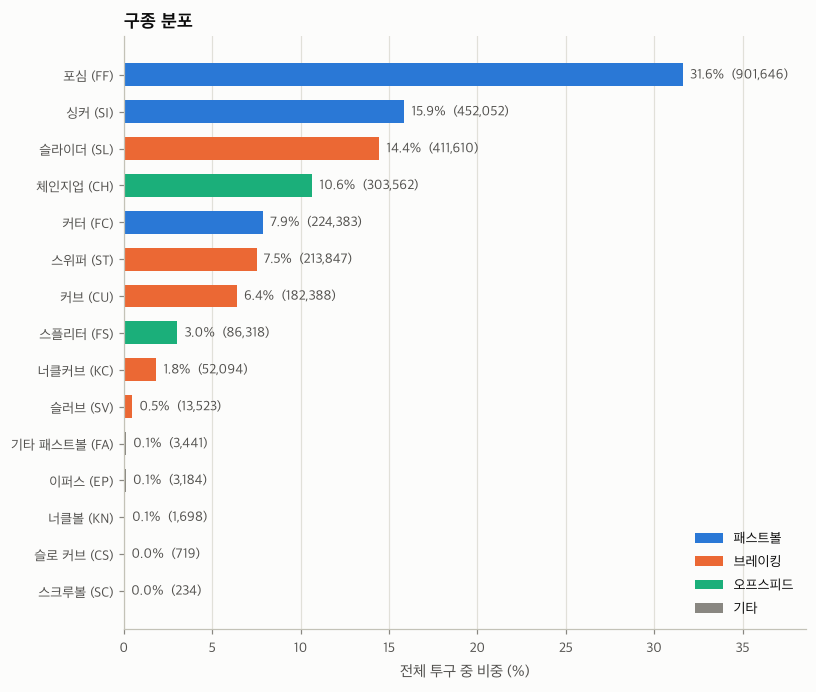

In [36]:
mix = df["pitch_type"].value_counts()
share = mix / mix.sum() * 100
order = list(mix.index[::-1])
groups_of = [cfg.PITCH_GROUPS.get(p, cfg.PITCH_GROUP_OTHER) for p in order]

fig, ax = plt.subplots(figsize=(8, 0.38 * len(order) + 1.3))
ax.barh([plotting.pitch_label(p) for p in order], share[order], height=0.62, color=[plotting.GROUP_COLORS[g] for g in groups_of])
for i, p in enumerate(order):
    ax.text(share[p] + 0.4, i, f"{share[p]:.1f}%  ({mix[p]:,})", va="center", fontsize=9, color=plotting.INK_2)
ax.set_xlim(0, share.max() * 1.22)
ax.set_xlabel("전체 투구 중 비중 (%)")
ax.grid(axis="y", visible=False)
ax.set_title("구종 분포")
plotting.group_legend(ax, ["fastball", "breaking", "offspeed", "other"], loc="lower right")
plotting.save(fig, "02_pitch_mix")
plt.show()

In [37]:
# 클래스 불균형 요약 (구종 분류 대상 클래스만)
cls = df.loc[df["is_pitch_class"], "pitch_type"].value_counts()
print(f"분류 대상 {len(cls)}개 클래스, {cls.sum():,}투구 (전체의 {cls.sum() / len(df) * 100:.2f}%)")
print(f"최다 클래스 {cls.index[0]} {cls.iloc[0]:,} / 최소 클래스 {cls.index[-1]} {cls.iloc[-1]:,} → 비율 {cls.iloc[0] / cls.iloc[-1]:.1f}배")
print(f"다수 클래스만 찍었을 때의 정확도(기준선): {cls.iloc[0] / cls.sum():.3f}")
grp = df["pitch_group"].value_counts()
pd.DataFrame({"투구 수": grp, "비중(%)": (grp / grp.sum() * 100).round(2)}).rename(index=cfg.PITCH_GROUP_LABELS)

분류 대상 10개 클래스, 2,841,423투구 (전체의 99.67%)
최다 클래스 FF 901,646 / 최소 클래스 SV 13,523 → 비율 66.7배
다수 클래스만 찍었을 때의 정확도(기준선): 0.317


,투구 수,비중(%)
pitch_group,,
패스트볼,1578081,55.360
브레이킹,873462,30.640
오프스피드,389880,13.680
기타,9276,0.330


In [38]:
# 투수 한 명이 던지는 구종 수와, 구종별로 그 구종을 던지는 투수 수
per_pitcher = df[df["is_pitch_class"]].groupby("pitcher")["pitch_type"].agg(["size", "nunique"])
print(f"투수 {len(per_pitcher)}명 | 투수당 투구 수 중앙값 {per_pitcher['size'].median():.0f} | 투수당 구종 수 중앙값 {per_pitcher['nunique'].median():.0f}")
by_type = df.groupby("pitch_type").agg(투구수=("pitcher", "size"), 투수수=("pitcher", "nunique"))
by_type["상위1명_비중(%)"] = df.groupby("pitch_type")["pitcher"].agg(lambda s: s.value_counts().iloc[0] / len(s) * 100).round(1)
by_type.sort_values("투구수", ascending=False)

투수 1372명 | 투수당 투구 수 중앙값 1198 | 투수당 구종 수 중앙값 5


,투구수,투수수,상위1명_비중(%)
pitch_type,,,
FF,901646,1295,0.700
SI,452052,1040,1.100
SL,411610,1048,1.200
CH,303562,1016,1.200
FC,224383,668,1.700
ST,213847,618,1.300
CU,182388,673,1.900
FS,86318,264,5.200
KC,52094,93,6.600


## 6. 구종별 물리량 분포

분류 대상 구종만 그린다. 무브먼트는 인치 단위로 바꿨고, 수평 무브먼트는 팔 쪽이 +다.

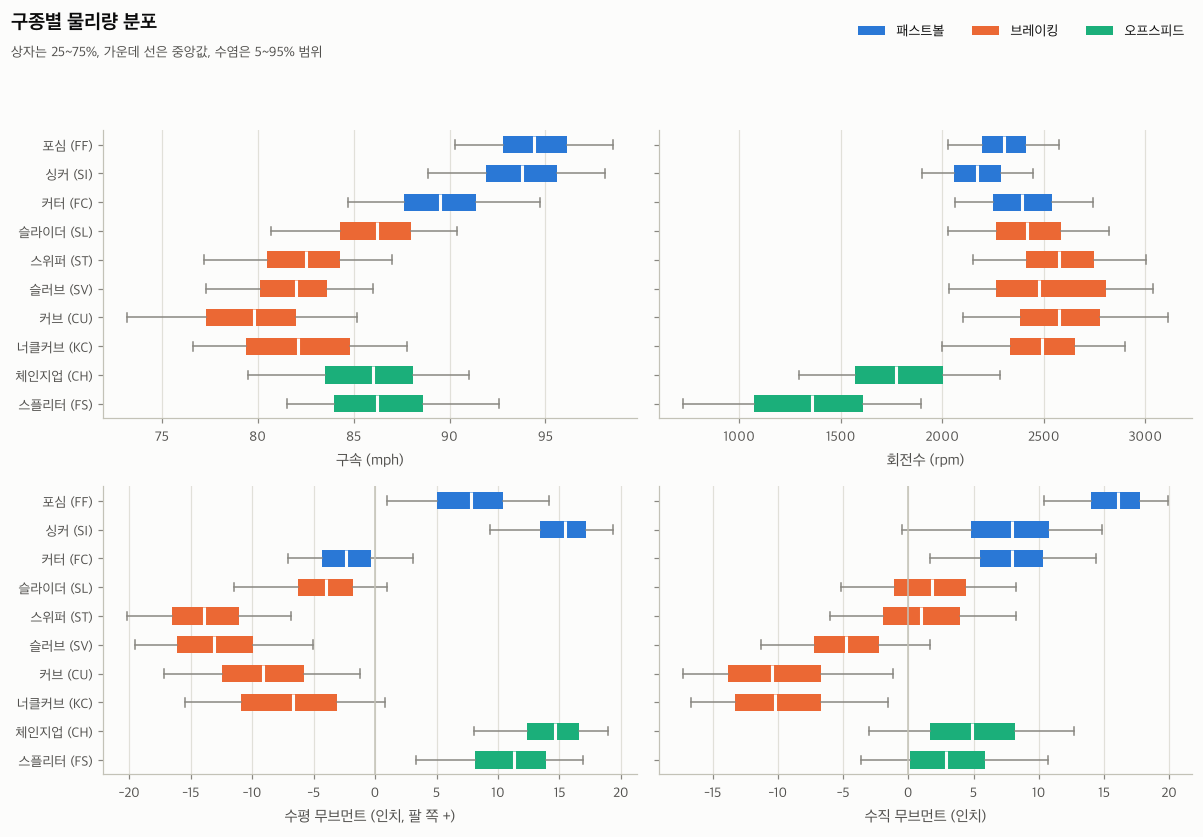

In [39]:
pc = df[df["is_pitch_class"]]
classes = [c for c in cfg.PITCH_CLASSES if c in set(pc["pitch_type"])]
panels = [
    ("release_speed", "구속 (mph)", 1),
    ("release_spin_rate", "회전수 (rpm)", 1),
    ("pfx_x_arm", "수평 무브먼트 (인치, 팔 쪽 +)", 12),
    ("pfx_z", "수직 무브먼트 (인치)", 12),
]
fig, axes = plt.subplots(2, 2, figsize=(11, 7.6), sharey=True)
for ax, (col, label, scale) in zip(axes.ravel(), panels):
    data = [pc.loc[pc["pitch_type"] == c, col].dropna().to_numpy() * scale for c in classes[::-1]]
    box = ax.boxplot(data, orientation="horizontal", widths=0.6, showfliers=False, patch_artist=True, whis=(5, 95),
                     boxprops=dict(linewidth=0), medianprops=dict(color=plotting.SURFACE, linewidth=2),
                     whiskerprops=dict(color=plotting.MUTED, linewidth=1), capprops=dict(color=plotting.MUTED, linewidth=1))
    for patch, c in zip(box["boxes"], classes[::-1]):
        patch.set_facecolor(plotting.GROUP_COLORS[cfg.PITCH_GROUPS[c]])
    ax.set_yticks(range(1, len(classes) + 1), [plotting.pitch_label(c) for c in classes[::-1]])
    ax.set_xlabel(label)
    ax.grid(axis="y", visible=False)
    if col in ("pfx_x_arm", "pfx_z"):
        ax.axvline(0, color=plotting.AXIS, linewidth=1)
fig.suptitle("구종별 물리량 분포", x=0.01, y=0.995, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, 0.94, "상자는 25~75%, 가운데 선은 중앙값, 수염은 5~95% 범위", fontsize=9, color=plotting.INK_2)
handles = [plt.Rectangle((0, 0), 1, 1, color=plotting.GROUP_COLORS[g]) for g in ["fastball", "breaking", "offspeed"]]
fig.legend(handles, [cfg.PITCH_GROUP_LABELS[g] for g in ["fastball", "breaking", "offspeed"]], loc="upper right", bbox_to_anchor=(0.99, 0.995), ncols=3)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plotting.save(fig, "02_physics_by_pitch")
plt.show()

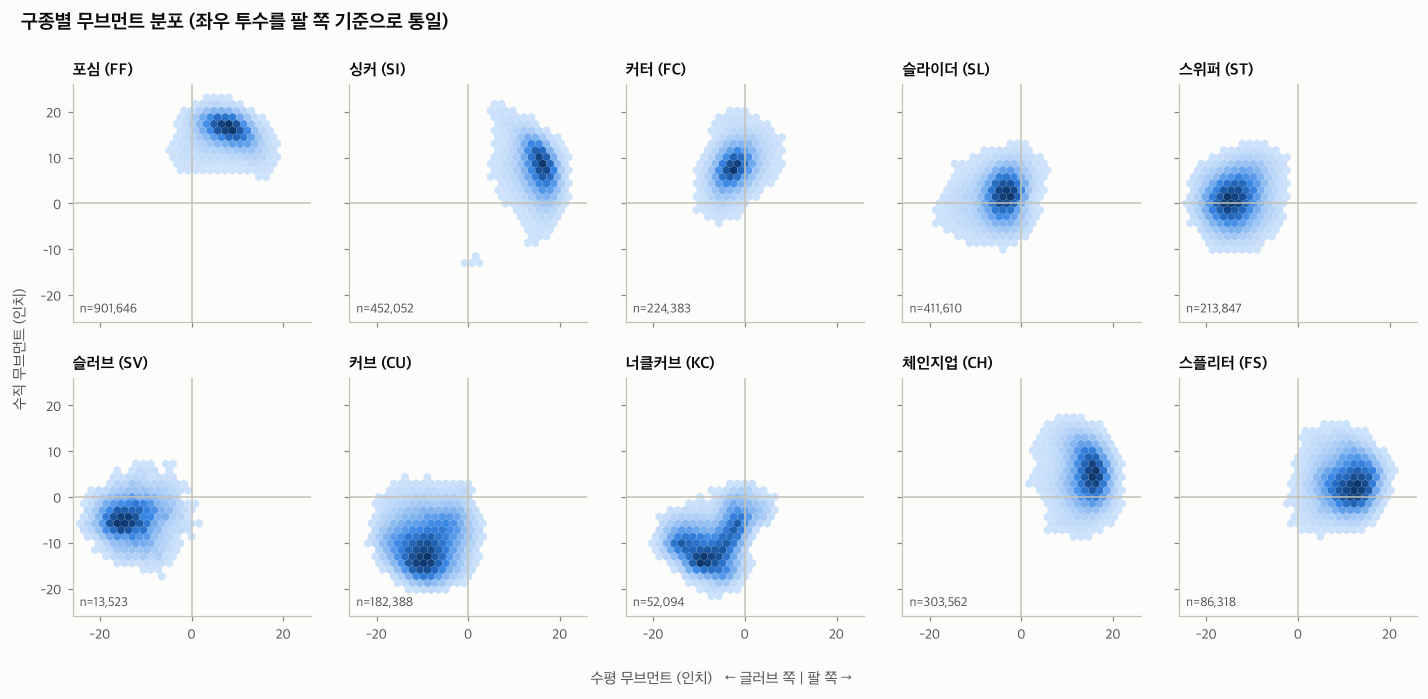

In [40]:
# 무브먼트 평면에서 구종별 분포. 칸의 색은 각 구종 안에서의 상대 빈도다(구종끼리 색 눈금을 공유하지 않는다).
fig, axes = plt.subplots(2, 5, figsize=(13, 6.4), sharex=True, sharey=True, layout="constrained")
lim = 26
for ax, c in zip(axes.ravel(), classes):
    sub = pc[pc["pitch_type"] == c]
    ax.hexbin(sub["pfx_x_arm"] * 12, sub["pfx_z"] * 12, gridsize=32, extent=(-lim, lim, -lim, lim),
              cmap=plotting.SEQ_CMAP, mincnt=max(1, len(sub) // 3000), linewidths=0)
    ax.axhline(0, color=plotting.AXIS, linewidth=1)
    ax.axvline(0, color=plotting.AXIS, linewidth=1)
    ax.set_title(f"{plotting.pitch_label(c)}", fontsize=10.5)
    ax.text(0.03, 0.04, f"n={len(sub):,}", transform=ax.transAxes, fontsize=8.5, color=plotting.INK_2)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.grid(visible=False)
for ax in axes.ravel()[len(classes):]:
    ax.axis("off")
fig.supxlabel("수평 무브먼트 (인치)   ← 글러브 쪽 | 팔 쪽 →", fontsize=10, color=plotting.INK_2)
fig.supylabel("수직 무브먼트 (인치)", fontsize=10, color=plotting.INK_2)
fig.suptitle("구종별 무브먼트 분포 (좌우 투수를 팔 쪽 기준으로 통일)", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.get_layout_engine().set(h_pad=0.12, hspace=0.06)
plotting.save(fig, "02_movement_by_pitch")
plt.show()

## 7. 스윙과 헛스윙

정의는 `config.py`에 있다.

- **스윙**: `SWING_DESCRIPTIONS`에 속한 투구
- **헛스윙**: `swinging_strike`, `swinging_strike_blocked`, 그리고 기본값에서는 `foul_tip`

주 과제는 스윙한 투구 중 헛스윙 확률 P(whiff | swing)이다.

In [41]:
# description 값이 어떤 라벨로 가는지 한눈에 확인
label_map = df.groupby("description").agg(투구수=("is_swing", "size"), is_swing=("is_swing", "first"), is_whiff=("is_whiff", "first"))
display(label_map.sort_values(["is_swing", "is_whiff", "투구수"], ascending=False))
print("등록되지 않은 description:", labels.unknown_descriptions(df["description"]) or "없음")

,투구수,is_swing,is_whiff
description,,,
swinging_strike,298810,1,1
foul_tip,29412,1,1
swinging_strike_blocked,16155,1,1
foul,512923,1,0
hit_into_play,497786,1,0
foul_bunt,5033,1,0
missed_bunt,851,1,0
bunt_foul_tip,93,1,0
ball,955273,0,0


등록되지 않은 description: 없음


In [42]:
n, n_swing, n_whiff = len(df), int(df["is_swing"].sum()), int(df["is_whiff"].sum())
alt = labels.add_swing_whiff(df, include_foul_tip=False)
summary = pd.DataFrame(
    {
        "기본 정의 (foul_tip 포함)": [n, n_swing, n_whiff, n_swing / n, n_whiff / n_swing, n_whiff / n],
        "foul_tip 제외": [n, n_swing, int(alt["is_whiff"].sum()), n_swing / n, alt["is_whiff"].sum() / n_swing, alt["is_whiff"].mean()],
    },
    index=["투구 수", "스윙 수", "헛스윙 수", "스윙률 (스윙/투구)", "P(whiff | swing)", "P(whiff) 전체 투구 기준"],
)
display(summary.style.format("{:,.4f}", subset=pd.IndexSlice[summary.index[3:], :]).format("{:,.0f}", subset=pd.IndexSlice[summary.index[:3], :]))
print(f"클래스 불균형: 스윙 중 헛스윙 {n_whiff / n_swing * 100:.1f}% (약 1:{(n_swing - n_whiff) / n_whiff:.1f}), 전체 투구 중 헛스윙 {n_whiff / n * 100:.1f}% (약 1:{(n - n_whiff) / n_whiff:.1f})")

,기본 정의 (foul_tip 포함),foul_tip 제외
투구 수,"2,850,699","2,850,699"
스윙 수,"1,361,063","1,361,063"
헛스윙 수,"344,377","314,965"
스윙률 (스윙/투구),0.4774,0.4774
P(whiff | swing),0.2530,0.2314
P(whiff) 전체 투구 기준,0.1208,0.1105


클래스 불균형: 스윙 중 헛스윙 25.3% (약 1:3.0), 전체 투구 중 헛스윙 12.1% (약 1:7.3)


In [43]:
# 존 안/밖에 따른 스윙률과 헛스윙률 (zone 1~9는 스트라이크 존 안, 11~14는 밖)
zone_side = np.where(df["zone"] <= 9, "존 안 (1~9)", "존 밖 (11~14)")
zs = df.groupby(zone_side).agg(투구수=("is_swing", "size"), 스윙=("is_swing", "sum"), 헛스윙=("is_whiff", "sum"))
zs["스윙률"] = zs["스윙"] / zs["투구수"]
zs["P(whiff | swing)"] = zs["헛스윙"] / zs["스윙"]
zs

,투구수,스윙,헛스윙,스윙률,P(whiff | swing)
존 밖 (11~14),1449722,420204,183534,0.290,0.437
존 안 (1~9),1400977,940859,160843,0.672,0.171


,swings,whiffs,whiff_rate,whiff_rate_no_foul_tip,group
pitch_type,,,,,
FS,44700,15488,0.346,0.330,offspeed
KC,23153,7907,0.342,0.327,breaking
SL,200978,67328,0.335,0.319,breaking
ST,97115,30743,0.317,0.300,breaking
CH,152848,47398,0.310,0.294,offspeed
CU,75279,23154,0.308,0.293,breaking
SV,5694,1670,0.293,0.280,breaking
KN,730,187,0.256,0.248,other
CS,293,75,0.256,0.239,other


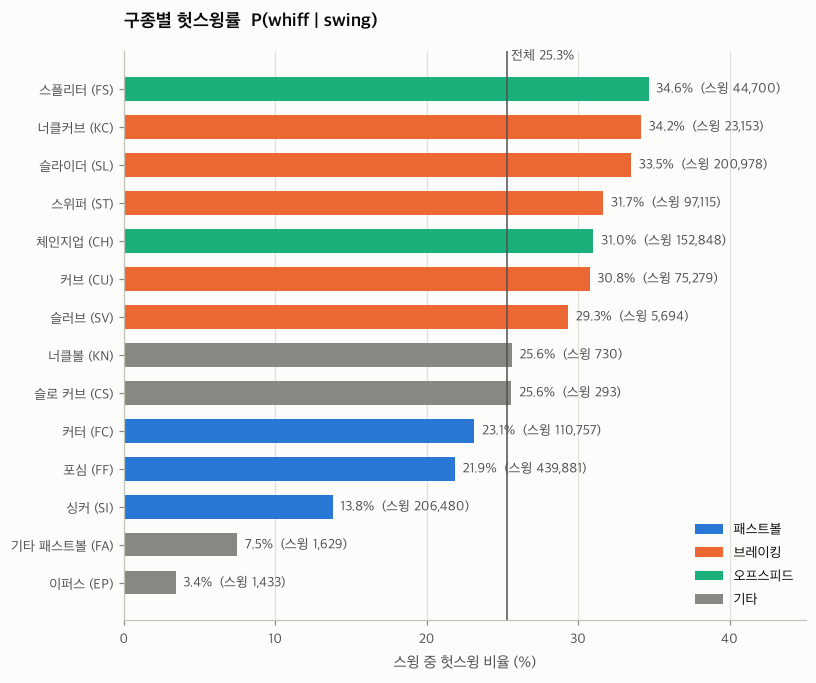

In [44]:
sw = df[df["is_swing"] == 1]
sw_alt = alt[alt["is_swing"] == 1]
by_pitch = sw.groupby("pitch_type").agg(swings=("is_whiff", "size"), whiffs=("is_whiff", "sum"))
by_pitch["whiff_rate"] = by_pitch["whiffs"] / by_pitch["swings"]
by_pitch["whiff_rate_no_foul_tip"] = sw_alt.groupby("pitch_type")["is_whiff"].mean()
by_pitch["group"] = by_pitch.index.map(lambda p: cfg.PITCH_GROUPS.get(p, cfg.PITCH_GROUP_OTHER))
by_pitch = by_pitch.sort_values("whiff_rate", ascending=False)
display(by_pitch)

MIN_SWINGS = 100  # 스윙이 이보다 적은 구종은 그림에서 뺀다 (표에는 있다)
plot = by_pitch[by_pitch["swings"] >= MIN_SWINGS].iloc[::-1]
overall = sw["is_whiff"].mean()

fig, ax = plt.subplots(figsize=(8, 0.38 * len(plot) + 1.4))
ax.barh([plotting.pitch_label(p) for p in plot.index], plot["whiff_rate"] * 100, height=0.62, color=[plotting.GROUP_COLORS[g] for g in plot["group"]])
for i, (p, row) in enumerate(plot.iterrows()):
    ax.text(row["whiff_rate"] * 100 + 0.5, i, f"{row['whiff_rate'] * 100:.1f}%  (스윙 {int(row['swings']):,})", va="center", fontsize=9, color=plotting.INK_2)
ax.axvline(overall * 100, color=plotting.INK_2, linewidth=1)
ax.text(overall * 100, len(plot) - 0.35, f" 전체 {overall * 100:.1f}%", fontsize=9, color=plotting.INK_2, va="bottom")
ax.set_xlim(0, plot["whiff_rate"].max() * 100 * 1.3)
ax.set_xlabel("스윙 중 헛스윙 비율 (%)")
ax.grid(axis="y", visible=False)
ax.set_title("구종별 헛스윙률  P(whiff | swing)", pad=16)
plotting.group_legend(ax, [g for g in ["fastball", "breaking", "offspeed", "other"] if g in set(plot["group"])], loc="lower right")
plotting.save(fig, "02_whiff_by_pitch")
plt.show()

### 위치별 헛스윙률

스윙한 투구를 홈플레이트 통과 위치로 나눠 칸마다 헛스윙률을 계산한다. 좌우는 타자 기준으로 통일했다(좌타자의 `plate_x`를 뒤집어 왼쪽이 항상 몸쪽). 표본이 적은 칸은 비워 둔다. 사각형은 평균 스트라이크 존이다.

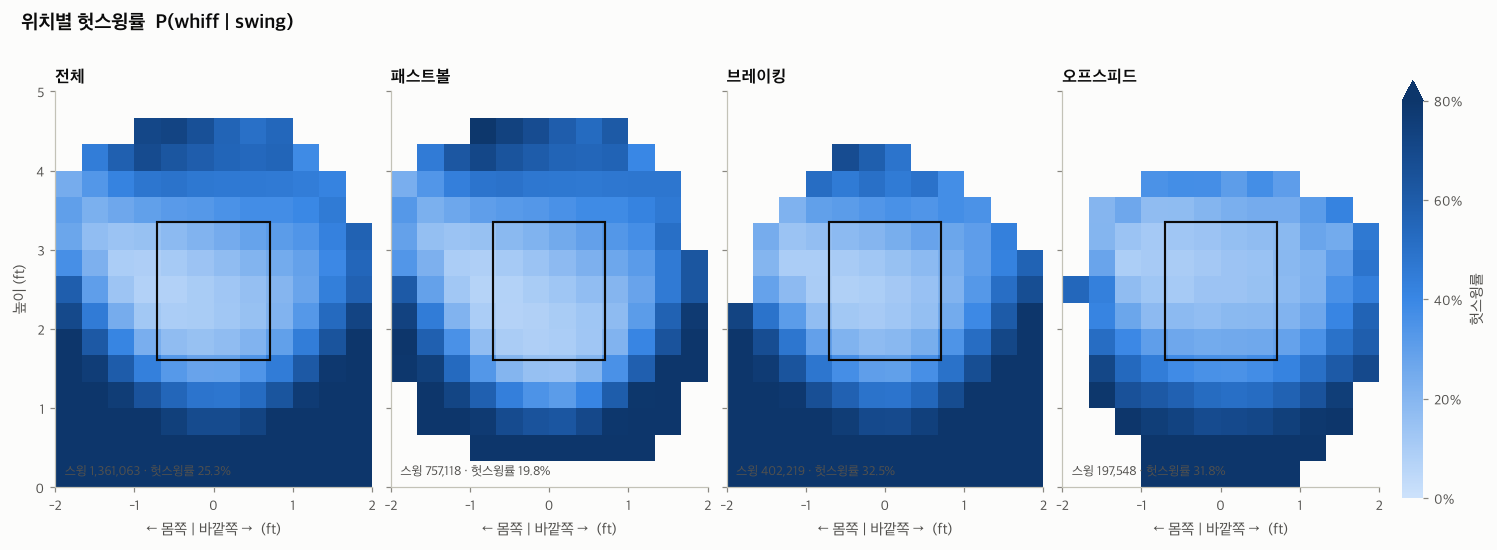

In [45]:
BIN_FT = 1 / 3       # 칸 크기 (ft) = 4인치
MIN_SWINGS_BIN = 25  # 칸에 스윙이 이보다 적으면 비운다
x_edges = np.arange(-2, 2 + 1e-9, BIN_FT)
z_edges = np.arange(0, 5 + 1e-9, BIN_FT)

def whiff_grid(data):
    # 타자 기준 좌우: 우타자는 그대로, 좌타자는 뒤집는다 (음수 = 몸쪽)
    x = np.where(data["stand"] == "L", -data["plate_x"], data["plate_x"])
    swings, _, _ = np.histogram2d(x, data["plate_z"], bins=[x_edges, z_edges])
    whiffs, _, _ = np.histogram2d(x[data["is_whiff"] == 1], data.loc[data["is_whiff"] == 1, "plate_z"], bins=[x_edges, z_edges])
    with np.errstate(invalid="ignore", divide="ignore"):
        rate = whiffs / swings
    return np.ma.masked_where(swings < MIN_SWINGS_BIN, rate).T, swings.T

zone_panels = [("전체", sw)] + [(cfg.PITCH_GROUP_LABELS[g], sw[sw["pitch_group"] == g]) for g in ["fastball", "breaking", "offspeed"]]
grids = [(title, data, *whiff_grid(data)) for title, data in zone_panels]
VMAX = 0.8  # 색 눈금 상한. 이보다 높은 칸은 가장 진한 색으로 그린다
sz_bot, sz_top = sw["sz_bot"].mean(), sw["sz_top"].mean()

fig, axes = plt.subplots(1, 4, figsize=(13.5, 4.9), sharey=True, layout="constrained")
for ax, (title, data, rate, _) in zip(axes, grids):
    im = ax.imshow(rate, origin="lower", extent=(x_edges[0], x_edges[-1], z_edges[0], z_edges[-1]), cmap=plotting.SEQ_CMAP, vmin=0, vmax=VMAX, aspect="equal")
    plotting.draw_zone(ax, sz_bot, sz_top)
    ax.set_title(title, fontsize=11)
    ax.text(0.03, 0.03, f"스윙 {len(data):,} · 헛스윙률 {data['is_whiff'].mean() * 100:.1f}%", transform=ax.transAxes, fontsize=8.5, color=plotting.INK_2)
    ax.set_xlabel("← 몸쪽 | 바깥쪽 →  (ft)")
    ax.grid(visible=False)
axes[0].set_ylabel("높이 (ft)")
cbar = fig.colorbar(im, ax=axes, fraction=0.018, pad=0.015, extend="max", shrink=0.85)
cbar.set_label("헛스윙률", color=plotting.INK_2)
cbar.set_ticks(np.arange(0, VMAX + 0.01, 0.2), labels=[f"{v:.0%}" for v in np.arange(0, VMAX + 0.01, 0.2)])
cbar.outline.set_visible(False)
fig.suptitle("위치별 헛스윙률  P(whiff | swing)", x=0.01, ha="left", fontsize=13, fontweight="bold")
plotting.save(fig, "02_whiff_zone_heatmap")
plt.show()

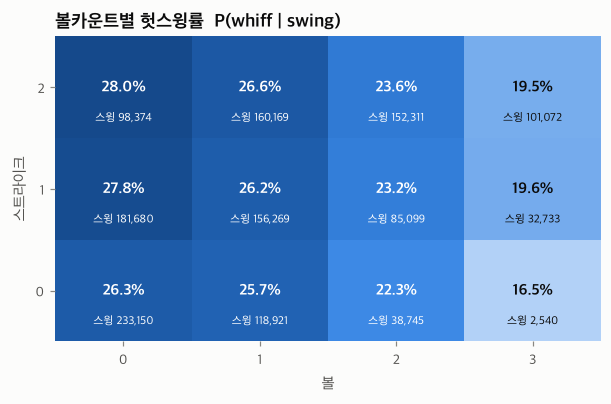

In [46]:
# 볼카운트별 헛스윙률
piv_rate = sw.pivot_table(index="strikes", columns="balls", values="is_whiff", aggfunc="mean")
piv_n = sw.pivot_table(index="strikes", columns="balls", values="is_whiff", aggfunc="size")

fig, ax = plt.subplots(figsize=(6.4, 3.6))
lo, hi = np.floor(piv_rate.values.min() * 20) / 20, np.ceil(piv_rate.values.max() * 20) / 20
im = ax.imshow(piv_rate.values, cmap=plotting.SEQ_CMAP, vmin=lo, vmax=hi, aspect="auto", origin="lower")
for i, s in enumerate(piv_rate.index):
    for j, b in enumerate(piv_rate.columns):
        color = plotting.text_on(plotting.SEQ_CMAP((piv_rate.loc[s, b] - lo) / (hi - lo)))
        ax.text(j, i, f"{piv_rate.loc[s, b] * 100:.1f}%", ha="center", va="center", fontsize=10, color=color, fontweight="bold")
        ax.text(j, i - 0.3, f"스윙 {piv_n.loc[s, b]:,}", ha="center", va="center", fontsize=7.5, color=color)
ax.set_xticks(range(len(piv_rate.columns)), piv_rate.columns)
ax.set_yticks(range(len(piv_rate.index)), piv_rate.index)
ax.set_xlabel("볼"); ax.set_ylabel("스트라이크")
ax.grid(visible=False)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title("볼카운트별 헛스윙률  P(whiff | swing)")
plotting.save(fig, "02_whiff_by_count")
plt.show()

## 8. 저장

다음 단계(피처 엔지니어링)에서 쓸 투구 테이블을 저장한다.

In [47]:
path = preprocess.save_processed(df, "pitches")
print("저장:", Path(path).relative_to(ROOT))
print(f"{len(df):,}행 x {df.shape[1]}열")
print("추가된 컬럼:", [c for c in df.columns if c not in cfg.RAW_COLS])

저장: data/processed/full/pitches.parquet
2,850,699행 x 56열
추가된 컬럼: ['season', 'pitch_type_raw', 'pitch_group', 'is_pitch_class', 'is_swing', 'is_whiff', 'pfx_x_arm', 'release_pos_x_arm', 'vx0_arm', 'ax_arm', 'spin_axis_arm', 'runners_on']


# 3부. 피처 엔지니어링 (원래 `03_features.ipynb`)

02에서 만든 투구 테이블에 피처를 붙인다. 로직은 `src/features.py`에 있다.

**원칙: 어떤 피처도 그 투구가 던져진 시점 이후의 정보를 쓰지 않는다.**
투수·타자별 누적 통계는 전부 "현재 행을 뺀 이전 행들"만으로 계산한다. 이 노트북의 2절에서 실제로 그런지 세 가지 방법으로 확인한다.

In [48]:
%reset -f
# 앞 부의 변수를 모두 비운다 (원래는 노트북마다 새 커널이었다). src 모듈은 그대로 남는다.
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as cfg, plotting
ROOT = cfg.ROOT
from src import features as F, preprocess
plotting.set_style()
pd.set_option("display.max_columns", 60, "display.width", 220, "display.float_format", "{:,.3f}".format)
print("모드:", cfg.mode_name())

모드: full


## 1. 피처 생성

In [49]:
pitches = preprocess.load_processed("pitches")
df = F.build_features(pitches)
print(f"{len(df):,}행 | 입력 {pitches.shape[1]}열 → 출력 {df.shape[1]}열 | 등록된 피처 {len(F.feature_columns())}개")

registry = pd.DataFrame(
    [
        {
            "묶음": g,
            "피처 수": len(cols),
            "구종 라벨에서 파생": "예" if g in F.PITCH_LABEL_DERIVED_GROUPS else "",
            "과거 결과에서 파생": "예" if g in F.PAST_OUTCOME_DERIVED_GROUPS else "",
            "결측률 평균(%)": round(df[cols].isna().mean().mean() * 100, 2),
            "피처": ", ".join(cols),
        }
        for g, cols in F.FEATURE_GROUPS.items()
    ]
).set_index("묶음")
with pd.option_context("display.max_colwidth", 200):
    display(registry)

2,850,699행 | 입력 56열 → 출력 101열 | 등록된 피처 74개


,피처 수,구종 라벨에서 파생,과거 결과에서 파생,결측률 평균(%),피처
묶음,,,,,
physics,18,,,0.110,"release_speed, release_spin_rate, spin_per_mph, spin_axis_sin, spin_axis_cos, pfx_x_arm, pfx_z, release_pos_x_arm, release_pos_y, release_pos_z, release_extension, arm_angle, vx0_arm, vy0, vz0, ax..."
location,9,,,0.000,"plate_x, plate_x_bat, plate_z, plate_z_norm, zone_dist, zone_dist_norm, in_zone, sz_top, sz_bot"
context,16,,,0.000,"balls, strikes, two_strikes, outs_when_up, inning, is_top, on_1b, on_2b, on_3b, runners_on, n_thruorder_pitcher, stand_R, p_throws_R, same_hand, pitch_number, p_game_pitch_count"
prev_physics,7,,,22.090,"has_prev, d_speed, d_pfx_x, d_pfx_z, release_dist, plate_dist, tunnel_ratio"
prev_outcome,3,예,예,25.770,"same_type_as_prev, prev_is_swing, prev_is_whiff"
pitcher_relative,6,,,0.100,"p_n_prior, speed_vs_p_mean, speed_vs_p_max, spin_vs_p_mean, pfx_x_vs_p_mean, pfx_z_vs_p_mean"
pitcher_mix,5,예,,0.090,"p_usage_prior, p_primary_share_prior, is_primary_pitch, p_usage_bucket_prior, p_usage_bucket_lift"
fastball_relative,4,예,,0.320,"fb_speed_prior, speed_vs_fb, pfx_x_vs_fb, pfx_z_vs_fb"
history_outcome,6,예,예,0.140,"p_swings_prior, p_whiff_prior, p_type_swings_prior, p_type_whiff_prior, b_swings_prior, b_whiff_prior"


**묶음별 주의점**

- `구종 라벨에서 파생`인 묶음은 구종 분류 모델의 입력에 쓸 수 없다(정답에서 만든 값이므로). 헛스윙 예측에서는 쓸 수 있다.
- `과거 결과에서 파생`인 묶음은 **이전** 투구들의 스윙/헛스윙만 쓴다. 현재 투구의 결과는 들어가지 않는다.
- `prev_physics` 묶음의 결측은 대부분 타석의 첫 투구라서 생긴다. 나머지 묶음의 결측은 그 투수(타자)의 이전 기록이 아직 없어서 생긴다.

## 2. 누수 점검

### 2-1. 미래 데이터를 지워도 과거 행의 피처가 같은가

전체 데이터로 만든 피처와, 기준일 이전 데이터만으로 만든 피처를 비교한다. 미래 정보가 섞이지 않았다면 기준일 이전 행의 피처는 완전히 같아야 한다.

In [50]:
dates = np.sort(pitches["game_date"].unique())
cutoffs = [str(pd.Timestamp(dates[int(len(dates) * q)]).date()) for q in (0.25, 0.5, 0.75)]
leak1 = pd.DataFrame([F.check_no_future_leak(pitches, c) for c in cutoffs])
display(leak1)
assert all(len(d) == 0 for d in leak1["features_with_diff"]), "미래 정보가 섞인 피처가 있다"
print("통과: 기준일 이전 행의 피처가 모두 동일하다.")

,cutoff,rows_compared,features_compared,features_with_diff
0,2024-03-21,717925,74,{}
1,2025-03-18,1426797,74,{}
2,2026-03-25,2136638,74,{}


통과: 기준일 이전 행의 피처가 모두 동일하다.


### 2-2. 현재 투구의 결과를 바꿔도 그 행의 피처가 같은가

무작위로 고른 행의 `is_swing`, `is_whiff`를 뒤집고 피처를 다시 만든다. 현재 행의 결과를 쓰지 않는다면 뒤집은 행 자신의 피처는 그대로여야 한다.

In [51]:
leak2 = F.check_current_outcome_not_used(pitches)
print(leak2)
assert not leak2["features_with_diff"], "현재 투구의 결과가 들어간 피처가 있다"
print("통과: 현재 투구의 결과는 어떤 피처에도 들어가지 않는다.")

{'rows_flipped': 568, 'features_with_diff': {}}
통과: 현재 투구의 결과는 어떤 피처에도 들어가지 않는다.


### 2-3. 느리지만 단순한 방법으로 다시 계산해 비교

무작위 행에 대해 "이 행보다 앞에 있는 행만 잘라서" 직접 계산한 값과 `features.py`의 결과를 비교한다.

In [52]:
rng = np.random.default_rng(cfg.RANDOM_STATE)
sample_idx = rng.choice(len(df), 300, replace=False)
mismatch, n_checked = {}, 0
for i in sample_idx:
    row, past = df.iloc[i], df.iloc[:i]            # past = 시간상 앞선 행만
    pp = past[past["pitcher"] == row["pitcher"]]
    sw = pp[pp["is_swing"] == 1]
    bb = past[(past["batter"] == row["batter"]) & (past["is_swing"] == 1)]
    expected = {
        "p_n_prior": min(len(pp), cfg.PRIOR_COUNT_CAPS["p_n_prior"]),
        "p_usage_prior": (pp["pitch_type"] == row["pitch_type"]).mean() if len(pp) else np.nan,
        "speed_vs_p_mean": row["release_speed"] - pp["release_speed"].mean() if len(pp) else np.nan,
        "p_swings_prior": min(len(sw), cfg.PRIOR_COUNT_CAPS["p_swings_prior"]),
        "p_whiff_prior": sw["is_whiff"].mean() if len(sw) else np.nan,
        "b_swings_prior": min(len(bb), cfg.PRIOR_COUNT_CAPS["b_swings_prior"]),
        "b_whiff_prior": bb["is_whiff"].mean() if len(bb) else np.nan,
        "p_game_pitch_count": int((pp["game_pk"] == row["game_pk"]).sum()),
    }
    for name, value in expected.items():
        n_checked += 1
        got = float(row[name])
        if not (np.isclose(got, float(value), atol=1e-3) or (np.isnan(got) and np.isnan(float(value)))):
            mismatch.setdefault(name, []).append(int(i))
print(f"비교한 값 {n_checked:,}개 | 불일치: {mismatch or '없음'}")
assert not mismatch

비교한 값 2,400개 | 불일치: 없음


## 3. 피처 점검

In [53]:
# 결측률과 분포 요약
desc = df[F.feature_columns()].describe(percentiles=[0.01, 0.5, 0.99]).T[["count", "mean", "std", "min", "1%", "50%", "99%", "max"]]
desc.insert(0, "결측률(%)", (df[F.feature_columns()].isna().mean() * 100).round(2))
desc.insert(0, "묶음", [g for g, cols in F.FEATURE_GROUPS.items() for _ in cols])
print("무한대 값:", int(np.isinf(df[F.feature_columns()].to_numpy(dtype="float64")).sum()))
with pd.option_context("display.max_rows", 100):
    display(desc)

무한대 값: 0


,묶음,결측률(%),count,mean,std,min,1%,50%,99%,max
release_speed,physics,0.000,"2,850,693.000",89.286,6.112,30.300,74.400,90.100,99.400,105.500
release_spin_rate,physics,0.360,"2,840,410.000","2,262.087",359.201,2.000,"1,074.000","2,296.000","3,021.000","3,599.000"
spin_per_mph,physics,0.360,"2,840,406.000",25.460,4.610,0.023,12.684,24.978,37.215,86.705
spin_axis_sin,physics,0.360,"2,840,409.000",0.209,0.652,-1.000,-0.999,0.485,0.995,1.000
spin_axis_cos,physics,0.360,"2,840,409.000",-0.425,0.593,-1.000,-0.999,-0.695,0.946,1.000
pfx_x_arm,physics,0.000,"2,850,561.000",0.339,0.843,-2.950,-1.570,0.510,1.630,2.760
pfx_z,physics,0.000,"2,850,694.000",0.578,0.712,-2.450,-1.300,0.620,1.700,2.840
release_pos_x_arm,physics,0.000,"2,850,695.000",1.917,0.736,-1.210,0.240,1.900,3.830,5.140
release_pos_y,physics,0.000,"2,850,695.000",54.060,0.458,48.760,52.990,54.050,55.160,57.800
release_pos_z,physics,0.000,"2,850,695.000",5.755,0.523,0.760,4.250,5.800,6.820,8.250


In [54]:
# 이력이 얼마나 쌓였는가. 횟수 피처는 config.PRIOR_COUNT_CAPS의 상한에서 포화된다.
print("상한:", cfg.PRIOR_COUNT_CAPS)
swing_rows = df[df["is_swing"] == 1]
hist = pd.DataFrame(
    {
        "투수 이전 투구 수": df["p_n_prior"].describe(percentiles=[0.1, 0.5, 0.9]),
        "투수 이전 스윙 수 (스윙 행)": swing_rows["p_swings_prior"].describe(percentiles=[0.1, 0.5, 0.9]),
        "투수x구종 이전 스윙 수 (스윙 행)": swing_rows["p_type_swings_prior"].describe(percentiles=[0.1, 0.5, 0.9]),
        "타자 이전 스윙 수 (스윙 행)": swing_rows["b_swings_prior"].describe(percentiles=[0.1, 0.5, 0.9]),
    }
).round(1)
hist

상한: {'p_n_prior': 200, 'p_swings_prior': 200, 'p_type_swings_prior': 100, 'b_swings_prior': 200}


,투수 이전 투구 수,투수 이전 스윙 수 (스윙 행),투수x구종 이전 스윙 수 (스윙 행),타자 이전 스윙 수 (스윙 행)
count,"2,850,699.000","1,361,063.000","1,361,063.000","1,361,063.000"
mean,190.700,182.000,82.700,186.600
std,34.400,46.500,30.600,40.600
min,0.000,0.000,0.000,0.000
10%,200.000,110.000,24.000,152.000
50%,200.000,200.000,100.000,200.000
90%,200.000,200.000,100.000,200.000
max,200.000,200.000,100.000,200.000


In [55]:
# 직전 투구 비교가 불가능한 이유 분해
first = df["pitch_number"] == 1
print(f"has_prev = 0 인 행: {int((df['has_prev'] == 0).sum()):,} ({(df['has_prev'] == 0).mean() * 100:.2f}%)")
print(f"  타석의 첫 투구            : {int(first.sum()):,}")
print(f"  그 외 (앞 투구가 빠졌거나 투수 교체): {int(((df['has_prev'] == 0) & ~first).sum()):,}")

has_prev = 0 인 행: 734,497 (25.77%)
  타석의 첫 투구            : 731,780
  그 외 (앞 투구가 빠졌거나 투수 교체): 2,717


### 학습 구간과 테스트 구간의 분포 차이

시간으로 나눴을 때 피처의 분포가 학습 구간과 테스트 구간에서 크게 다르면, 모델이 학습 때 보지 못한 범위에서 예측하게 된다. 누적 횟수처럼 시간이 갈수록 커지는 값이 대표적이다. 각 피처의 중앙값 차이를 학습 구간의 사분위 범위(IQR)로 나눠 큰 순서로 본다. 1에 가깝거나 넘으면 분포가 통째로 옮겨 간 것이다.

In [56]:
from src import splits

train_mask, test_mask = splits.time_split(df)
shift_rows = []
for col in F.feature_columns():
    a, b = df.loc[train_mask, col].astype("float64"), df.loc[test_mask, col].astype("float64")
    iqr = a.quantile(0.75) - a.quantile(0.25)
    shift_rows.append({
        "피처": col, "학습 중앙값": a.median(), "테스트 중앙값": b.median(),
        "중앙값 차이 / 학습 IQR": (b.median() - a.median()) / iqr if iqr > 0 else np.nan,
        "테스트 중 학습 범위 밖(%)": ((b > a.max()) | (b < a.min())).mean() * 100,
    })
shift = pd.DataFrame(shift_rows).set_index("피처")
shift = shift.reindex(shift["중앙값 차이 / 학습 IQR"].abs().sort_values(ascending=False).index)
print(f"학습 {int(train_mask.sum()):,}행 / 테스트 {int(test_mask.sum()):,}행")
shift.head(10).round(3)

학습 2,136,638행 / 테스트 714,061행


,학습 중앙값,테스트 중앙값,중앙값 차이 / 학습 IQR,테스트 중 학습 범위 밖(%)
피처,,,,
sz_top,3.400,3.210,-0.735,0.000
release_extension,6.500,6.400,-0.167,0.000
p_primary_share_prior,0.429,0.403,-0.164,0.000
p_usage_bucket_prior,0.313,0.274,-0.147,0.000
p_usage_prior,0.302,0.266,-0.145,0.000
sz_bot,1.600,1.620,0.137,0.000
fb_speed_prior,94.064,94.455,0.127,0.000
pfx_z_vs_fb,-0.290,-0.376,-0.086,0.000
release_pos_z,5.810,5.760,-0.083,0.000


## 4. 피처와 헛스윙의 관계 미리 보기

모델을 만들기 전에, 새로 만든 피처가 헛스윙과 관계가 있는지 스윙한 투구만으로 본다.

### 4-1. 2스트라이크에서 구종 구성이 어떻게 달라지는가

bucket,2스트라이크 이전 (%),2스트라이크 (%),변화 (%p)
pitch_type,,,
SI,18.030,10.950,-7.090
FC,8.910,5.530,-3.380
SV,0.440,0.550,0.110
FF,31.650,31.910,0.260
KC,1.630,2.310,0.680
CU,6.030,7.320,1.290
FS,2.540,4.190,1.650
CH,10.150,11.940,1.800
SL,13.790,16.110,2.320


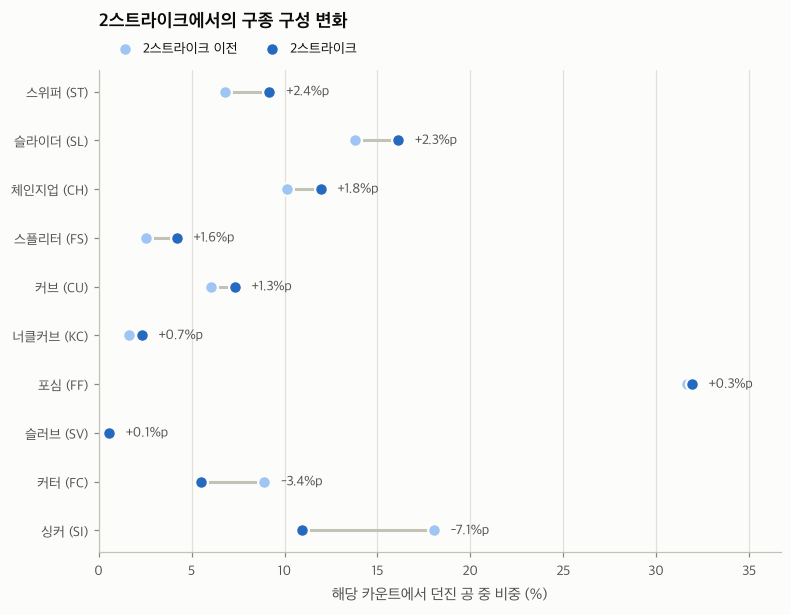

In [57]:
pc = df[df["is_pitch_class"]].copy()
pc["bucket"] = np.where(pc["strikes"] == 2, "two_strike", "other")
usage = pd.crosstab(pc["pitch_type"], pc["bucket"], normalize="columns") * 100
usage["change"] = usage["two_strike"] - usage["other"]
usage = usage.sort_values("change")
display(usage.round(2).rename(columns={"other": "2스트라이크 이전 (%)", "two_strike": "2스트라이크 (%)", "change": "변화 (%p)"}))

LIGHT, DARK = plotting.SEQ_STEPS[1], plotting.SEQ_STEPS[4]
fig, ax = plt.subplots(figsize=(8, 0.42 * len(usage) + 1.5))
y = np.arange(len(usage))
ax.hlines(y, usage["other"], usage["two_strike"], color=plotting.AXIS, linewidth=2, zorder=1)
ax.scatter(usage["other"], y, s=70, color=LIGHT, edgecolor=plotting.SURFACE, linewidth=1.5, zorder=2, label="2스트라이크 이전")
ax.scatter(usage["two_strike"], y, s=70, color=DARK, edgecolor=plotting.SURFACE, linewidth=1.5, zorder=3, label="2스트라이크")
for i, (p, row) in enumerate(usage.iterrows()):
    ax.text(max(row["other"], row["two_strike"]) + 0.9, i, f"{row['change']:+.1f}%p", va="center", fontsize=9, color=plotting.INK_2)
ax.set_yticks(y, [plotting.pitch_label(p) for p in usage.index])
ax.set_xlabel("해당 카운트에서 던진 공 중 비중 (%)")
ax.set_xlim(0, usage[["other", "two_strike"]].max().max() * 1.15)
ax.grid(axis="y", visible=False)
ax.set_title("2스트라이크에서의 구종 구성 변화", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=2, handletextpad=0.3, columnspacing=1.5)
plotting.save(fig, "03_usage_two_strike")
plt.show()

### 4-2. 존 중심에서 멀어질수록 헛스윙률이 어떻게 변하는가

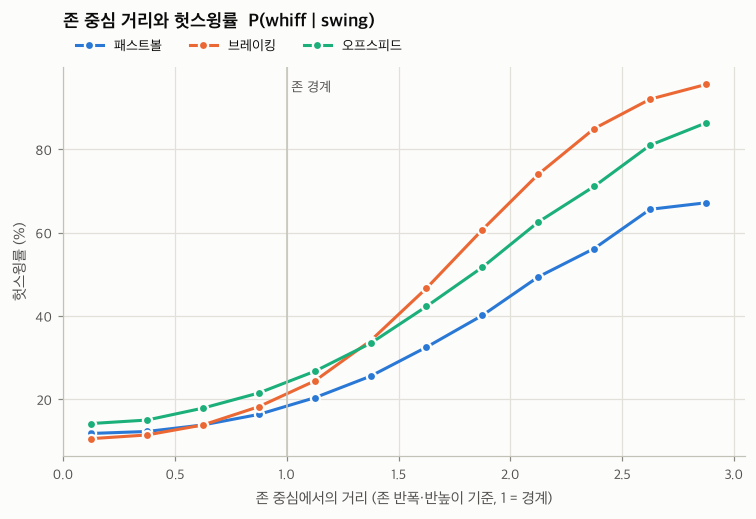

,패스트볼,브레이킹,오프스피드
0.00~0.25,11.800,10.500,14.200
0.25~0.50,12.200,11.400,15.000
0.50~0.75,13.800,13.800,17.800
0.75~1.00,16.300,18.200,21.500
1.00~1.25,20.300,24.400,26.700
1.25~1.50,25.500,34.000,33.400
1.50~1.75,32.500,46.600,42.300
1.75~2.00,40.100,60.700,51.700
2.00~2.25,49.400,74.000,62.500
2.25~2.50,56.200,85.000,71.100


In [58]:
sw = df[df["is_swing"] == 1]
edges = np.arange(0, 3.01, 0.25)
mids = (edges[:-1] + edges[1:]) / 2
MIN_N = 100
groups = ["fastball", "breaking", "offspeed"]

fig, ax = plt.subplots(figsize=(8, 4.6))
table = {}
for g in groups:
    sub = sw[sw["pitch_group"] == g]
    binned = sub.groupby(pd.cut(sub["zone_dist_norm"], edges), observed=False)["is_whiff"].agg(["mean", "size"])
    rate = binned["mean"].where(binned["size"] >= MIN_N).to_numpy() * 100
    table[cfg.PITCH_GROUP_LABELS[g]] = rate
    ax.plot(mids, rate, color=plotting.GROUP_COLORS[g], marker="o", markersize=6, markeredgecolor=plotting.SURFACE, markeredgewidth=1.5, label=cfg.PITCH_GROUP_LABELS[g])
ax.axvline(1, color=plotting.AXIS, linewidth=1)
ax.text(1.02, ax.get_ylim()[1] * 0.97, "존 경계", fontsize=9, color=plotting.INK_2, va="top")
ax.set_xlabel("존 중심에서의 거리 (존 반폭·반높이 기준, 1 = 경계)")
ax.set_ylabel("헛스윙률 (%)")
ax.set_xlim(0, 3.05)
ax.set_title("존 중심 거리와 헛스윙률  P(whiff | swing)", pad=26)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=3)
plotting.save(fig, "03_whiff_by_zone_dist")
plt.show()
pd.DataFrame(table, index=[f"{a:.2f}~{b:.2f}" for a, b in zip(edges[:-1], edges[1:])]).round(1)

### 4-3. 직전 투구·기준 패스트볼과의 차이, 타자 이력

각 피처를 10분위로 나눠 구간별 헛스윙률을 본다. 가로축은 각 구간의 중앙값이다.

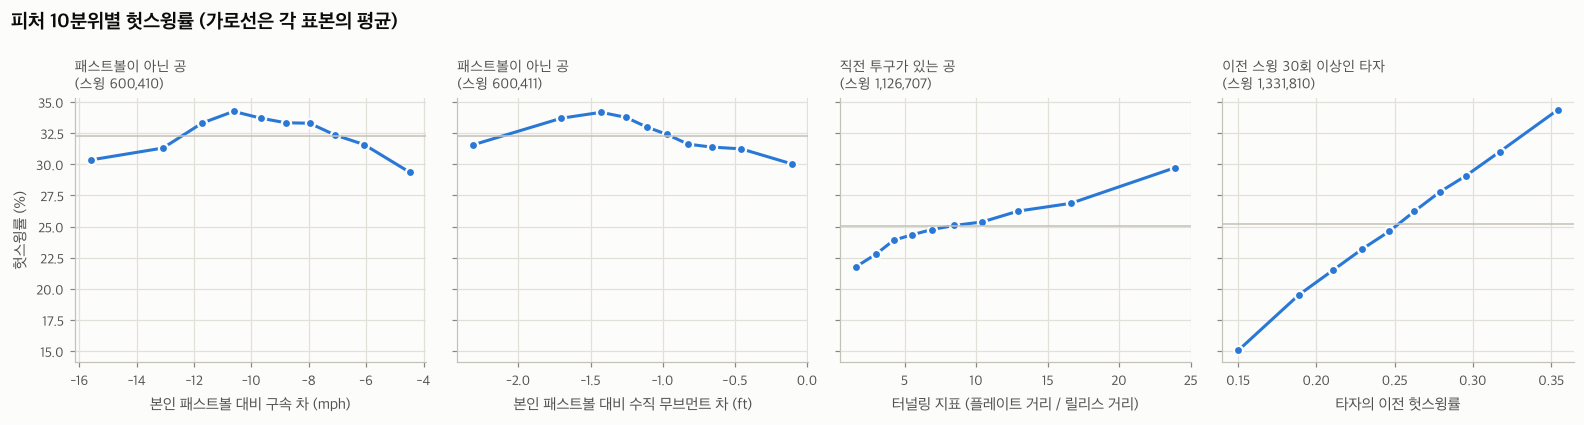

speed_vs_fb              pfx_z_vs_fb              tunnel_ratio               b_whiff_prior              
            x whiff      n           x whiff      n            x whiff       n             x whiff       n
0     -15.608 0.304  60041      -2.312 0.316  60042        1.588 0.218  112671         0.150 0.151  133183
1     -13.086 0.313  60041      -1.702 0.337  60041        3.007 0.228  112671         0.189 0.195  133200
2     -11.720 0.333  60041      -1.427 0.342  60041        4.241 0.239  112670         0.211 0.215  133167
3     -10.625 0.342  60041      -1.254 0.338  60041        5.505 0.243  112671         0.229 0.232  133175
4      -9.679 0.337  60041      -1.110 0.330  60041        6.889 0.248  112671         0.247 0.246  133180
5      -8.811 0.333  60041      -0.970 0.324  60041        8.483 0.251  112670         0.263 0.262  133196
6      -7.973 0.333  60041      -0.825 0.316  60041       10.426 0.254  112671         0.279 0.278  133166
7      -7.093 0.324  60041      -0.662 0.314  60041       12.938 0.262  112670         0.295 0.291  133193
8      -6.070 0.316  60042      -0.456 0.312  60041       16.619 0.269  112671         0.317 0.310  133177
9      -4.475 0.294  60040      -0.102 0.300  60041       23.912 0.297  112671         0.354 0.344  133173

In [59]:
panels = [
    ("speed_vs_fb", "본인 패스트볼 대비 구속 차 (mph)", sw[sw["pitch_group"] != "fastball"], "패스트볼이 아닌 공"),
    ("pfx_z_vs_fb", "본인 패스트볼 대비 수직 무브먼트 차 (ft)", sw[sw["pitch_group"] != "fastball"], "패스트볼이 아닌 공"),
    ("tunnel_ratio", "터널링 지표 (플레이트 거리 / 릴리스 거리)", sw[sw["has_prev"] == 1], "직전 투구가 있는 공"),
    ("b_whiff_prior", "타자의 이전 헛스윙률", sw[sw["b_swings_prior"] >= 30], "이전 스윙 30회 이상인 타자"),
]
fig, axes = plt.subplots(1, 4, figsize=(14.5, 3.9), sharey=True)
decile_tables = {}
for ax, (col, label, data, note) in zip(axes, panels):
    data = data.dropna(subset=[col])
    q = pd.qcut(data[col], 10, duplicates="drop")
    stat = data.groupby(q, observed=True).agg(x=(col, "median"), whiff=("is_whiff", "mean"), n=("is_whiff", "size"))
    decile_tables[col] = stat.reset_index(drop=True)
    ax.plot(stat["x"], stat["whiff"] * 100, color=plotting.BLUE, marker="o", markersize=6, markeredgecolor=plotting.SURFACE, markeredgewidth=1.5)
    ax.axhline(data["is_whiff"].mean() * 100, color=plotting.AXIS, linewidth=1)
    ax.set_xlabel(label)
    ax.set_title(f"{note}\n(스윙 {len(data):,})", fontsize=9.5, fontweight="normal", color=plotting.INK_2)
axes[0].set_ylabel("헛스윙률 (%)")
fig.suptitle("피처 10분위별 헛스윙률 (가로선은 각 표본의 평균)", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
plotting.save(fig, "03_whiff_by_feature_deciles")
plt.show()
pd.concat(decile_tables, axis=1).round(3)

## 5. 저장

In [60]:
path = cfg.processed_path("features")
df.to_parquet(path, index=False)
print("저장:", path.relative_to(ROOT), f"| {len(df):,}행 x {df.shape[1]}열 | {path.stat().st_size / 1e6:.1f} MB")

저장: data/processed/full/features.parquet | 2,850,699행 x 101열 | 606.8 MB


# 4부. 구종 분류 모델 (원래 `04_pitch_type_model.ipynb`)

**목표**: 투구 물리량(구속, 회전수, 회전축, 무브먼트, 릴리스 포인트)만으로 `pitch_type`을 예측한다.

**순서**
0. 누수 점검
1. 데이터와 시간 기준 분할
2. 베이스라인(다수 클래스, 로지스틱 회귀, 랜덤 포레스트)과 주력 모델(HistGradientBoosting) 비교
3. 시계열 교차검증으로 HGB 튜닝
4. 최종 모델 평가: 정확도, macro-F1, 클래스별 재현율, 혼동 행렬, 헷갈리는 구종 쌍
5. 상위 그룹(패스트볼/브레이킹/오프스피드)으로 합친 결과
6. 투수 ID 사용 여부와 처음 보는 투수에 대한 일반화 (GroupKFold)
7. 해석: permutation importance, 투수별 정확도

모든 수치는 **테스트 구간**(학습에 쓰지 않은 가장 최근 기간) 기준이다. 튜닝은 학습 구간 안에서만 한다.

In [61]:
%reset -f
# 앞 부의 변수를 모두 비운다 (원래는 노트북마다 새 커널이었다). src 모듈은 그대로 남는다.
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as cfg, plotting
ROOT = cfg.ROOT
import dataclasses
import time

from sklearn.dummy import DummyClassifier

from src import datasets, evaluate as E, features as F, interpret, leakage, models, splits, tuning
plotting.set_style()
pd.set_option("display.max_columns", 60, "display.width", 220, "display.float_format", "{:,.3f}".format)
print("모드:", cfg.mode_name())

모드: full


## 0. 누수 점검

입력 규칙과 분할 규칙이 지켜지는지 먼저 확인한다. 하나라도 실패하면 여기서 멈춘다.

In [62]:
df = datasets.load_features()
audit = leakage.assert_audit_passes(df)
print(f"누수 점검 {len(audit)}개 모두 통과")
audit[audit["점검"].str.startswith(("구종 분류", "시간 분할", "GroupKFold"))]

누수 점검 27개 모두 통과


,점검,통과,내용
1,"구종 분류 입력에 라벨 파생 피처가 없다 [physics, 투수 ID=X]",True,입력 18개
2,"구종 분류 입력에 라벨 파생 피처가 없다 [physics, 투수 ID=O]",True,입력 19개
3,"구종 분류 입력에 라벨 파생 피처가 없다 [physics+relative, 투수 I...",True,입력 24개
4,"구종 분류 입력에 라벨 파생 피처가 없다 [physics+relative, 투수 I...",True,입력 25개
10,구종 분류: pitch_name을 넣으면 거부된다,True,
11,구종 분류: 라벨 파생 피처(p_usage_prior)를 넣으면 거부된다,True,
12,구종 분류: 기준 패스트볼 대비 피처(speed_vs_fb)를 넣으면 거부된다,True,
23,시간 분할: 학습 구간이 테스트 구간보다 앞선다,True,"학습 ~2025-09-28 (1,020,491행) / 테스트 2026-03-25~ ..."
24,시간 분할: 학습과 테스트에 같은 경기가 없다,True,
26,GroupKFold: 검증 폴드의 투수가 학습 폴드에 한 명도 없다,True,"5개 폴드, 투수 1372명"


## 1. 데이터와 분할

In [63]:
data = datasets.pitch_type_data(df, "physics")
train, test = splits.time_split(data.meta)
LABELS = [c for c in cfg.PITCH_CLASSES if c in set(data.y)]
dates = data.meta["game_date"]

print(data.description)
print(f"입력 피처 {len(data.numeric)}개: {data.numeric}")
print(f"학습 : {int(train.sum()):,}행 | {dates[train].min().date()} ~ {dates[train].max().date()} | 투수 {data.meta.loc[train, 'pitcher'].nunique()}명")
print(f"테스트: {int(test.sum()):,}행 | {dates[test].min().date()} ~ {dates[test].max().date()} | 투수 {data.meta.loc[test, 'pitcher'].nunique()}명")
new_pitchers = ~data.meta.loc[test, "pitcher"].isin(set(data.meta.loc[train, "pitcher"]))
print(f"테스트 투구 중 학습 구간에 없던 투수의 공: {int(new_pitchers.sum()):,}행 ({new_pitchers.mean() * 100:.1f}%)")

dist = pd.DataFrame({"학습 비중(%)": data.y[train].value_counts(normalize=True) * 100, "테스트 비중(%)": data.y[test].value_counts(normalize=True) * 100, "테스트 건수": data.y[test].value_counts()}).loc[LABELS]
dist.round(2)

구종 분류 | 입력 묶음=physics | 투수 ID=미사용
입력 피처 18개: ['release_speed', 'release_spin_rate', 'spin_per_mph', 'spin_axis_sin', 'spin_axis_cos', 'pfx_x_arm', 'pfx_z', 'release_pos_x_arm', 'release_pos_y', 'release_pos_z', 'release_extension', 'arm_angle', 'vx0_arm', 'vy0', 'vz0', 'ax_arm', 'ay', 'az']
학습 : 2,129,722행 | 2023-03-30 ~ 2025-09-28 | 투수 1205명
테스트: 711,701행 | 2026-03-25 ~ 2026-09-27 | 투수 825명
테스트 투구 중 학습 구간에 없던 투수의 공: 68,004행 (9.6%)


,학습 비중(%),테스트 비중(%),테스트 건수
pitch_type,,,
FF,32.050,30.800,219175
SI,15.650,16.690,118818
FC,7.850,8.040,57232
SL,14.950,13.110,93281
ST,7.240,8.370,59566
SV,0.480,0.450,3213
CU,6.430,6.380,45398
KC,1.900,1.640,11688
CH,10.510,11.210,79814


## 2. 베이스라인과 주력 모델

같은 학습 행(`config.COMPARE_MAX_TRAIN_ROWS` 이하)으로 네 모델을 학습해 테스트 구간에서 비교한다. HGB는 여기서 기본 설정이다.

In [64]:
compare_train = E.limit_train(train, cfg.COMPARE_MAX_TRAIN_ROWS)
X_te, y_te = data.X[test], data.y[test]

def fit_and_score(name, pipe, d=data, tr=compare_train):
    start = time.time()
    pipe.fit(d.X[tr], d.y[tr])
    pred = pipe.predict(d.X[test])
    return pipe, pred, {"모델": name, "학습 행": int(tr.sum()), **E.multiclass_metrics(d.y[test], pred), "학습+예측(초)": round(time.time() - start, 1)}

rows, preds = [], {}
for name, pipe in [
    ("다수 클래스", DummyClassifier(strategy="most_frequent")),
    ("로지스틱 회귀", models.make_pipeline("logreg", data)),
    ("랜덤 포레스트", models.make_pipeline("rf", data, max_samples=models.rf_max_samples(int(compare_train.sum())))),
    ("HGB (기본 설정)", models.make_pipeline("hgb", data)),
]:
    _, preds[name], row = fit_and_score(name, pipe)
    rows.append(row)
baseline_table = pd.DataFrame(rows).set_index("모델")
baseline_table

,학습 행,accuracy,macro_f1,학습+예측(초)
모델,,,,
다수 클래스,500000,0.308,0.047,1.800
로지스틱 회귀,500000,0.843,0.664,17.200
랜덤 포레스트,500000,0.865,0.703,14.600
HGB (기본 설정),500000,0.845,0.700,42.100


## 3. HGB 튜닝 (시계열 교차검증)

학습 구간 안에서 날짜 블록 시계열 교차검증을 한다. 각 폴드에서 학습 구간은 항상 검증 구간보다 앞선다. 선택 기준은 폴드 평균 log loss다.

In [65]:
start = time.time()
tune_summary, best_params = tuning.tune_hgb(data, train)
print(f"튜닝에 쓴 행: {tune_summary.attrs['rows_used']:,} | 후보 {len(cfg.HGB_GRID)}개 x 폴드 {cfg.N_TIME_SPLITS}개 | {time.time() - start:.0f}초")
print("선택된 설정:", best_params)
tune_summary.head(8)

튜닝에 쓴 행: 300,000 | 후보 6개 x 폴드 4개 | 854초
선택된 설정: {'learning_rate': 0.05, 'max_leaf_nodes': 63, 'max_iter': 100}


,learning_rate,max_leaf_nodes,max_iter,log_loss,accuracy,macro_f1,log_loss_std
0,0.050,63,100,0.342,0.876,0.779,0.011
1,0.050,15,400,0.343,0.875,0.781,0.008
2,0.050,15,300,0.347,0.873,0.775,0.006
3,0.050,63,150,0.350,0.878,0.782,0.017
4,0.050,15,200,0.354,0.869,0.770,0.005
5,0.050,31,100,0.356,0.869,0.765,0.008
6,0.050,15,150,0.360,0.866,0.764,0.006
7,0.050,31,150,0.372,0.872,0.771,0.058


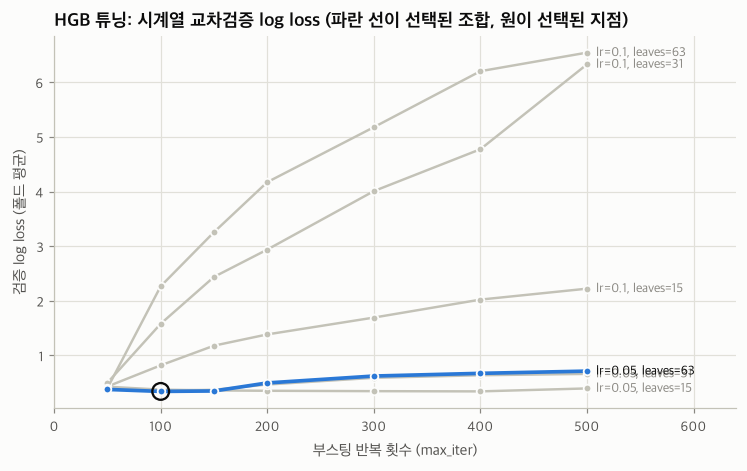

In [66]:
fig, ax = plt.subplots(figsize=(8, 4.4))
plotting.tuning_curve(ax, tune_summary, best_params)
ax.set_title("HGB 튜닝: 시계열 교차검증 log loss (파란 선이 선택된 조합, 원이 선택된 지점)")
plotting.save(fig, "04_tuning_curve")
plt.show()

## 4. 최종 모델 평가

선택된 설정으로 학습 구간 **전체**를 써서 다시 학습하고, 테스트 구간에서 평가한다.

In [67]:
start = time.time()
final = models.make_pipeline("hgb", data, **best_params).fit(data.X[train], data.y[train])
pred = final.predict(X_te)
proba = final.predict_proba(X_te)
final_metrics = E.multiclass_metrics(y_te, pred)
print(f"학습 {int(train.sum()):,}행, {time.time() - start:.0f}초")

summary_table = pd.concat([
    baseline_table[["학습 행", "accuracy", "macro_f1"]],
    pd.DataFrame({"학습 행": int(train.sum()), **final_metrics}, index=["HGB (튜닝, 학습 전체)"]),
])
summary_table

학습 2,129,722행, 60초


,학습 행,accuracy,macro_f1
다수 클래스,500000,0.308,0.047
로지스틱 회귀,500000,0.843,0.664
랜덤 포레스트,500000,0.865,0.703
HGB (기본 설정),500000,0.845,0.700
"HGB (튜닝, 학습 전체)",2129722,0.876,0.746


,precision,recall,f1,support
FF,0.953,0.975,0.964,219175
SI,0.939,0.933,0.936,118818
FC,0.792,0.745,0.768,57232
SL,0.774,0.848,0.809,93281
ST,0.879,0.840,0.859,59566
SV,0.319,0.180,0.230,3213
CU,0.834,0.795,0.814,45398
KC,0.596,0.538,0.566,11688
CH,0.871,0.880,0.876,79814
FS,0.685,0.594,0.636,23516


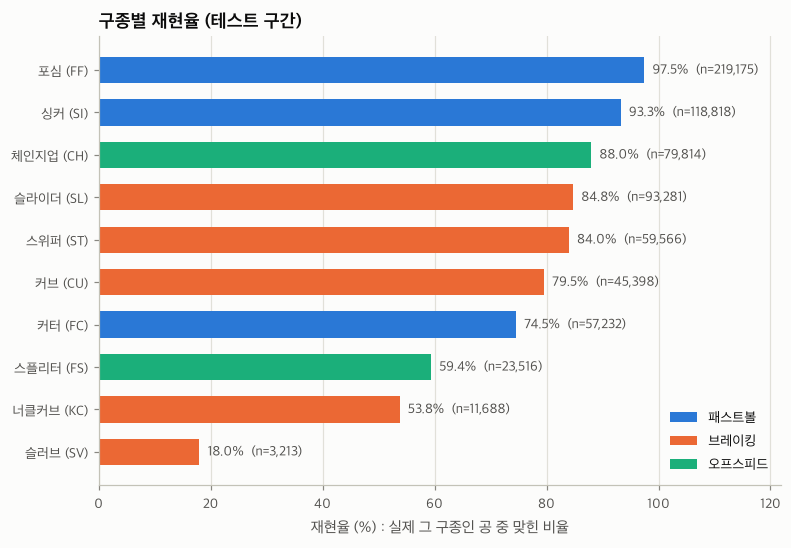

In [68]:
per_class = E.per_class_table(y_te, pred, LABELS)
display(per_class.round(3))

order = per_class.sort_values("recall", ascending=False).index
fig, ax = plt.subplots(figsize=(8, 0.4 * len(order) + 1.3))
plotting.hbar(ax, [plotting.pitch_label(c) for c in order], per_class.loc[order, "recall"] * 100,
              colors=[plotting.GROUP_COLORS[cfg.PITCH_GROUPS[c]] for c in order], fmt="{:.1f}%",
              annotations=[f"(n={int(n):,})" for n in per_class.loc[order, "support"]], xmax_pad=1.25)
ax.set_xlabel("재현율 (%) : 실제 그 구종인 공 중 맞힌 비율")
ax.set_title("구종별 재현율 (테스트 구간)")
plotting.group_legend(ax, ["fastball", "breaking", "offspeed"], loc="lower right")
plotting.save(fig, "04_recall_by_class")
plt.show()

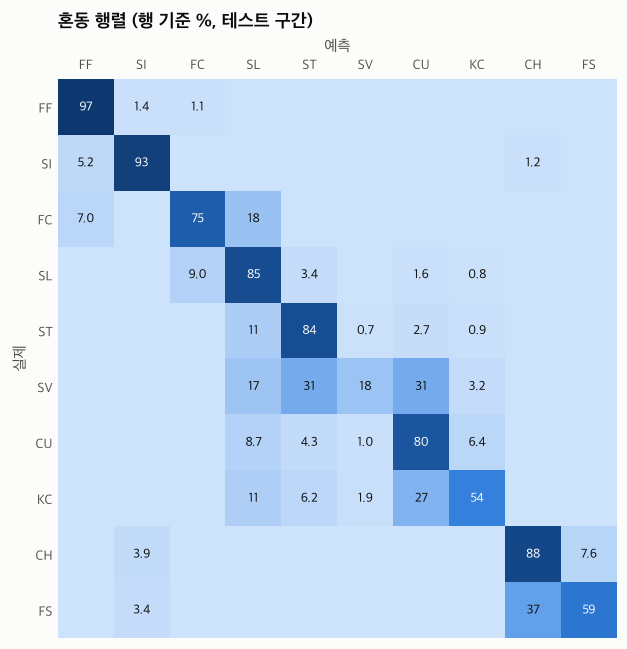

In [69]:
cm = E.confusion_frame(y_te, pred, LABELS)
fig, ax = plt.subplots(figsize=(7.4, 6.6))
plotting.confusion_heatmap(ax, cm)
ax.set_title("혼동 행렬 (행 기준 %, 테스트 구간)", pad=34)
plotting.save(fig, "04_confusion_matrix")
plt.show()

### 헷갈리는 구종 쌍

In [70]:
top = E.top_confusions(y_te, pred, LABELS, k=12)
display(top.style.format({"건수": "{:,}", "실제 클래스 대비 비율": "{:.1%}", "전체 오류 대비 비율": "{:.1%}"}))

wrong = np.asarray(y_te) != pred
same_group = E.to_pitch_group(y_te) == E.to_pitch_group(pred)
print(f"전체 오류 {int(wrong.sum()):,}건 중 같은 상위 그룹 안에서의 혼동: {int((wrong & same_group).sum()):,}건 ({(wrong & same_group).sum() / wrong.sum() * 100:.1f}%)")

FAMILIES = {"패스트볼 계열 (FF/SI/FC)": ["FF", "SI", "FC"], "브레이킹 계열 (SL/ST/SV/CU/KC)": ["SL", "ST", "SV", "CU", "KC"], "오프스피드 계열 (CH/FS)": ["CH", "FS"]}
for title, members in FAMILIES.items():
    members = [m for m in members if m in LABELS]
    print(f"\n{title}: 행=실제, 열=예측, 값=실제 클래스 대비 비율")
    display(cm.loc[members, members].style.format("{:.1%}"))

,실제,예측,건수,실제 클래스 대비 비율,전체 오류 대비 비율
0,FC,SL,"10,338",18.1%,11.7%
1,FS,CH,"8,600",36.6%,9.7%
2,SL,FC,"8,355",9.0%,9.5%
3,ST,SL,"6,784",11.4%,7.7%
4,SI,FF,"6,229",5.2%,7.0%
5,CH,FS,"6,105",7.6%,6.9%
6,FC,FF,"3,989",7.0%,4.5%
7,CU,SL,"3,970",8.7%,4.5%
8,SL,ST,"3,160",3.4%,3.6%
9,CH,SI,"3,151",3.9%,3.6%


전체 오류 88,369건 중 같은 상위 그룹 안에서의 혼동: 62,669건 (70.9%)

패스트볼 계열 (FF/SI/FC): 행=실제, 열=예측, 값=실제 클래스 대비 비율


예측,FF,SI,FC
실제,,,
FF,97.5%,1.4%,1.1%
SI,5.2%,93.3%,0.1%
FC,7.0%,0.2%,74.5%



브레이킹 계열 (SL/ST/SV/CU/KC): 행=실제, 열=예측, 값=실제 클래스 대비 비율


예측,SL,ST,SV,CU,KC
실제,,,,,
SL,84.8%,3.4%,0.1%,1.6%,0.8%
ST,11.4%,84.0%,0.7%,2.7%,0.9%
SV,17.2%,30.8%,18.0%,30.8%,3.2%
CU,8.7%,4.3%,1.0%,79.5%,6.4%
KC,11.3%,6.2%,1.9%,26.8%,53.8%



오프스피드 계열 (CH/FS): 행=실제, 열=예측, 값=실제 클래스 대비 비율


예측,CH,FS
실제,,
CH,88.0%,7.6%
FS,36.6%,59.4%


## 5. 상위 그룹으로 합친 결과

세부 구종 10개 대신 패스트볼/브레이킹/오프스피드 3개 그룹으로 보면 얼마나 쉬워지는지 비교한다.

- **10종 예측을 그룹으로 환산**: 위 최종 모델의 예측과 정답을 둘 다 그룹으로 바꿔 채점
- **3그룹 직접 학습**: 처음부터 그룹을 정답으로 학습

In [71]:
y_te_group, pred_group = E.to_pitch_group(y_te), E.to_pitch_group(pred)
group_data = dataclasses.replace(data, y=pd.Series(E.to_pitch_group(data.y), index=data.y.index))
group_model = models.make_pipeline("hgb", group_data, **best_params).fit(group_data.X[train], group_data.y[train])
pred_group_direct = group_model.predict(X_te)

group_table = pd.DataFrame(
    {
        "10종 분류": final_metrics,
        "10종 예측을 3그룹으로 환산": E.multiclass_metrics(y_te_group, pred_group),
        "3그룹 직접 학습": E.multiclass_metrics(y_te_group, pred_group_direct),
    }
).T
display(group_table)
GROUPS = ["fastball", "breaking", "offspeed"]
E.confusion_frame(y_te_group, pred_group, GROUPS).rename(index=cfg.PITCH_GROUP_LABELS, columns=cfg.PITCH_GROUP_LABELS).style.format("{:.1%}")

,accuracy,macro_f1
10종 분류,0.876,0.746
10종 예측을 3그룹으로 환산,0.964,0.963
3그룹 직접 학습,0.964,0.964


예측,패스트볼,브레이킹,오프스피드
실제,,,
패스트볼,96.9%,2.6%,0.5%
브레이킹,4.1%,95.8%,0.1%
오프스피드,4.1%,0.2%,95.7%


## 6. 투수 ID 사용 여부와 처음 보는 투수

네 가지 입력 구성을 두 가지 분할로 비교한다.

| 입력 구성 | 내용 |
|---|---|
| 물리량 | 현재 투구의 물리량만 |
| 물리량 + 투수 상대값 | 그 투수의 이전 투구 평균·최고 구속 대비 차이를 추가 (라벨 없이 계산) |
| 물리량 + 투수 ID | 투수 ID를 타깃 인코딩해 추가 (학습 구간에서 본 그 투수의 구종 분포) |
| 물리량 + 투수 상대값 + 투수 ID | 둘 다 |

- **시간 분할**: 과거로 학습해 최근 기간을 예측. 테스트의 투수 대부분은 학습에서 본 투수다.
- **투수 단위 GroupKFold**: 검증 폴드의 투수는 학습에 한 명도 없다. 학습 구간 안에서만 수행한다.

참고: 투수 상대값 묶음의 `p_n_prior`(이전 투구 수)는 `config.PRIOR_COUNT_CAPS`의 상한에서 포화시킨 값이다. 상한 없이 누적 횟수를 그대로 쓰면 테스트 구간의 값이 학습 구간의 범위를 벗어나, 파일럿에서 이 구성의 시간 분할 정확도가 물리량만 쓸 때보다 크게 떨어졌다.

In [72]:
VARIANTS = [
    ("물리량", "physics", False),
    ("물리량 + 투수 상대값", "physics+relative", False),
    ("물리량 + 투수 ID", "physics", True),
    ("물리량 + 투수 상대값 + 투수 ID", "physics+relative", True),
]
group_cv_rows = E.limit_train(train, cfg.GROUP_CV_MAX_ROWS)
seen = data.meta.loc[test, "pitcher"].isin(set(data.meta.loc[compare_train, "pitcher"])).to_numpy()
variant_rows = []
for label, feature_set, with_id in VARIANTS:
    d = datasets.pitch_type_data(df, feature_set, with_pitcher_id=with_id)
    # (a) 시간 분할
    pipe = models.make_pipeline("hgb", d, **best_params).fit(d.X[compare_train], d.y[compare_train])
    p = pipe.predict(d.X[test])
    y_true = d.y[test].to_numpy()
    row = {"입력 구성": label, "입력 수": d.X.shape[1],
           "시간 분할 accuracy": (p == y_true).mean(), "시간 분할 macro_f1": E.multiclass_metrics(y_true, p)["macro_f1"],
           "└ 학습에서 본 투수 accuracy": (p[seen] == y_true[seen]).mean(),
           "└ 처음 보는 투수 accuracy": (p[~seen] == y_true[~seen]).mean() if (~seen).any() else np.nan}
    # (b) 투수 단위 GroupKFold (학습 구간 안에서)
    Xg, yg, gg = d.X[group_cv_rows].reset_index(drop=True), d.y[group_cv_rows].reset_index(drop=True), d.meta.loc[group_cv_rows, "pitcher"].to_numpy()
    fold_scores = []
    for tr_idx, va_idx in splits.pitcher_group_kfold().split(Xg, yg, groups=gg):
        fold_pipe = models.make_pipeline("hgb", d, **best_params).fit(Xg.iloc[tr_idx], yg.iloc[tr_idx])
        fold_scores.append(E.multiclass_metrics(yg.iloc[va_idx], fold_pipe.predict(Xg.iloc[va_idx])))
    fold_scores = pd.DataFrame(fold_scores)
    row.update({"GroupKFold accuracy": fold_scores["accuracy"].mean(), "GroupKFold accuracy 표준편차": fold_scores["accuracy"].std(),
                "GroupKFold macro_f1": fold_scores["macro_f1"].mean(), "GroupKFold macro_f1 표준편차": fold_scores["macro_f1"].std()})
    variant_rows.append(row)
variant_table = pd.DataFrame(variant_rows).set_index("입력 구성")
print(f"시간 분할: 학습 {int(compare_train.sum()):,}행 / 테스트 {int(test.sum()):,}행 (그중 처음 보는 투수의 공 {int((~seen).sum()):,}행)")
print(f"GroupKFold: 학습 구간에서 {int(group_cv_rows.sum()):,}행, {cfg.N_GROUP_SPLITS}개 폴드")
variant_table

시간 분할: 학습 500,000행 / 테스트 711,701행 (그중 처음 보는 투수의 공 68,004행)
GroupKFold: 학습 구간에서 300,000행, 5개 폴드


,입력 수,시간 분할 accuracy,시간 분할 macro_f1,└ 학습에서 본 투수 accuracy,└ 처음 보는 투수 accuracy,GroupKFold accuracy,GroupKFold accuracy 표준편차,GroupKFold macro_f1,GroupKFold macro_f1 표준편차
입력 구성,,,,,,,,,
물리량,18,0.874,0.743,0.876,0.857,0.818,0.011,0.627,0.009
물리량 + 투수 상대값,24,0.894,0.776,0.895,0.878,0.840,0.014,0.648,0.013
물리량 + 투수 ID,19,0.908,0.857,0.920,0.798,0.798,0.013,0.614,0.018
물리량 + 투수 상대값 + 투수 ID,25,0.913,0.860,0.923,0.816,0.781,0.088,0.598,0.078


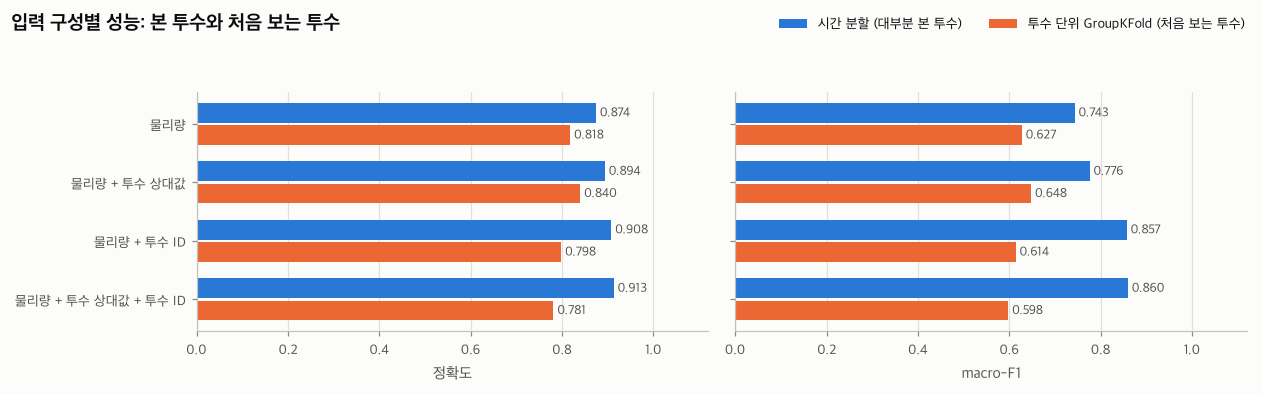

In [73]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6), sharey=True)
labels = list(variant_table.index)
ypos = np.arange(len(labels))[::-1]
for ax, metric, title in zip(axes, ["accuracy", "macro_f1"], ["정확도", "macro-F1"]):
    a, b = variant_table[f"시간 분할 {metric}"], variant_table[f"GroupKFold {metric}"]
    ax.barh(ypos + 0.19, a, height=0.34, color=plotting.BLUE, label="시간 분할 (대부분 본 투수)")
    ax.barh(ypos - 0.19, b, height=0.34, color=plotting.ORANGE, label="투수 단위 GroupKFold (처음 보는 투수)")
    for y0, va_, vb_ in zip(ypos, a, b):
        ax.text(va_ + 0.008, y0 + 0.19, f"{va_:.3f}", va="center", fontsize=8.5, color=plotting.INK_2)
        ax.text(vb_ + 0.008, y0 - 0.19, f"{vb_:.3f}", va="center", fontsize=8.5, color=plotting.INK_2)
    ax.set_yticks(ypos, labels)
    ax.set_xlim(0, 1.12)
    ax.set_xlabel(title)
    ax.grid(axis="y", visible=False)
fig.suptitle("입력 구성별 성능: 본 투수와 처음 보는 투수", x=0.01, ha="left", fontsize=13, fontweight="bold")
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper right", bbox_to_anchor=(0.995, 1.0), ncols=2)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plotting.save(fig, "04_pitcher_id_comparison")
plt.show()

## 7. 해석

### 7-1. Permutation importance

테스트 구간 표본에서 피처 하나를 무작위로 섞었을 때 정확도가 얼마나 떨어지는지 본다. 서로 상관이 높은 피처(예: `pfx_x_arm`과 `ax_arm`)는 하나를 섞어도 다른 쪽이 정보를 대신 주므로 각각의 값이 낮게 나온다는 점에 주의한다.

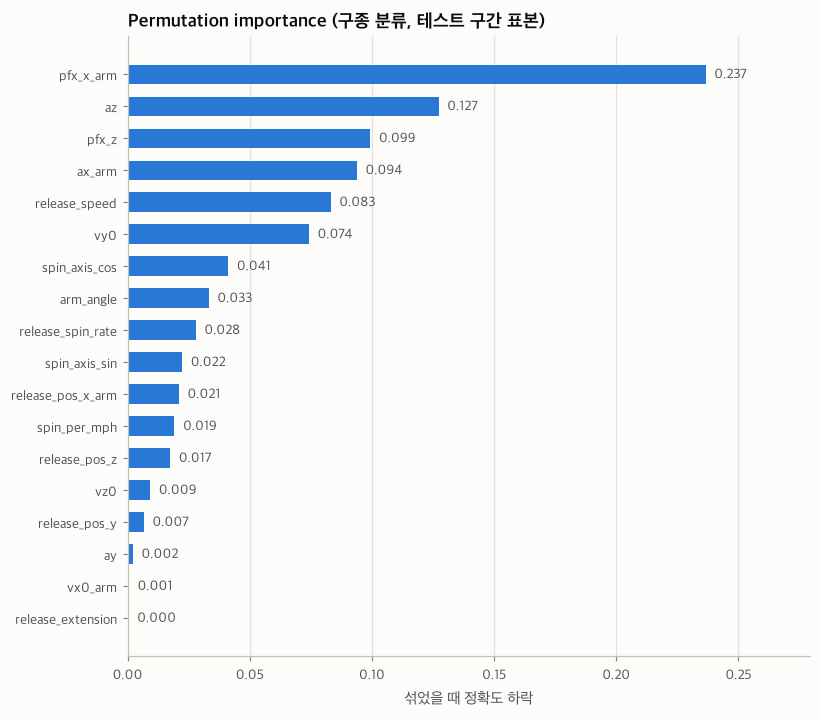

,importance,std
pfx_x_arm,0.237,0.001
az,0.127,0.002
pfx_z,0.099,0.001
ax_arm,0.094,0.001
release_speed,0.083,0.001
vy0,0.074,0.001
spin_axis_cos,0.041,0.001
arm_angle,0.033,0.001
release_spin_rate,0.028,0.000
spin_axis_sin,0.022,0.001


In [74]:
perm = interpret.permutation_table(final, X_te.reset_index(drop=True), y_te.reset_index(drop=True), scoring="accuracy")
fig, ax = plt.subplots(figsize=(8, 0.34 * len(perm) + 1.2))
plotting.hbar(ax, perm.index, perm["importance"], fmt="{:.3f}")
ax.set_xlabel("섞었을 때 정확도 하락")
ax.set_title("Permutation importance (구종 분류, 테스트 구간 표본)")
plotting.save(fig, "04_permutation_importance")
plt.show()
perm.round(4)

### 7-2. 투수별 정확도

평균 정확도가 높아도 특정 투수에게서는 크게 틀릴 수 있다. 테스트 구간에서 공을 충분히 던진 투수만 본다.

테스트 구간에서 100구 이상 던진 투수 720명 | 정확도 중앙값 0.894 | 90% 미만 380명 | 70% 미만 52명


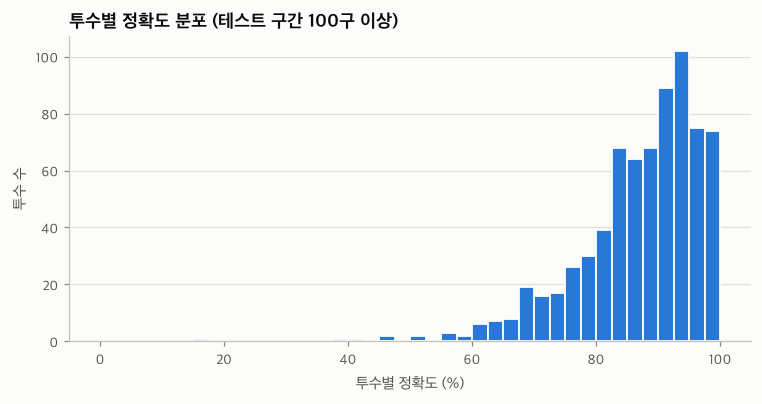

,투구수,정확도,구종수,주요_혼동
player_name,,,,
"Dodd, Dylan",779,0.167,4,"SI→FF 466, FC→SL 159, FC→CH 13"
"Abner, Philip",313,0.377,5,"FF→FC 133, SL→ST 43, CU→SL 9"
"Sandlin, Nick",157,0.408,4,"SL→ST 68, FS→CH 22, SI→FF 2"
"Orze, Eric",677,0.452,4,"FS→CH 294, SL→FC 39, CU→ST 37"
"McCambley, Zach",238,0.471,4,"FC→SL 103, FF→FC 19, ST→SL 2"
"Waldichuk, Ken",149,0.510,5,"CU→ST 44, ST→SL 12, CU→SV 8"
"Johnson, Pierce",840,0.521,3,"CU→SL 372, CU→ST 18, CU→KC 8"
"Hughes, Gabriel",1142,0.556,6,"FF→FC 368, CH→FS 60, ST→SL 30"


In [75]:
MIN_PITCHES = 100
result = data.meta[test].assign(pred=pred, correct=(pred == y_te.to_numpy()))
by_pitcher = result.groupby(["pitcher", "player_name"]).agg(투구수=("correct", "size"), 정확도=("correct", "mean"), 구종수=("pitch_type", "nunique")).reset_index()
by_pitcher = by_pitcher[by_pitcher["투구수"] >= MIN_PITCHES]
print(f"테스트 구간에서 {MIN_PITCHES}구 이상 던진 투수 {len(by_pitcher)}명 | 정확도 중앙값 {by_pitcher['정확도'].median():.3f} | 90% 미만 {int((by_pitcher['정확도'] < 0.9).sum())}명 | 70% 미만 {int((by_pitcher['정확도'] < 0.7).sum())}명")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(by_pitcher["정확도"] * 100, bins=np.arange(0, 100.1, 2.5), color=plotting.BLUE, edgecolor=plotting.SURFACE, linewidth=1.2)
ax.set_xlabel("투수별 정확도 (%)")
ax.set_ylabel("투수 수")
ax.grid(axis="x", visible=False)
ax.set_title(f"투수별 정확도 분포 (테스트 구간 {MIN_PITCHES}구 이상)")
plotting.save(fig, "04_accuracy_by_pitcher")
plt.show()

worst = by_pitcher.nsmallest(8, "정확도")
def main_confusions(pid):
    sub = result[(result["pitcher"] == pid) & ~result["correct"]]
    pairs = (sub["pitch_type"] + "→" + sub["pred"]).value_counts().head(3)
    return ", ".join(f"{k} {v}" for k, v in pairs.items())
worst = worst.assign(주요_혼동=[main_confusions(p) for p in worst["pitcher"]])
worst.drop(columns="pitcher").set_index("player_name").round(3)

## 8. 결과 저장

In [76]:
out = {
    "mode": cfg.mode_name(),
    "train_rows": int(train.sum()), "test_rows": int(test.sum()),
    "train_dates": [str(dates[train].min().date()), str(dates[train].max().date())],
    "test_dates": [str(dates[test].min().date()), str(dates[test].max().date())],
    "n_features": len(data.numeric), "classes": LABELS,
    "best_params": best_params,
    "model_comparison": summary_table.reset_index(names="model").to_dict(orient="records"),
    "per_class": per_class.reset_index(names="pitch_type").to_dict(orient="records"),
    "top_confusions": top.to_dict(orient="records"),
    "same_group_error_share": float((wrong & same_group).sum() / wrong.sum()),
    "group_level": group_table.reset_index(names="setting").to_dict(orient="records"),
    "pitcher_id_comparison": variant_table.reset_index().to_dict(orient="records"),
    "permutation_importance": perm["importance"].round(5).to_dict(),
}
path = cfg.metrics_path("04_pitch_type")
path.parent.mkdir(parents=True, exist_ok=True)
path.write_text(json.dumps(out, indent=1, ensure_ascii=False, default=float), encoding="utf-8")
print("저장:", path.relative_to(ROOT))

저장: reports/metrics/full/04_pitch_type.json


# 5부. 헛스윙(Whiff) 확률 예측 (원래 `05_whiff_model.ipynb`)

**목표**: 타자가 스윙한 투구에서 헛스윙이 될 확률 P(whiff | swing)을 예측한다.

**핵심 질문**: 모델이 "구종별 평균 헛스윙률", "구종 x 존 위치별 평균 헛스윙률"이라는 단순한 기준보다 얼마나 나은가?

**순서**
0. 누수 점검
1. 데이터와 시간 기준 분할
2. 그룹 평균 베이스라인
3. 모델 비교 (로지스틱 회귀, 랜덤 포레스트, HGB)
4. 시계열 교차검증으로 HGB 튜닝, 최종 평가
5. 입력 묶음별 기여
6. 캘리브레이션
7. 헛스윙 정의(foul_tip 포함 여부) 비교
8. 전체 투구 기준 P(whiff)
9. 해석: 중요도, partial dependence, 위치별 예측, 투수 사례

모든 수치는 **테스트 구간** 기준이고, 튜닝과 보정 여부 판단은 학습 구간 안에서만 한다.

In [77]:
%reset -f
# 앞 부의 변수를 모두 비운다 (원래는 노트북마다 새 커널이었다). src 모듈은 그대로 남는다.
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as cfg, plotting
ROOT = cfg.ROOT
import time

from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

from src import datasets, evaluate as E, features as F, interpret, labels, leakage, models, preprocess, splits, tuning
plotting.set_style()
pd.set_option("display.max_columns", 60, "display.width", 220, "display.float_format", "{:,.3f}".format)
print("모드:", cfg.mode_name())

모드: full


## 0. 누수 점검

In [78]:
df = datasets.load_features()
audit = leakage.assert_audit_passes(df)
print(f"누수 점검 {len(audit)}개 모두 통과")
audit[audit["점검"].str.startswith(("헛스윙", "시간 분할", "시계열"))]

누수 점검 27개 모두 통과


,점검,통과,내용
5,헛스윙 입력에 결과 컬럼이 없다 [pitch],True,입력 19개
6,헛스윙 입력에 결과 컬럼이 없다 [pitch+location],True,입력 28개
7,헛스윙 입력에 결과 컬럼이 없다 [pitch+location+context],True,입력 44개
8,헛스윙 입력에 결과 컬럼이 없다 [+sequence],True,입력 54개
9,헛스윙 입력에 결과 컬럼이 없다 [full],True,입력 75개
13,헛스윙: description을 넣으면 거부된다,True,
14,헛스윙: events을 넣으면 거부된다,True,
15,헛스윙: type을 넣으면 거부된다,True,
16,헛스윙: bb_type을 넣으면 거부된다,True,
17,헛스윙: launch_speed을 넣으면 거부된다,True,


## 1. 데이터와 분할

스윙한 투구만 쓴다. 정답은 `is_whiff`다.

In [79]:
data = datasets.whiff_data(df, "full", population="swing")
train, test = splits.time_split(data.meta)
dates = data.meta["game_date"]
X_te, y_te, meta_tr, meta_te = data.X[test], data.y[test], data.meta[train], data.meta[test]

print(data.description)
print(f"입력 {data.X.shape[1]}개 (수치 {len(data.numeric)}, 범주 {len(data.categorical)})")
print(f"학습 : {int(train.sum()):,}스윙 | {dates[train].min().date()} ~ {dates[train].max().date()} | 헛스윙률 {data.y[train].mean():.4f}")
print(f"테스트: {int(test.sum()):,}스윙 | {dates[test].min().date()} ~ {dates[test].max().date()} | 헛스윙률 {y_te.mean():.4f}")

헛스윙 예측 | 대상=swing | 입력 묶음=full | 구종 코드=사용
입력 75개 (수치 74, 범주 1)
학습 : 1,020,491스윙 | 2023-03-30 ~ 2025-09-28 | 헛스윙률 0.2541
테스트: 340,572스윙 | 2026-03-25 ~ 2026-09-27 | 헛스윙률 0.2499


## 2. 그룹 평균 베이스라인

학습 구간에서 그룹별 헛스윙률을 구해 그대로 예측값으로 쓴다. 모델 없이도 낼 수 있는 예측이다.

- **전체 평균**: 모든 스윙에 같은 확률
- **구종별 평균**: 구종마다 하나의 확률
- **구종 x 존 평균**: 구종과 Statcast 존(1~9는 존 안, 11~14는 존 밖) 조합마다 하나의 확률

표본이 적은 칸은 상위 평균 쪽으로 당긴다(`config.BASELINE_SHRINKAGE`).

In [80]:
baselines = {
    "전체 평균": E.GroupMeanBaseline([]),
    "구종별 평균": E.GroupMeanBaseline(["pitch_type"]),
    "구종 x 존 평균": E.GroupMeanBaseline(["pitch_type", "zone"]),
}
preds = {name: b.fit(meta_tr, data.y[train]).predict_proba(meta_te) for name, b in baselines.items()}
REFERENCE = "구종 x 존 평균"   # 가장 강한 베이스라인을 비교 기준으로 삼는다
E.binary_metrics_table(y_te, preds)

,base_rate,roc_auc,pr_auc,log_loss,brier,mean_pred
전체 평균,0.250,0.500,0.250,0.562,0.187,0.254
구종별 평균,0.250,0.602,0.306,0.549,0.183,0.252
구종 x 존 평균,0.250,0.721,0.460,0.502,0.164,0.262


## 3. 모델 비교

같은 학습 행(`config.COMPARE_MAX_TRAIN_ROWS` 이하)으로 세 모델을 학습한다. HGB는 기본 설정이다.

In [81]:
compare_train = E.limit_train(train, cfg.COMPARE_MAX_TRAIN_ROWS)
n_compare = int(compare_train.sum())
fit_seconds = {}
for name, pipe in [
    ("로지스틱 회귀", models.make_pipeline("logreg", data)),
    ("랜덤 포레스트", models.make_pipeline("rf", data, max_samples=models.rf_max_samples(n_compare))),
    ("HGB (기본 설정)", models.make_pipeline("hgb", data)),
]:
    start = time.time()
    pipe.fit(data.X[compare_train], data.y[compare_train])
    preds[name] = pipe.predict_proba(X_te)[:, 1]
    fit_seconds[name] = round(time.time() - start, 1)
print(f"학습 행 {n_compare:,} | 학습+예측 시간(초): {fit_seconds}")
E.binary_metrics_table(y_te, preds, reference=REFERENCE)

학습 행 500,000 | 학습+예측 시간(초): {'로지스틱 회귀': 6.8, '랜덤 포레스트': 21.7, 'HGB (기본 설정)': 12.8}


,base_rate,roc_auc,pr_auc,log_loss,brier,mean_pred,log_loss_개선(%) vs 구종 x 존 평균,brier_skill vs 구종 x 존 평균,roc_auc_차이 vs 구종 x 존 평균
전체 평균,0.250,0.500,0.250,0.562,0.187,0.254,-12.084,-0.144,-0.221
구종별 평균,0.250,0.602,0.306,0.549,0.183,0.252,-9.374,-0.115,-0.119
구종 x 존 평균,0.250,0.721,0.460,0.502,0.164,0.262,0.000,0.000,0.000
로지스틱 회귀,0.250,0.755,0.578,0.474,0.152,0.287,5.556,0.070,0.034
랜덤 포레스트,0.250,0.779,0.602,0.455,0.146,0.261,9.229,0.112,0.058
HGB (기본 설정),0.250,0.790,0.618,0.446,0.142,0.258,11.068,0.131,0.069


## 4. HGB 튜닝과 최종 평가

### 4-1. 시계열 교차검증

튜닝에 쓴 행: 300,000 | 후보 6개 x 폴드 4개 | 194초
선택된 설정: {'learning_rate': 0.05, 'max_leaf_nodes': 31, 'max_iter': 500}


,learning_rate,max_leaf_nodes,max_iter,log_loss,roc_auc,log_loss_std
0,0.050,31,500,0.455,0.779,0.005
1,0.050,31,400,0.455,0.779,0.005
2,0.050,31,300,0.455,0.779,0.004
3,0.050,63,300,0.455,0.779,0.005
4,0.050,63,200,0.455,0.779,0.005
5,0.050,63,400,0.456,0.778,0.006
6,0.050,15,500,0.456,0.778,0.004
7,0.100,15,500,0.456,0.778,0.005


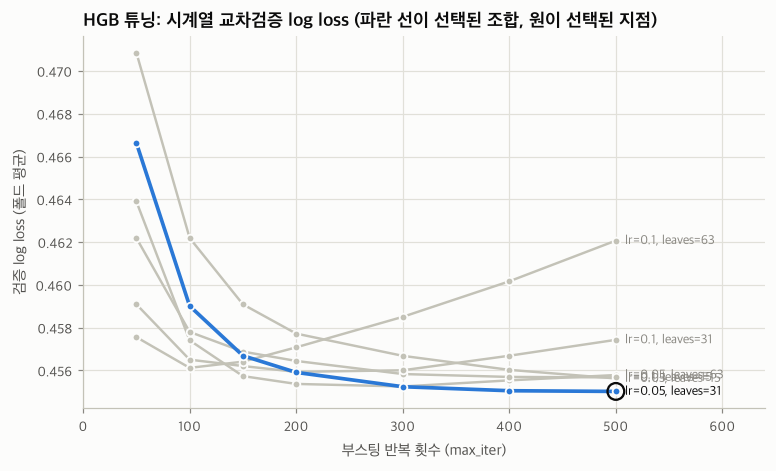

In [82]:
start = time.time()
tune_summary, best_params = tuning.tune_hgb(data, train)
print(f"튜닝에 쓴 행: {tune_summary.attrs['rows_used']:,} | 후보 {len(cfg.HGB_GRID)}개 x 폴드 {cfg.N_TIME_SPLITS}개 | {time.time() - start:.0f}초")
print("선택된 설정:", best_params)
display(tune_summary.head(8))

fig, ax = plt.subplots(figsize=(8, 4.4))
plotting.tuning_curve(ax, tune_summary, best_params)
ax.set_title("HGB 튜닝: 시계열 교차검증 log loss (파란 선이 선택된 조합, 원이 선택된 지점)")
plotting.save(fig, "05_tuning_curve")
plt.show()

### 4-2. 최종 모델: 베이스라인 대비 얼마나 나은가

선택된 설정으로 학습 구간 전체를 써서 학습한다.

In [83]:
FINAL = "HGB (튜닝, 학습 전체)"
start = time.time()
final = models.make_pipeline("hgb", data, **best_params).fit(data.X[train], data.y[train])
preds[FINAL] = final.predict_proba(X_te)[:, 1]
print(f"학습 {int(train.sum()):,}행, {time.time() - start:.0f}초")
metrics_table = E.binary_metrics_table(y_te, preds, reference=REFERENCE)
metrics_table

학습 1,020,491행, 45초


,base_rate,roc_auc,pr_auc,log_loss,brier,mean_pred,log_loss_개선(%) vs 구종 x 존 평균,brier_skill vs 구종 x 존 평균,roc_auc_차이 vs 구종 x 존 평균
전체 평균,0.250,0.500,0.250,0.562,0.187,0.254,-12.084,-0.144,-0.221
구종별 평균,0.250,0.602,0.306,0.549,0.183,0.252,-9.374,-0.115,-0.119
구종 x 존 평균,0.250,0.721,0.460,0.502,0.164,0.262,0.000,0.000,0.000
로지스틱 회귀,0.250,0.755,0.578,0.474,0.152,0.287,5.556,0.070,0.034
랜덤 포레스트,0.250,0.779,0.602,0.455,0.146,0.261,9.229,0.112,0.058
HGB (기본 설정),0.250,0.790,0.618,0.446,0.142,0.258,11.068,0.131,0.069
"HGB (튜닝, 학습 전체)",0.250,0.792,0.620,0.445,0.142,0.258,11.377,0.134,0.071


In [84]:
# 최종 모델과 가장 강한 베이스라인의 차이가 우연인지: 경기 단위 부트스트랩 95% 신뢰구간
boot = E.cluster_bootstrap_diff(y_te, preds[FINAL], preds[REFERENCE], meta_te["game_pk"])
print(f"'{FINAL}' - '{REFERENCE}' (경기 {meta_te['game_pk'].nunique()}개를 {cfg.N_BOOTSTRAP}번 다시 뽑음)")
boot

'HGB (튜닝, 학습 전체)' - '구종 x 존 평균' (경기 2429개를 200번 다시 뽑음)


,차이 (모델 - 기준),95% 하한,95% 상한
log_loss,-0.057,-0.058,-0.056
brier,-0.022,-0.022,-0.022
roc_auc,0.071,0.069,0.072


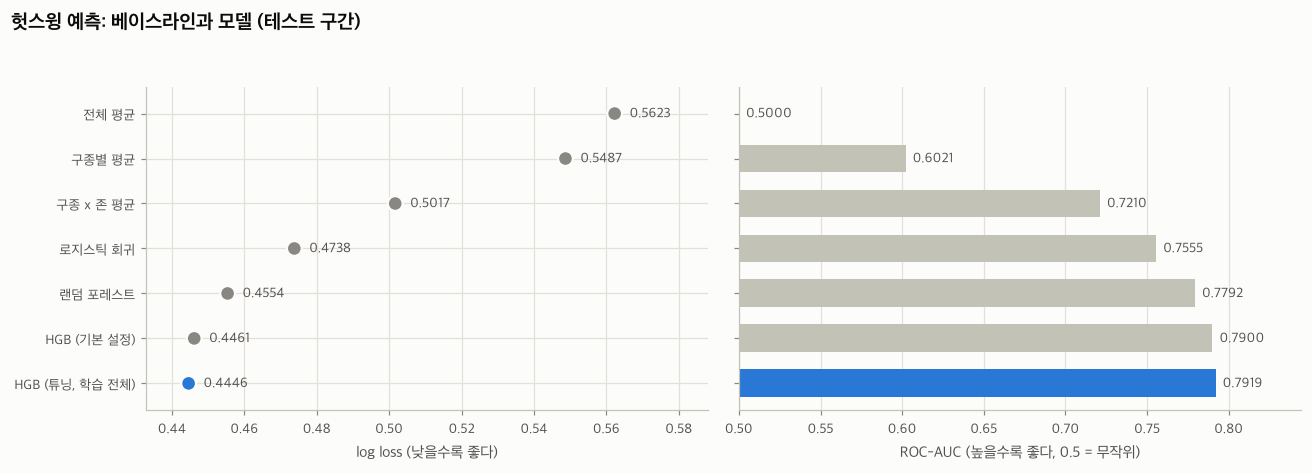

In [85]:
order = list(metrics_table.index)
colors = [plotting.BLUE if name == FINAL else plotting.AXIS for name in order]
fig, axes = plt.subplots(1, 2, figsize=(12, 0.42 * len(order) + 1.4), sharey=True)
plotting.dots(axes[0], order, metrics_table["log_loss"], colors=[plotting.BLUE if name == FINAL else plotting.MUTED for name in order], fmt="{:.4f}")
axes[0].set_xlabel("log loss (낮을수록 좋다)")
plotting.hbar(axes[1], order, metrics_table["roc_auc"], colors=colors, fmt="{:.4f}", base=0.5)
axes[1].set_xlabel("ROC-AUC (높을수록 좋다, 0.5 = 무작위)")
fig.suptitle("헛스윙 예측: 베이스라인과 모델 (테스트 구간)", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94))
plotting.save(fig, "05_model_vs_baseline")
plt.show()

## 5. 입력 묶음별 기여

입력을 단계적으로 늘려 가며 같은 설정의 HGB를 학습한다. 어떤 정보가 성능을 끌어올리는지 보기 위한 것이다.

학습 행 500,000 (비교용 표본), 테스트 340,572행


,입력 수,roc_auc,pr_auc,log_loss,brier,mean_pred,roc_auc 증가분,log_loss 감소분
pitch,19.000,0.744,0.553,0.480,0.155,0.251,NaN,NaN
pitch+location,28.000,0.765,0.576,0.466,0.150,0.253,0.021,0.014
pitch+location+context,44.000,0.776,0.598,0.457,0.146,0.254,0.011,0.010
+sequence,54.000,0.778,0.600,0.456,0.146,0.253,0.001,0.001
full,75.000,0.790,0.618,0.446,0.142,0.258,0.013,0.010


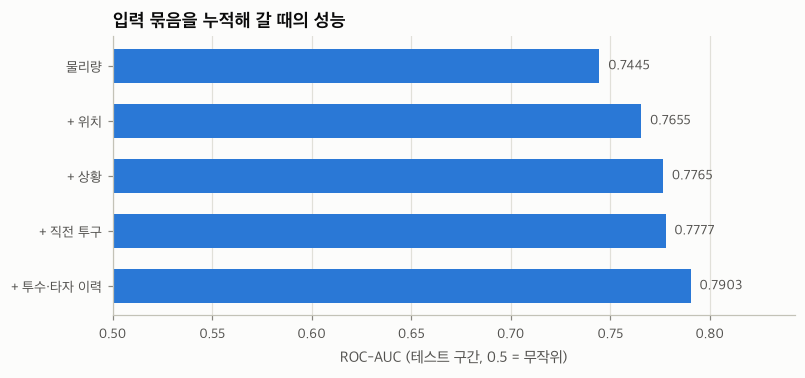

In [86]:
ablation_rows = {}
for name in datasets.WHIFF_FEATURE_SETS:
    d = datasets.whiff_data(df, name, population="swing")
    pipe = models.make_pipeline("hgb", d, **best_params).fit(d.X[compare_train], d.y[compare_train])
    ablation_rows[name] = {"입력 수": d.X.shape[1], **E.binary_metrics(y_te, pipe.predict_proba(d.X[test])[:, 1])}
ablation = pd.DataFrame(ablation_rows).T
ablation["roc_auc 증가분"] = ablation["roc_auc"].diff()
ablation["log_loss 감소분"] = -ablation["log_loss"].diff()
print(f"학습 행 {n_compare:,} (비교용 표본), 테스트 {int(test.sum()):,}행")
display(ablation)

SET_LABELS = {"pitch": "물리량", "pitch+location": "+ 위치", "pitch+location+context": "+ 상황", "+sequence": "+ 직전 투구", "full": "+ 투수·타자 이력"}
fig, ax = plt.subplots(figsize=(8, 3.3))
plotting.hbar(ax, [SET_LABELS[n] for n in ablation.index], ablation["roc_auc"], fmt="{:.4f}", base=0.5)
ax.set_xlabel("ROC-AUC (테스트 구간, 0.5 = 무작위)")
ax.set_title("입력 묶음을 누적해 갈 때의 성능")
plotting.save(fig, "05_feature_set_ablation")
plt.show()

## 6. 캘리브레이션

예측 확률이 실제 비율과 맞는지 본다. 예를 들어 30%라고 예측한 스윙들 중 실제로 약 30%가 헛스윙이어야 한다.

보정(isotonic)이 필요한지는 **학습 구간 안에서** 판단한다. 학습 구간의 앞 80%(날짜 기준)로 모델을 학습하고 뒤 20%에서 ECE를 잰다. 이 값이 `config.CALIBRATION_ECE_THRESHOLD` 이상이면 보정을 적용한다. 테스트 구간 결과는 참고로 함께 보인다.

In [87]:
train_dates = np.sort(dates[train].unique())
cal_start = train_dates[int(len(train_dates) * (1 - cfg.CALIBRATION_HOLDOUT_FRAC))]
fit_part = train & (dates < cal_start).to_numpy()
cal_part = train & (dates >= cal_start).to_numpy()

base = models.make_pipeline("hgb", data, **best_params).fit(data.X[fit_part], data.y[fit_part])
holdout_proba = base.predict_proba(data.X[cal_part])[:, 1]
holdout_ece = E.expected_calibration_error(data.y[cal_part], holdout_proba)
apply_calibration = holdout_ece >= cfg.CALIBRATION_ECE_THRESHOLD
print(f"모델 학습 {int(fit_part.sum()):,}행 (~{pd.Timestamp(cal_start).date()} 이전) / 보정용 홀드아웃 {int(cal_part.sum()):,}행")
print(f"홀드아웃 ECE(보정 전) = {holdout_ece:.4f} | 기준 {cfg.CALIBRATION_ECE_THRESHOLD} → 보정 적용: {apply_calibration}")

calibrated = CalibratedClassifierCV(FrozenEstimator(base), method="isotonic").fit(data.X[cal_part], data.y[cal_part])
cal_preds = {
    REFERENCE: preds[REFERENCE],
    FINAL: preds[FINAL],
    "HGB (앞 80% 학습, 보정 전)": base.predict_proba(X_te)[:, 1],
    "HGB (앞 80% 학습 + isotonic)": calibrated.predict_proba(X_te)[:, 1],
}
cal_table = E.binary_metrics_table(y_te, cal_preds)[["roc_auc", "log_loss", "brier", "mean_pred", "base_rate"]]
cal_table.insert(0, "ECE", [E.expected_calibration_error(y_te, p) for p in cal_preds.values()])
cal_table

모델 학습 810,501행 (~2025-06-06 이전) / 보정용 홀드아웃 209,990행
홀드아웃 ECE(보정 전) = 0.0063 | 기준 0.01 → 보정 적용: False


,ECE,roc_auc,log_loss,brier,mean_pred,base_rate
구종 x 존 평균,0.012,0.721,0.502,0.164,0.262,0.250
"HGB (튜닝, 학습 전체)",0.008,0.792,0.445,0.142,0.258,0.250
"HGB (앞 80% 학습, 보정 전)",0.008,0.791,0.445,0.142,0.258,0.250
HGB (앞 80% 학습 + isotonic),0.010,0.791,0.446,0.142,0.260,0.250


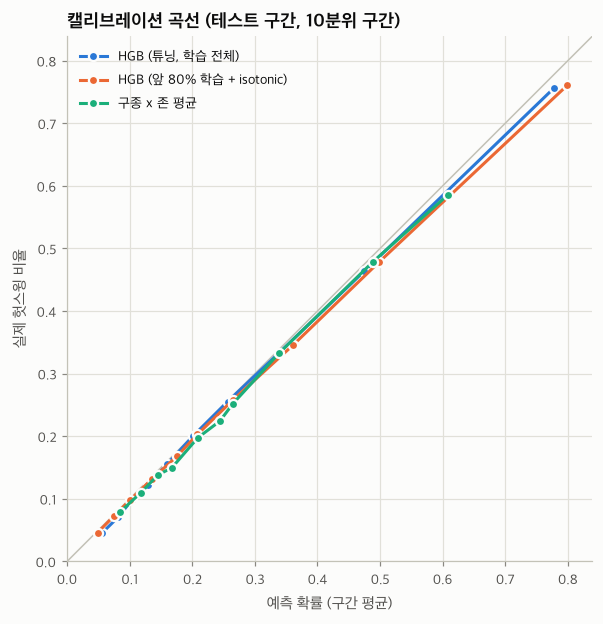

,mean_pred,observed,n,gap
0,0.055,0.045,34058,-0.010
1,0.081,0.070,34057,-0.011
2,0.104,0.098,34057,-0.005
3,0.129,0.122,34057,-0.007
4,0.160,0.156,34057,-0.004
5,0.201,0.200,34057,-0.001
6,0.257,0.255,34057,-0.001
7,0.338,0.333,34057,-0.005
8,0.475,0.464,34057,-0.011
9,0.778,0.756,34058,-0.022


In [88]:
CAL_COLORS = {FINAL: plotting.BLUE, "HGB (앞 80% 학습 + isotonic)": plotting.ORANGE, REFERENCE: plotting.AQUA}
tables = {name: E.calibration_table(y_te, cal_preds[name]) for name in CAL_COLORS}
fig, ax = plt.subplots(figsize=(6.2, 6.2))
plotting.reliability(ax, tables, CAL_COLORS)
ax.set_title("캘리브레이션 곡선 (테스트 구간, 10분위 구간)")
ax.legend(loc="upper left")
plotting.save(fig, "05_calibration")
plt.show()
tables[FINAL].round(4)

## 7. 헛스윙 정의 비교: foul_tip 포함 여부

기본 정의는 `foul_tip`을 헛스윙에 포함한다. 제외한 정의로 라벨과 이력 피처를 다시 만들어 같은 조건에서 학습·평가한다. 스윙 집합은 같으므로 학습/테스트 행은 동일하다.

In [89]:
pitches = preprocess.load_processed("pitches")
alt_df = F.build_features(labels.add_swing_whiff(pitches, include_foul_tip=False))
alt = datasets.whiff_data(alt_df, "full", population="swing")
assert (alt.meta[cfg.PITCH_KEY].to_numpy() == data.meta[cfg.PITCH_KEY].to_numpy()).all(), "두 정의의 행이 일치하지 않는다"

definition_rows = {}
for label, d in [("foul_tip 포함 (기본)", data), ("foul_tip 제외", alt)]:
    ref = E.GroupMeanBaseline(["pitch_type", "zone"]).fit(d.meta[train], d.y[train]).predict_proba(d.meta[test])
    model = models.make_pipeline("hgb", d, **best_params).fit(d.X[compare_train], d.y[compare_train])
    t = E.binary_metrics_table(d.y[test], {REFERENCE: ref, "HGB": model.predict_proba(d.X[test])[:, 1]}, reference=REFERENCE)
    definition_rows[label] = {
        "테스트 헛스윙률": d.y[test].mean(),
        "베이스라인 log_loss": t.loc[REFERENCE, "log_loss"], "HGB log_loss": t.loc["HGB", "log_loss"],
        "log_loss 개선(%)": t.loc["HGB", f"log_loss_개선(%) vs {REFERENCE}"],
        "베이스라인 roc_auc": t.loc[REFERENCE, "roc_auc"], "HGB roc_auc": t.loc["HGB", "roc_auc"],
        "HGB pr_auc": t.loc["HGB", "pr_auc"], "HGB brier": t.loc["HGB", "brier"],
    }
definition_table = pd.DataFrame(definition_rows).T
print(f"학습 행 {n_compare:,} (비교용 표본)")
definition_table

학습 행 500,000 (비교용 표본)


,테스트 헛스윙률,베이스라인 log_loss,HGB log_loss,log_loss 개선(%),베이스라인 roc_auc,HGB roc_auc,HGB pr_auc,HGB brier
foul_tip 포함 (기본),0.250,0.502,0.446,11.117,0.721,0.790,0.618,0.142
foul_tip 제외,0.228,0.473,0.417,11.732,0.733,0.801,0.613,0.131


## 8. 전체 투구 기준 P(whiff)

스윙 여부와 상관없이 모든 투구에 대해 헛스윙 확률을 예측한다. 이 경우 모델은 "타자가 스윙할지"와 "스윙하면 헛칠지"를 함께 맞혀야 한다. 스윙 조건부 문제와는 대상과 기저율이 달라 지표를 직접 비교할 수는 없다.

In [90]:
all_data = datasets.whiff_data(df, "full", population="all")
all_train, all_test = splits.time_split(all_data.meta)
all_compare = E.limit_train(all_train, cfg.COMPARE_MAX_TRAIN_ROWS)
all_preds = {
    "전체 평균": E.GroupMeanBaseline([]).fit(all_data.meta[all_train], all_data.y[all_train]).predict_proba(all_data.meta[all_test]),
    "구종별 평균": E.GroupMeanBaseline(["pitch_type"]).fit(all_data.meta[all_train], all_data.y[all_train]).predict_proba(all_data.meta[all_test]),
    REFERENCE: E.GroupMeanBaseline(["pitch_type", "zone"]).fit(all_data.meta[all_train], all_data.y[all_train]).predict_proba(all_data.meta[all_test]),
}
all_model = models.make_pipeline("hgb", all_data, **best_params).fit(all_data.X[all_compare], all_data.y[all_compare])
all_preds["HGB"] = all_model.predict_proba(all_data.X[all_test])[:, 1]
all_table = E.binary_metrics_table(all_data.y[all_test], all_preds, reference=REFERENCE)
print(f"학습 {int(all_compare.sum()):,}행 (비교용 표본) / 테스트 {int(all_test.sum()):,}투구 | 테스트 헛스윙률 {all_data.y[all_test].mean():.4f}")
all_table

학습 500,000행 (비교용 표본) / 테스트 714,061투구 | 테스트 헛스윙률 0.1192


,base_rate,roc_auc,pr_auc,log_loss,brier,mean_pred,log_loss_개선(%) vs 구종 x 존 평균,brier_skill vs 구종 x 존 평균,roc_auc_차이 vs 구종 x 존 평균
전체 평균,0.119,0.500,0.119,0.365,0.105,0.121,-5.114,-0.035,-0.162
구종별 평균,0.119,0.590,0.148,0.359,0.104,0.121,-3.412,-0.023,-0.072
구종 x 존 평균,0.119,0.662,0.187,0.348,0.101,0.120,0.000,0.000,0.000
HGB,0.119,0.733,0.240,0.380,0.105,0.047,-9.428,-0.039,0.071


## 9. 해석

### 9-1. Permutation importance

테스트 구간 표본에서 입력을 섞었을 때 log loss가 얼마나 나빠지는지 본다. 서로 상관이 높은 피처가 많아(예: `plate_z`와 `plate_z_norm`, `zone_dist`) 피처 하나의 값은 낮게 나올 수 있다. 그래서 **묶음 단위**로 한꺼번에 섞은 결과를 함께 본다.

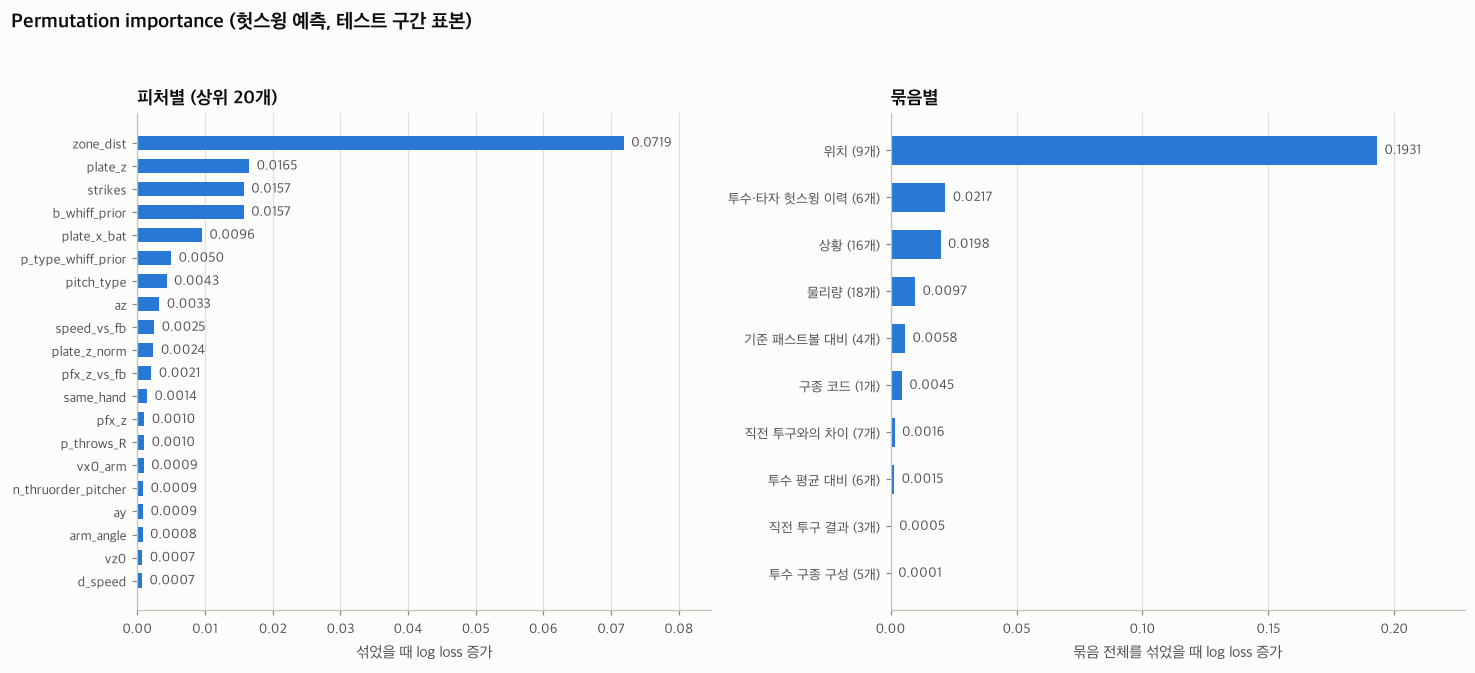

,n_features,importance,std
group,,,
location,9,0.193,0.002
history_outcome,6,0.022,0.001
context,16,0.020,0.000
physics,18,0.010,0.000
fastball_relative,4,0.006,0.000
pitch_type,1,0.004,0.000
prev_physics,7,0.002,0.000
pitcher_relative,6,0.001,0.000
prev_outcome,3,0.000,0.000


,importance,std
zone_dist,0.072,0.001
plate_z,0.017,0.001
strikes,0.016,0.001
b_whiff_prior,0.016,0.000
plate_x_bat,0.010,0.000
p_type_whiff_prior,0.005,0.000
pitch_type,0.004,0.000
az,0.003,0.000
speed_vs_fb,0.003,0.000
plate_z_norm,0.002,0.000


In [91]:
X_te_r, y_te_r = X_te.reset_index(drop=True), y_te.reset_index(drop=True)
perm = interpret.permutation_table(final, X_te_r, y_te_r, scoring="neg_log_loss")
group_defs = {**F.FEATURE_GROUPS, "pitch_type": ["pitch_type"]}
perm_group = interpret.group_permutation_table(final, X_te_r, y_te_r, group_defs, scoring="neg_log_loss")

GROUP_LABELS = {"location": "위치", "physics": "물리량", "history_outcome": "투수·타자 헛스윙 이력", "context": "상황", "pitcher_mix": "투수 구종 구성",
                "fastball_relative": "기준 패스트볼 대비", "pitcher_relative": "투수 평균 대비", "prev_physics": "직전 투구와의 차이",
                "prev_outcome": "직전 투구 결과", "pitch_type": "구종 코드"}
fig, axes = plt.subplots(1, 2, figsize=(13.5, 6.2), gridspec_kw={"width_ratios": [1, 1]})
top = perm.head(20)
plotting.hbar(axes[0], top.index, top["importance"], fmt="{:.4f}")
axes[0].set_xlabel("섞었을 때 log loss 증가")
axes[0].set_title("피처별 (상위 20개)")
plotting.hbar(axes[1], [f"{GROUP_LABELS[g]} ({int(n)}개)" for g, n in zip(perm_group.index, perm_group["n_features"])], perm_group["importance"], fmt="{:.4f}")
axes[1].set_xlabel("묶음 전체를 섞었을 때 log loss 증가")
axes[1].set_title("묶음별")
fig.suptitle("Permutation importance (헛스윙 예측, 테스트 구간 표본)", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plotting.save(fig, "05_permutation_importance")
plt.show()
display(perm_group.round(5))
perm.head(20).round(5)

### 9-2. Partial dependence

다른 입력을 그대로 두고 한 피처만 바꿨을 때 평균 예측 확률이 어떻게 변하는지 본다.

**읽을 때 주의**: 이 모델에는 서로에게서 계산된 피처가 많다(예: `zone_dist`와 `zone_dist_norm`, `plate_z`와 `plate_z_norm`, `pfx_z`와 `pfx_z_vs_fb`). partial dependence는 나머지를 고정한 채 한 컬럼만 움직이므로, 실제로는 함께 움직이는 값들이 따로 논다. 그래서 아래 곡선은 "그 컬럼 하나에 대한 모델의 민감도"로 읽어야 하고, 현실의 인과 효과로 읽으면 안 된다.

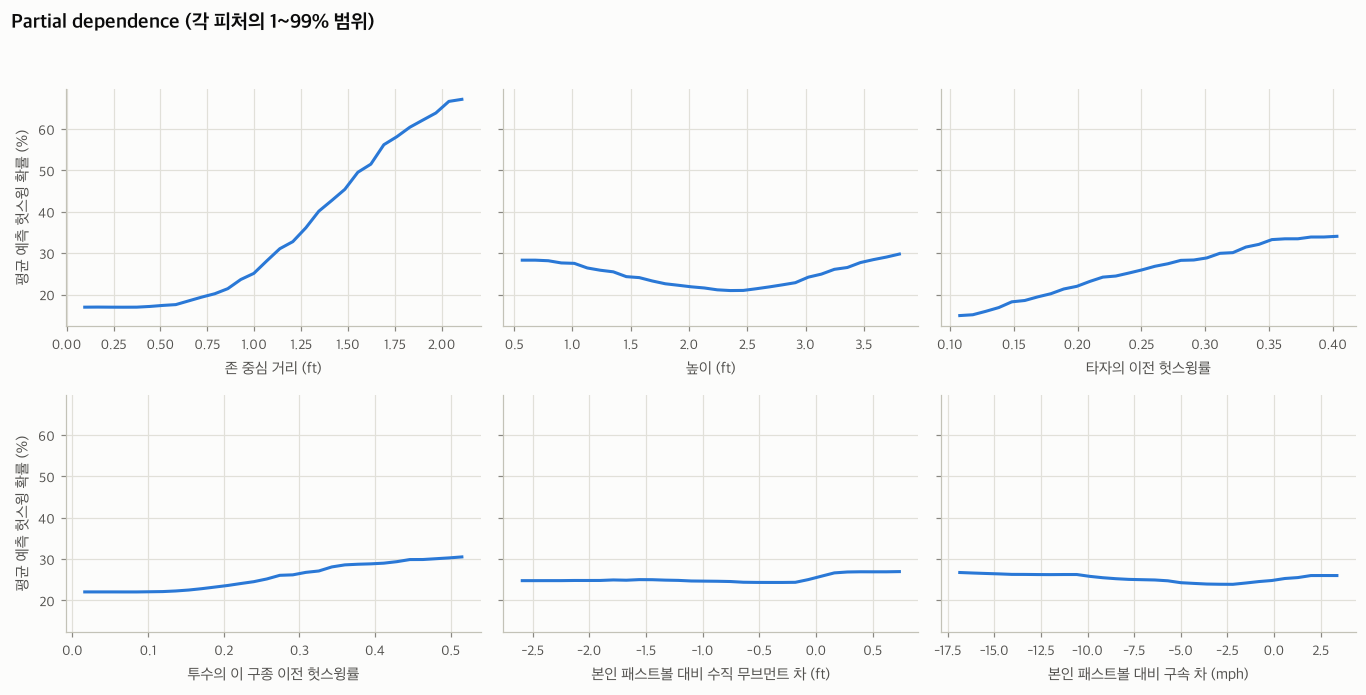

,최소,최대,범위
zone_dist,0.169,0.672,0.503
plate_z,0.210,0.298,0.088
b_whiff_prior,0.149,0.341,0.192
p_type_whiff_prior,0.221,0.305,0.085
pfx_z_vs_fb,0.244,0.270,0.026
speed_vs_fb,0.239,0.268,0.029


In [92]:
PDP_FEATURES = [
    ("zone_dist", "존 중심 거리 (ft)"),
    ("plate_z", "높이 (ft)"),
    ("b_whiff_prior", "타자의 이전 헛스윙률"),
    ("p_type_whiff_prior", "투수의 이 구종 이전 헛스윙률"),
    ("pfx_z_vs_fb", "본인 패스트볼 대비 수직 무브먼트 차 (ft)"),
    ("speed_vs_fb", "본인 패스트볼 대비 구속 차 (mph)"),
]
fig, axes = plt.subplots(2, 3, figsize=(12.5, 6.4), sharey=True)
pdp_tables = {}
for ax, (feature, label) in zip(axes.ravel(), PDP_FEATURES):
    t = interpret.pdp_1d(final, X_te_r, feature)
    pdp_tables[feature] = t
    ax.plot(t["value"], t["prediction"] * 100, color=plotting.BLUE)
    ax.set_xlabel(label)
for ax in axes[:, 0]:
    ax.set_ylabel("평균 예측 헛스윙 확률 (%)")
fig.suptitle("Partial dependence (각 피처의 1~99% 범위)", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plotting.save(fig, "05_partial_dependence")
plt.show()
pd.DataFrame({f: [t["prediction"].min(), t["prediction"].max(), t["prediction"].max() - t["prediction"].min()] for f, t in pdp_tables.items()}, index=["최소", "최대", "범위"]).T.round(4)

### 9-3. 위치별 예측과 실제

위치에 대해서는 partial dependence 대신, 실제로 그 위치에 들어온 스윙들의 **실제 헛스윙률**과 **평균 예측 확률**을 나란히 놓는다. 좌우는 타자 기준이다(왼쪽이 몸쪽).

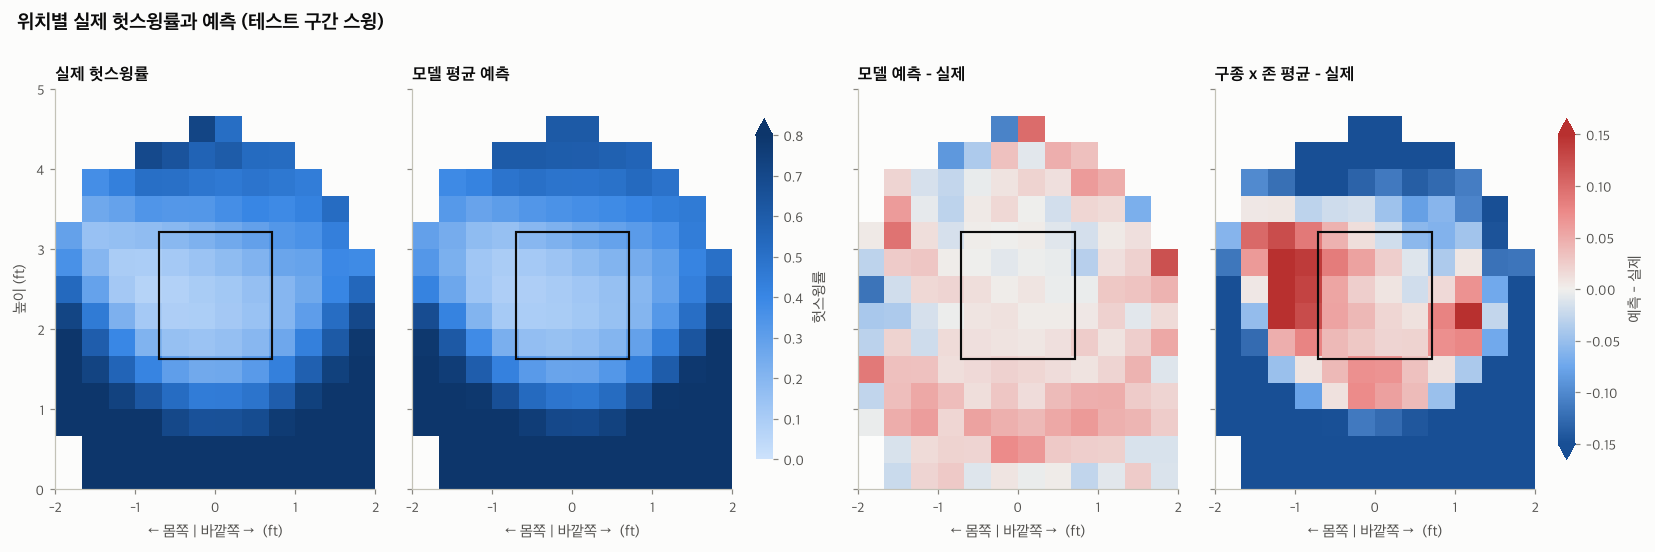

칸별 |예측 - 실제| 평균: 모델 0.0259 / 구종 x 존 평균 0.1618 (스윙 25개 이상인 칸 144개)


In [93]:
BIN_FT, MIN_N, VMAX = 1 / 3, 25, 0.8
x_edges, z_edges = np.arange(-2, 2 + 1e-9, BIN_FT), np.arange(0, 5 + 1e-9, BIN_FT)
obs, _ = E.binned_mean_2d(X_te["plate_x_bat"], X_te["plate_z"], y_te, x_edges, z_edges, MIN_N)
prd, _ = E.binned_mean_2d(X_te["plate_x_bat"], X_te["plate_z"], preds[FINAL], x_edges, z_edges, MIN_N)
ref, _ = E.binned_mean_2d(X_te["plate_x_bat"], X_te["plate_z"], preds[REFERENCE], x_edges, z_edges, MIN_N)
sz_bot, sz_top = X_te["sz_bot"].mean(), X_te["sz_top"].mean()
extent = (x_edges[0], x_edges[-1], z_edges[0], z_edges[-1])

fig, axes = plt.subplots(1, 4, figsize=(15, 4.9), sharey=True, layout="constrained")
panels = [("실제 헛스윙률", obs, plotting.SEQ_CMAP, 0, VMAX), ("모델 평균 예측", prd, plotting.SEQ_CMAP, 0, VMAX),
          ("모델 예측 - 실제", prd - obs, plotting.DIV_CMAP, -0.15, 0.15), (f"{REFERENCE} - 실제", ref - obs, plotting.DIV_CMAP, -0.15, 0.15)]
images = []
for ax, (title, grid, cmap, vmin, vmax) in zip(axes, panels):
    images.append(ax.imshow(grid, origin="lower", extent=extent, cmap=cmap, vmin=vmin, vmax=vmax, aspect="equal"))
    plotting.draw_zone(ax, sz_bot, sz_top)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("← 몸쪽 | 바깥쪽 →  (ft)")
    ax.grid(visible=False)
axes[0].set_ylabel("높이 (ft)")
c1 = fig.colorbar(images[1], ax=axes[:2], fraction=0.03, pad=0.02, extend="max", shrink=0.85); c1.set_label("헛스윙률"); c1.outline.set_visible(False)
c2 = fig.colorbar(images[3], ax=axes[2:], fraction=0.03, pad=0.02, extend="both", shrink=0.85); c2.set_label("예측 - 실제"); c2.outline.set_visible(False)
fig.suptitle("위치별 실제 헛스윙률과 예측 (테스트 구간 스윙)", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.get_layout_engine().set(rect=(0, 0, 1, 0.96))
plotting.save(fig, "05_location_pred_vs_actual")
plt.show()
print(f"칸별 |예측 - 실제| 평균: 모델 {np.abs(prd - obs).mean():.4f} / {REFERENCE} {np.abs(ref - obs).mean():.4f} (스윙 {MIN_N}개 이상인 칸 {int((~obs.mask).sum())}개)")

### 9-4. 투수 단위로 본 예측과 실제

투수별로 테스트 구간의 평균 예측 확률과 실제 헛스윙률을 비교한다. 점이 대각선에 가까우면 투수 수준에서도 예측이 맞는다는 뜻이다.

테스트 구간 스윙 100개 이상 투수 625명
  실제 헛스윙률과의 상관: 모델 0.868 / 구종 x 존 평균 0.553
  평균 절대 오차        : 모델 0.0208 / 구종 x 존 평균 0.0350


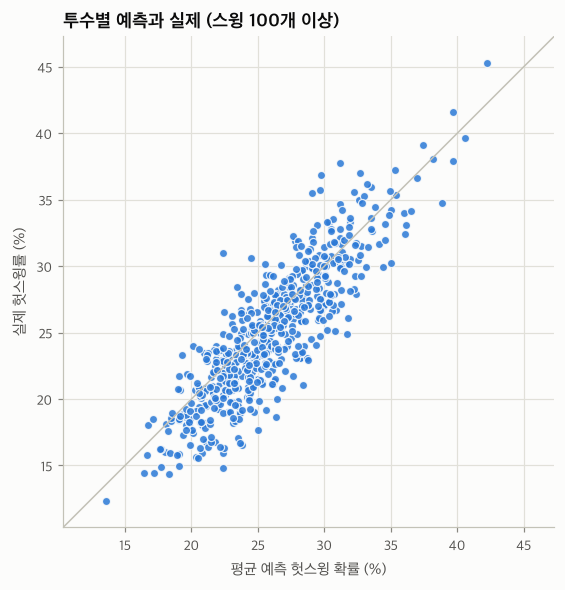

In [94]:
MIN_SWINGS = 100 if not cfg.PILOT_MODE else 40
res = meta_te.assign(pred=preds[FINAL], ref=preds[REFERENCE], y=y_te.to_numpy())
by_p = res.groupby(["pitcher", "player_name"]).agg(swings=("y", "size"), actual=("y", "mean"), predicted=("pred", "mean"), baseline=("ref", "mean")).reset_index()
by_p = by_p[by_p["swings"] >= MIN_SWINGS]
corr_model = np.corrcoef(by_p["predicted"], by_p["actual"])[0, 1]
corr_ref = np.corrcoef(by_p["baseline"], by_p["actual"])[0, 1]
mae_model = (by_p["predicted"] - by_p["actual"]).abs().mean()
mae_ref = (by_p["baseline"] - by_p["actual"]).abs().mean()
print(f"테스트 구간 스윙 {MIN_SWINGS}개 이상 투수 {len(by_p)}명")
print(f"  실제 헛스윙률과의 상관: 모델 {corr_model:.3f} / {REFERENCE} {corr_ref:.3f}")
print(f"  평균 절대 오차        : 모델 {mae_model:.4f} / {REFERENCE} {mae_ref:.4f}")

fig, ax = plt.subplots(figsize=(5.8, 5.8))
lim = (min(by_p["predicted"].min(), by_p["actual"].min()) * 100 - 2, max(by_p["predicted"].max(), by_p["actual"].max()) * 100 + 2)
ax.plot(lim, lim, color=plotting.AXIS, linewidth=1)
ax.scatter(by_p["predicted"] * 100, by_p["actual"] * 100, s=28, color=plotting.BLUE, edgecolor=plotting.SURFACE, linewidth=0.8, alpha=0.85)
ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
ax.set_xlabel("평균 예측 헛스윙 확률 (%)")
ax.set_ylabel("실제 헛스윙률 (%)")
ax.set_title(f"투수별 예측과 실제 (스윙 {MIN_SWINGS}개 이상)")
plotting.save(fig, "05_pitcher_pred_vs_actual")
plt.show()

### 9-5. 투수 사례

테스트 구간에서 스윙을 가장 많이 유도한 투수 3명을 본다. 구종별로 실제 헛스윙률과 모델의 평균 예측을 비교하고, 무브먼트 평면에서 각 공의 예측 확률을 색으로 표시한다(팔 쪽이 +).

스윙  실제_헛스윙률  모델_평균_예측  구종x존_평균  평균_구속
player_name         pitch_type                                        
Alcantara, Sandy    CH          386    0.277     0.293    0.326 90.943
                    CU           57    0.175     0.204    0.240 83.032
                    FC          241    0.241     0.231    0.225 90.144
                    FF          298    0.208     0.201    0.211 97.731
                    SI          443    0.120     0.127    0.137 97.402
                    SL          116    0.259     0.261    0.303 85.122
                    ST          130    0.231     0.253    0.296 84.408
Schlittler, Cam     CU          120    0.442     0.420    0.382 86.205
                    FC          422    0.239     0.226    0.231 94.669
                    FF          750    0.347     0.286    0.248 98.163
                    SI          280    0.168     0.148    0.149 97.919
Sánchez, Cristopher CH          641    0.460     0.403    0.363 87.089
                    SI          663    0.109     0.123    0.138 95.138
                    SL          290    0.431     0.376    0.362 86.581

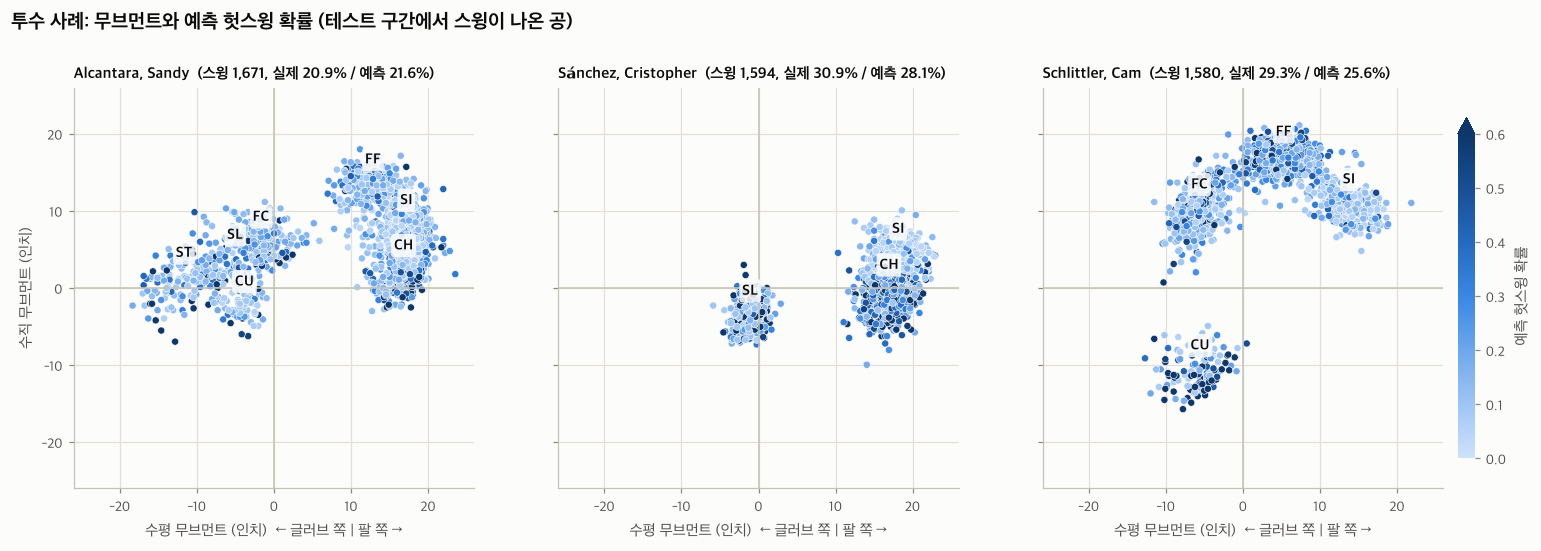

In [95]:
case_ids = by_p.nlargest(3, "swings")["pitcher"].tolist()
case = res[res["pitcher"].isin(case_ids)].join(X_te[["pfx_x_arm", "pfx_z", "release_speed"]])
case_table = case.groupby(["player_name", "pitch_type"]).agg(
    스윙=("y", "size"), 실제_헛스윙률=("y", "mean"), 모델_평균_예측=("pred", "mean"), 구종x존_평균=("ref", "mean"), 평균_구속=("release_speed", "mean")
)
case_table = case_table[case_table["스윙"] >= 10].round(3)
display(case_table)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.9), sharex=True, sharey=True, layout="constrained")
for ax, pid in zip(axes, case_ids):
    sub = case[case["pitcher"] == pid]
    sc = ax.scatter(sub["pfx_x_arm"] * 12, sub["pfx_z"] * 12, c=sub["pred"], cmap=plotting.SEQ_CMAP, vmin=0, vmax=0.6, s=22, edgecolor=plotting.SURFACE, linewidth=0.4)
    ax.axhline(0, color=plotting.AXIS, linewidth=1); ax.axvline(0, color=plotting.AXIS, linewidth=1)
    for pitch, grp in sub.groupby("pitch_type"):
        if len(grp) >= 10:
            ax.annotate(pitch, (grp["pfx_x_arm"].median() * 12, grp["pfx_z"].median() * 12), xytext=(0, 14), textcoords="offset points",
                        ha="center", fontsize=9.5, fontweight="bold", color=plotting.INK,
                        bbox=dict(boxstyle="round,pad=0.2", facecolor=plotting.SURFACE, edgecolor="none", alpha=0.85))
    ax.set_title(f"{sub['player_name'].iloc[0]}  (스윙 {len(sub):,}, 실제 {sub['y'].mean() * 100:.1f}% / 예측 {sub['pred'].mean() * 100:.1f}%)", fontsize=10)
    ax.set_xlim(-26, 26); ax.set_ylim(-26, 26); ax.set_aspect("equal")
    ax.set_xlabel("수평 무브먼트 (인치)  ← 글러브 쪽 | 팔 쪽 →")
axes[0].set_ylabel("수직 무브먼트 (인치)")
cbar = fig.colorbar(sc, ax=axes, fraction=0.02, pad=0.01, extend="max", shrink=0.85)
cbar.set_label("예측 헛스윙 확률"); cbar.outline.set_visible(False)
fig.suptitle("투수 사례: 무브먼트와 예측 헛스윙 확률 (테스트 구간에서 스윙이 나온 공)", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.get_layout_engine().set(rect=(0, 0, 1, 0.96))
plotting.save(fig, "05_case_study_pitchers")
plt.show()

## 10. 결과 저장

In [96]:
out = {
    "mode": cfg.mode_name(),
    "whiff_include_foul_tip": cfg.WHIFF_INCLUDE_FOUL_TIP,
    "train_rows": int(train.sum()), "test_rows": int(test.sum()),
    "train_dates": [str(dates[train].min().date()), str(dates[train].max().date())],
    "test_dates": [str(dates[test].min().date()), str(dates[test].max().date())],
    "test_whiff_rate": float(y_te.mean()), "n_features": int(data.X.shape[1]),
    "best_params": best_params, "reference_baseline": REFERENCE,
    "metrics": metrics_table.reset_index(names="model").to_dict(orient="records"),
    "bootstrap_final_vs_reference": boot.reset_index(names="metric").to_dict(orient="records"),
    "ablation": ablation.reset_index(names="feature_set").to_dict(orient="records"),
    "calibration": {"holdout_ece": holdout_ece, "applied": bool(apply_calibration), "table": cal_table.reset_index(names="model").to_dict(orient="records")},
    "definition_comparison": definition_table.reset_index(names="definition").to_dict(orient="records"),
    "all_pitches": all_table.reset_index(names="model").to_dict(orient="records"),
    "permutation_groups": perm_group["importance"].round(6).to_dict(),
    "permutation_top20": perm["importance"].head(20).round(6).to_dict(),
    "pitcher_level": {"n_pitchers": int(len(by_p)), "min_swings": MIN_SWINGS, "corr_model": corr_model, "corr_reference": corr_ref, "mae_model": mae_model, "mae_reference": mae_ref},
}
path = cfg.metrics_path("05_whiff")
path.parent.mkdir(parents=True, exist_ok=True)
path.write_text(json.dumps(out, indent=1, ensure_ascii=False, default=float), encoding="utf-8")
print("저장:", path.relative_to(ROOT))

저장: reports/metrics/full/05_whiff.json


# 6부. 구종 라벨 없이 레퍼토리 찾기 (클러스터링) (원래 `06_clustering.ipynb`)

**질문**: `pitch_type` 라벨을 전혀 쓰지 않고 물리량만으로 군집을 만들면, 실제 구종 구분을 얼마나 되살릴 수 있는가?

두 가지 수준에서 본다.
1. **리그 전체를 한꺼번에**: 모든 투수의 공을 섞어 구종 수만큼 군집을 만든다.
2. **투수-시즌별로 따로**: 한 투수의 한 시즌 공만 가지고 그 투수의 레퍼토리를 찾는다.

방법은 `GaussianMixture`(군집 수를 BIC로 선택)와 `MiniBatchKMeans`(실루엣 점수로 선택)다. 군집화에는 라벨을 쓰지 않고, 결과를 채점할 때만 쓴다. 로직은 `src/clustering.py`에 있다.

**채점 지표**
- **ARI** (조정 랜드 지수): 무작위면 0, 실제 구종과 완전히 같으면 1
- **homogeneity**: 한 군집 안에 한 구종만 있는 정도. 군집을 잘게 쪼개면 올라간다.
- **completeness**: 한 구종이 한 군집에 모여 있는 정도. 군집을 합치면 올라간다.
- **purity**: 각 군집에 가장 많은 구종의 이름을 붙였을 때 맞는 비율. 군집이 많을수록 유리하다.

In [97]:
%reset -f
# 앞 부의 변수를 모두 비운다 (원래는 노트북마다 새 커널이었다). src 모듈은 그대로 남는다.
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as cfg, plotting
ROOT = cfg.ROOT
import time

from src import clustering as C, datasets
plotting.set_style()
pd.set_option("display.max_columns", 60, "display.width", 220, "display.float_format", "{:,.3f}".format)
print("모드:", cfg.mode_name())

모드: full


## 1. 데이터

물리량이 모두 있고, 한 시즌에 `config.CLUSTER_MIN_PITCHES`구 이상 던진 투수-시즌만 쓴다. 구종 분류에서 뺀 희소 구종(이퍼스, 너클볼 등)도 여기서는 그대로 둔다.

In [98]:
df = datasets.load_features()
rows = C.prepare(df)
units = rows.groupby("unit").agg(투구수=("pitch_type", "size"), 구종수=("pitch_type", C.true_k))
print(f"군집화 대상: {len(rows):,}구 (전체 {len(df):,}구의 {len(rows) / len(df) * 100:.1f}%) | 투수-시즌 {len(units)}개")
print(f"투수-시즌당 투구 수: 중앙값 {units['투구수'].median():.0f}, 최소 {units['투구수'].min()}, 최대 {units['투구수'].max()}")
print(f"사용 피처: {C.CLUSTER_FEATURES}")
print(f"실제로 쓰는 구종 수 (비중 {cfg.CLUSTER_MIN_TYPE_SHARE:.0%} 이상) 분포:")
units["구종수"].value_counts().sort_index().rename("투수-시즌 수").to_frame().T

군집화 대상: 2,700,541구 (전체 2,850,699구의 94.7%) | 투수-시즌 2282개
투수-시즌당 투구 수: 중앙값 967, 최소 300, 최대 3293
사용 피처: ['release_speed', 'pfx_x_arm', 'pfx_z', 'release_spin_rate', 'spin_axis_sin', 'spin_axis_cos']
실제로 쓰는 구종 수 (비중 3% 이상) 분포:


구종수,2,3,4,5,6,7,8,9
투수-시즌 수,129,473,771,625,244,34,5,1


## 2. 리그 전체를 한꺼번에 군집화

투수를 구분하지 않고 모든 공을 구종 분류 대상 클래스 수만큼의 군집으로 나눈다.

In [99]:
K_POOLED = len(cfg.PITCH_CLASSES)
start = time.time()
pooled = C.pooled_clustering(rows, k=K_POOLED)
print(f"{time.time() - start:.1f}초")
pooled

35.0초


,ari,ami,homogeneity,completeness,purity
MiniBatchKMeans (k=10),0.441,0.572,0.609,0.539,0.720
GaussianMixture (k=10),0.283,0.440,0.465,0.418,0.552


## 3. 투수-시즌별 군집화

In [100]:
start = time.time()
results, assignments = C.cluster_all(rows)
print(f"투수-시즌 {results['unit'].nunique()}개 x 방법 {len(C.METHODS)}가지, {time.time() - start:.1f}초")

summary = results.groupby("method").agg(
    ARI_평균=("ari", "mean"), ARI_중앙값=("ari", "median"), AMI_평균=("ami", "mean"),
    homogeneity=("homogeneity", "mean"), completeness=("completeness", "mean"), purity=("purity", "mean"),
    찾은_군집수_평균=("k_found", "mean"), 실제_구종수_평균=("k_true", "mean"),
).loc[list(C.METHODS)]
summary["군집 수가 실제와 같은 비율"] = results.assign(same=results["k_found"] == results["k_true"]).groupby("method")["same"].mean()
summary.index = [C.METHODS[m] for m in summary.index]
summary

투수-시즌 2282개 x 방법 4가지, 131.2초


,ARI_평균,ARI_중앙값,AMI_평균,homogeneity,completeness,purity,찾은_군집수_평균,실제_구종수_평균,군집 수가 실제와 같은 비율
GMM (BIC로 군집 수 선택),0.757,0.782,0.816,0.933,0.741,0.966,6.961,4.223,0.051
KMeans (실루엣으로 군집 수 선택),0.672,0.703,0.750,0.650,0.960,0.786,2.690,4.223,0.230
GMM (실제 구종 수 사용),0.883,0.942,0.897,0.885,0.915,0.940,4.223,4.223,1.000
KMeans (실제 구종 수 사용),0.896,0.952,0.906,0.899,0.915,0.954,4.223,4.223,1.000


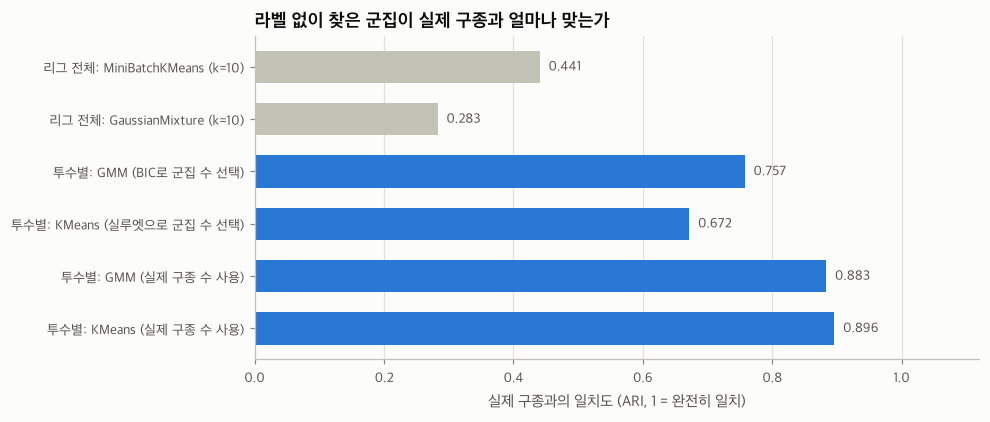

In [101]:
# 리그 전체 군집화와 투수별 군집화를 같은 척도(ARI)로 비교한다.
# 투수별 값은 투수-시즌 평균이라 계산 단위가 다르다는 점에 유의한다.
compare = pd.concat([
    pooled["ari"].rename(lambda s: f"리그 전체: {s}"),
    summary["ARI_평균"].rename(lambda s: f"투수별: {s}"),
])
fig, ax = plt.subplots(figsize=(8.5, 0.42 * len(compare) + 1.3))
plotting.hbar(ax, compare.index, compare.values, colors=[plotting.AXIS if s.startswith("리그") else plotting.BLUE for s in compare.index], fmt="{:.3f}")
ax.set_xlabel("실제 구종과의 일치도 (ARI, 1 = 완전히 일치)")
ax.set_xlim(0, 1.12)
ax.set_title("라벨 없이 찾은 군집이 실제 구종과 얼마나 맞는가")
plotting.save(fig, "06_pooled_vs_pitcher")
plt.show()

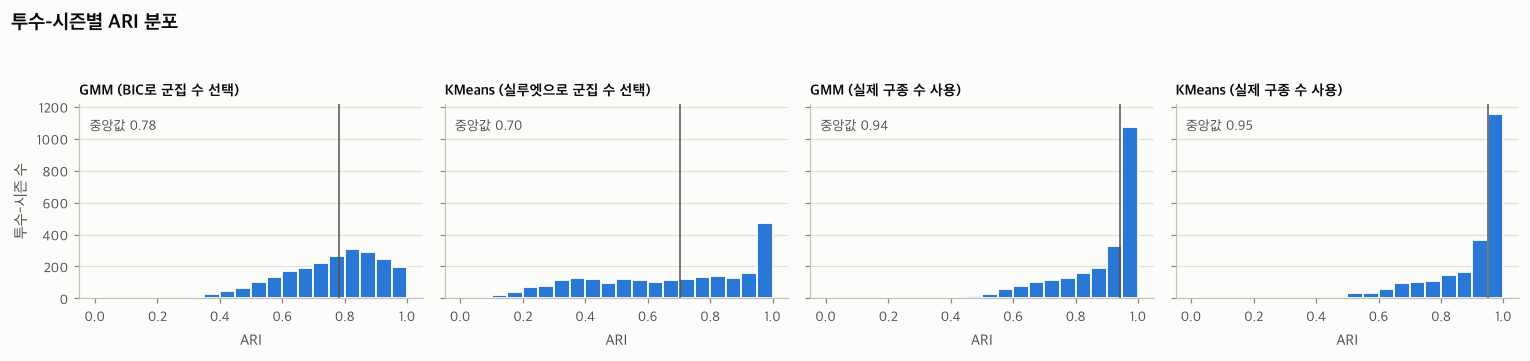

In [102]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.3), sharex=True, sharey=True)
bins = np.arange(0, 1.0001, 0.05)
for ax, (method, label) in zip(axes, C.METHODS.items()):
    values = results.loc[results["method"] == method, "ari"]
    ax.hist(values, bins=bins, color=plotting.BLUE, edgecolor=plotting.SURFACE, linewidth=1.2)
    ax.axvline(values.median(), color=plotting.INK_2, linewidth=1)
    ax.set_title(label, fontsize=9.5)
    ax.text(0.03, 0.93, f"중앙값 {values.median():.2f}", transform=ax.transAxes, fontsize=9, color=plotting.INK_2, va="top")
    ax.set_xlabel("ARI")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("투수-시즌 수")
fig.suptitle("투수-시즌별 ARI 분포", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94))
plotting.save(fig, "06_ari_distribution")
plt.show()

### 군집 수를 제대로 고르는가

찾은 군집 수에서 실제 구종 수를 뺀 값의 분포다. 0이면 정확히 맞힌 것이고, 양수면 너무 잘게 나눈 것, 음수면 뭉친 것이다.

diff,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6
method,,,,,,,,,,,,,,
GMM (BIC로 군집 수 선택),0,0,0,0,0,3,27,116,292,492,652,483,185,32
KMeans (실루엣으로 군집 수 선택),1,5,25,156,361,543,608,525,53,4,1,0,0,0


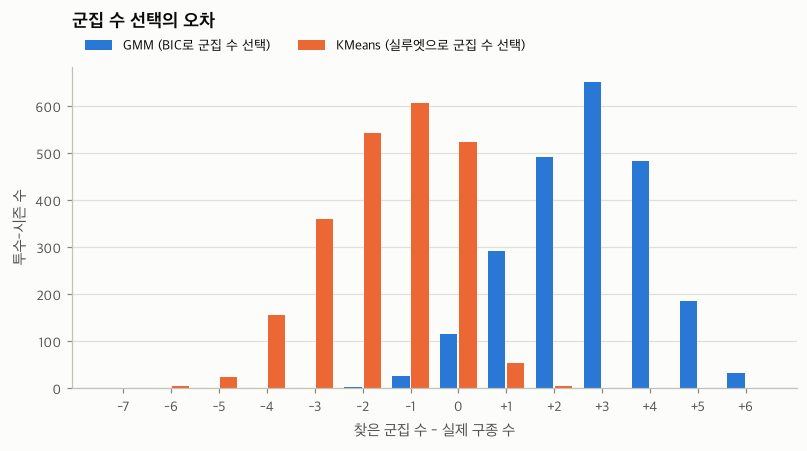

In [103]:
diff = results.assign(diff=results["k_found"] - results["k_true"])
auto = ["gmm_bic", "kmeans_silhouette"]
k_table = pd.crosstab(diff["diff"], diff["method"])[auto]
display(k_table.rename(columns=C.METHODS).T)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
x = np.arange(len(k_table))
for offset, method, color in [(-0.2, "gmm_bic", plotting.BLUE), (0.2, "kmeans_silhouette", plotting.ORANGE)]:
    ax.bar(x + offset, k_table[method], width=0.36, color=color, label=C.METHODS[method])
ax.set_xticks(x, [f"{d:+d}" if d else "0" for d in k_table.index])
ax.set_xlabel("찾은 군집 수 - 실제 구종 수")
ax.set_ylabel("투수-시즌 수")
ax.grid(axis="x", visible=False)
ax.set_title("군집 수 선택의 오차", pad=26)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=2)
plotting.save(fig, "06_k_difference")
plt.show()

## 4. 어떤 구종이 한 군집으로 합쳐지는가

실제 구종 수를 알려 준 GMM(군집 수 선택의 영향을 뺀 상태)에서, 두 구종의 공이 주로 같은 군집에 들어가면 "합쳐졌다"고 센다. 두 구종을 모두 던지는 투수-시즌 중 합쳐진 비율이다. 표본이 적은 쌍은 뺀다.

,구종 쌍,둘 다 던지는 투수-시즌,합쳐진 수,합쳐진 비율
0,FF / SI,1276,513,40.2%
1,KC / ST,41,13,31.7%
2,CU / ST,321,61,19.0%
3,SL / ST,335,63,18.8%
4,FC / SL,375,29,7.7%
5,CU / SL,554,27,4.9%
6,CH / SI,955,42,4.4%
7,FC / FF,760,28,3.7%
8,KC / SL,118,4,3.4%
9,FS / SI,190,2,1.1%


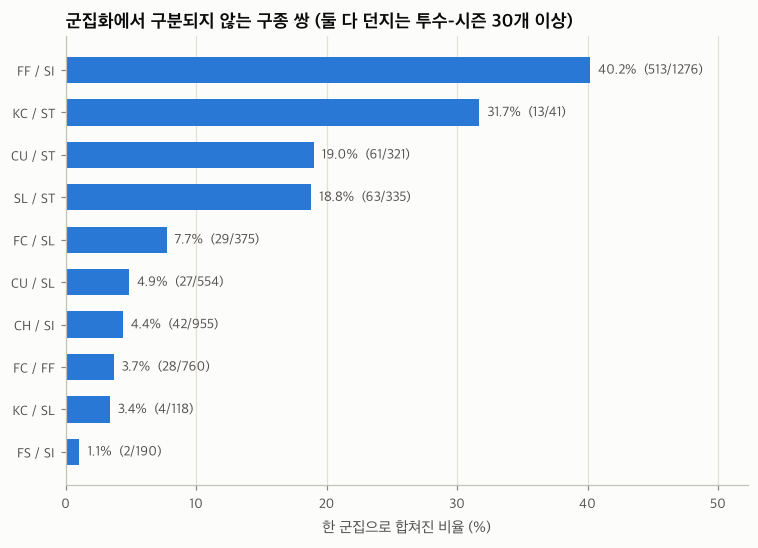

In [104]:
MIN_UNITS = 10 if cfg.PILOT_MODE else 30
pairs = C.merged_pairs(rows, assignments["gmm_oracle"])
pairs = pairs[pairs["둘 다 던지는 투수-시즌"] >= MIN_UNITS].reset_index(drop=True)
top_pairs = pairs.head(10)
display(top_pairs.style.format({"합쳐진 비율": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(8, 0.4 * len(top_pairs) + 1.3))
plotting.hbar(ax, top_pairs["구종 쌍"], top_pairs["합쳐진 비율"] * 100, fmt="{:.1f}%",
              annotations=[f"({m}/{n})" for m, n in zip(top_pairs["합쳐진 수"], top_pairs["둘 다 던지는 투수-시즌"])], xmax_pad=1.3)
ax.set_xlabel("한 군집으로 합쳐진 비율 (%)")
ax.set_title(f"군집화에서 구분되지 않는 구종 쌍 (둘 다 던지는 투수-시즌 {MIN_UNITS}개 이상)")
plotting.save(fig, "06_merged_pairs")
plt.show()

## 5. 투수 사례

GMM(BIC로 군집 수 선택) 결과를 무브먼트 평면에 그린다. 왼쪽은 실제 구종, 오른쪽은 라벨 없이 찾은 군집이다. 군집의 색은 그 군집에 가장 많은 구종의 색을 따르고, 군집마다 번호와 그 구종 코드를 적었다. 같은 색의 군집이 둘이면 한 구종을 둘로 쪼갠 것이고, 한 군집에 두 구종이 섞여 있으면 합친 것이다.

투구 수 상위 절반 중에서 일치도가 가장 높은 투수, 중간인 투수, 가장 낮은 투수를 고른다.

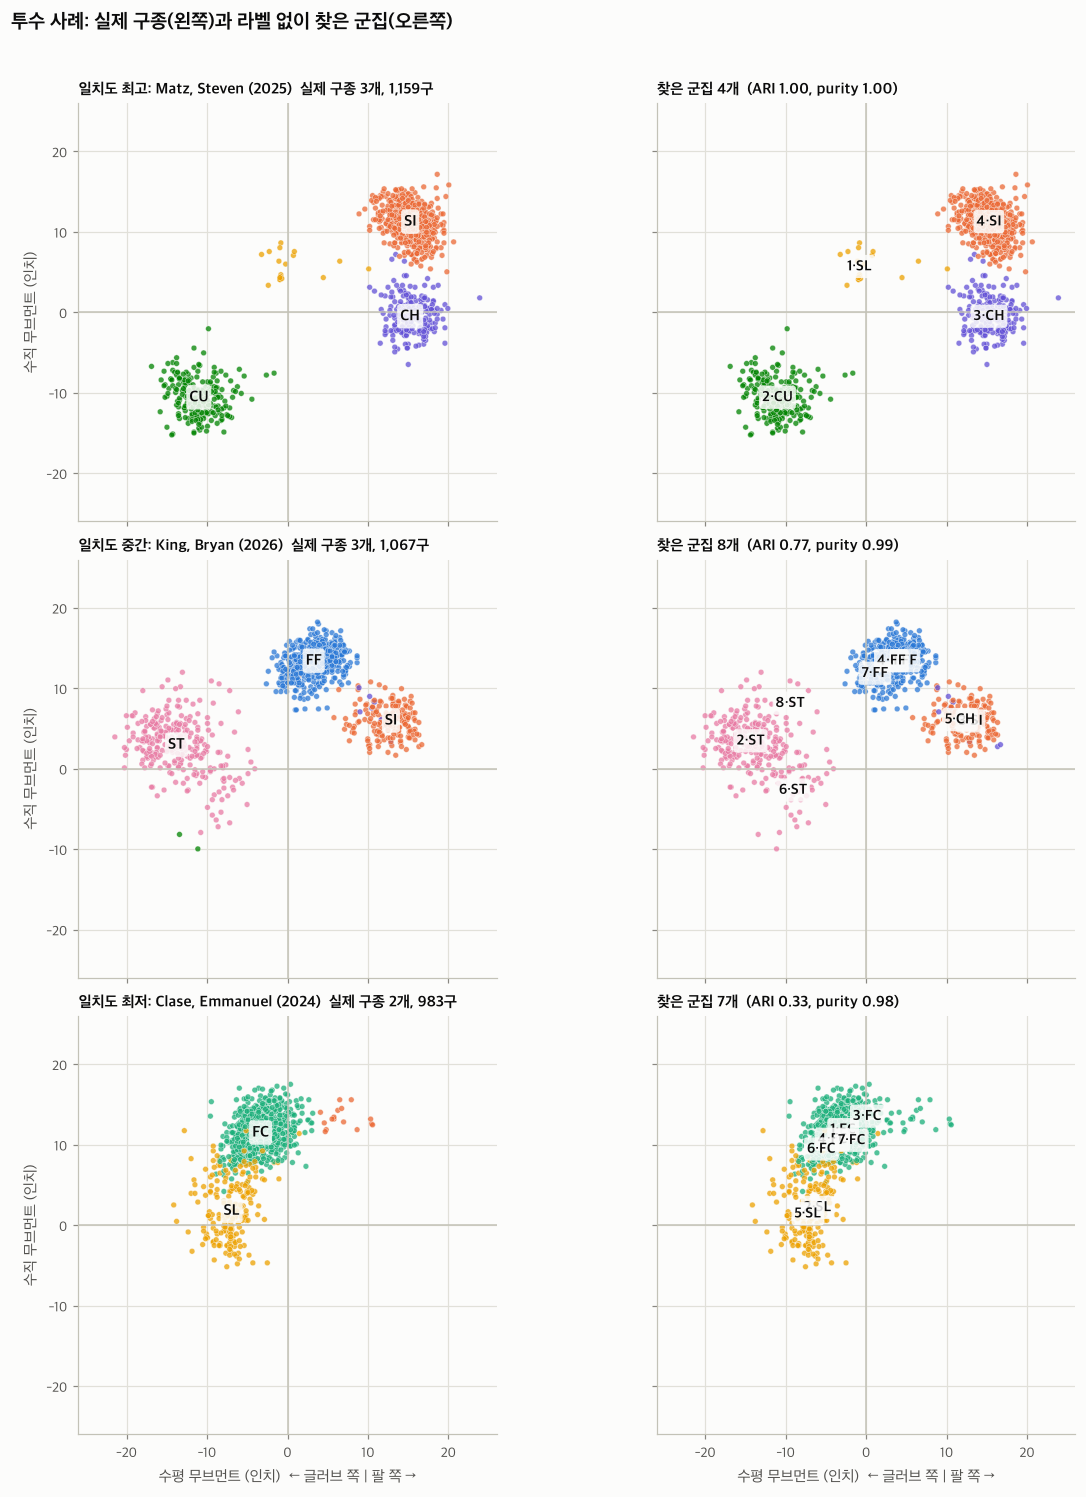

Matz, Steven (2025)


pitch_type,CH,CU,SI,SL
cluster,,,,
군집 1 (SL),0,0,0,18
군집 2 (CU),0,253,0,0
군집 3 (CH),211,0,0,0
군집 4 (SI),0,0,677,0


King, Bryan (2026)


pitch_type,CH,CU,FF,SI,ST
cluster,,,,,
군집 1 (FF),0,0,87,0,0
군집 2 (ST),0,0,0,0,234
군집 3 (SI),0,0,0,176,0
군집 4 (FF),0,0,497,2,0
군집 5 (CH),9,0,0,4,0
군집 6 (ST),0,2,0,0,29
군집 7 (FF),0,0,4,2,0
군집 8 (ST),0,0,0,0,21


Clase, Emmanuel (2024)


pitch_type,FC,SI,SL
cluster,,,
군집 1 (FC),399,0,0
군집 2 (SL),0,0,68
군집 3 (FC),31,13,0
군집 4 (FC),274,3,0
군집 5 (SL),0,0,134
군집 6 (FC),60,0,0
군집 7 (FC),1,0,0


In [105]:
bic = results[results["method"] == "gmm_bic"].sort_values("ari")
busy = bic[bic["n_pitches"] >= bic["n_pitches"].median()].reset_index(drop=True)
picks = [busy.iloc[-1], busy.iloc[len(busy) // 2], busy.iloc[0]]
titles = ["일치도 최고", "일치도 중간", "일치도 최저"]

fig, axes = plt.subplots(3, 2, figsize=(10.5, 13.5), sharex=True, sharey=True, layout="constrained")
case_tables = {}
for row_axes, pick, title in zip(axes, picks, titles):
    idx = rows.index[rows["unit"] == pick["unit"]]
    sub = rows.loc[idx, ["pitch_type", "pfx_x_arm", "pfx_z"]].assign(cluster=assignments.loc[idx, "gmm_bic"].to_numpy())
    major = sub.groupby("cluster")["pitch_type"].agg(lambda s: s.value_counts().index[0])
    case_tables[f"{pick['player_name']} ({pick['season']})"] = pd.crosstab(sub["cluster"].map(lambda c: f"군집 {c + 1} ({major[c]})"), sub["pitch_type"])
    x, y = sub["pfx_x_arm"] * 12, sub["pfx_z"] * 12

    ax = row_axes[0]
    ax.scatter(x, y, c=sub["pitch_type"].map(plotting.pitch_color), s=14, alpha=0.75, edgecolor=plotting.SURFACE, linewidth=0.3)
    for pitch, grp in sub.groupby("pitch_type"):
        if len(grp) / len(sub) >= cfg.CLUSTER_MIN_TYPE_SHARE:
            ax.annotate(pitch, (grp["pfx_x_arm"].median() * 12, grp["pfx_z"].median() * 12), ha="center", va="center", fontsize=10, fontweight="bold", color=plotting.INK,
                        bbox=dict(boxstyle="round,pad=0.2", facecolor=plotting.SURFACE, edgecolor="none", alpha=0.85))
    ax.set_title(f"{title}: {pick['player_name']} ({pick['season']})  실제 구종 {pick['k_true']}개, {pick['n_pitches']:,}구", fontsize=10)

    ax = row_axes[1]
    ax.scatter(x, y, c=sub["cluster"].map(major).map(plotting.pitch_color), s=14, alpha=0.75, edgecolor=plotting.SURFACE, linewidth=0.3)
    for cluster, grp in sub.groupby("cluster"):
        ax.annotate(f"{cluster + 1}·{major[cluster]}", (grp["pfx_x_arm"].median() * 12, grp["pfx_z"].median() * 12), ha="center", va="center", fontsize=9.5, fontweight="bold", color=plotting.INK,
                    bbox=dict(boxstyle="round,pad=0.2", facecolor=plotting.SURFACE, edgecolor="none", alpha=0.85))
    ax.set_title(f"찾은 군집 {pick['k_found']}개  (ARI {pick['ari']:.2f}, purity {pick['purity']:.2f})", fontsize=10)

    for ax in row_axes:
        ax.axhline(0, color=plotting.AXIS, linewidth=1); ax.axvline(0, color=plotting.AXIS, linewidth=1)
        ax.set_xlim(-26, 26); ax.set_ylim(-26, 26); ax.set_aspect("equal")
    row_axes[0].set_ylabel("수직 무브먼트 (인치)")
for ax in axes[-1]:
    ax.set_xlabel("수평 무브먼트 (인치)  ← 글러브 쪽 | 팔 쪽 →")
fig.suptitle("투수 사례: 실제 구종(왼쪽)과 라벨 없이 찾은 군집(오른쪽)", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.get_layout_engine().set(rect=(0, 0, 1, 0.975))
plotting.save(fig, "06_case_study")
plt.show()

for name, case_table in case_tables.items():
    print(name)
    display(case_table)

## 6. 결과 저장

In [106]:
out = {
    "mode": cfg.mode_name(),
    "n_pitches": int(len(rows)), "n_units": int(results["unit"].nunique()),
    "min_pitches": cfg.CLUSTER_MIN_PITCHES, "k_max": cfg.CLUSTER_K_MAX, "features": C.CLUSTER_FEATURES,
    "pooled": pooled.reset_index(names="method").to_dict(orient="records"),
    "per_pitcher": summary.reset_index(names="method").to_dict(orient="records"),
    "k_difference": {C.METHODS[m]: {int(k): int(v) for k, v in k_table[m].items()} for m in auto},
    "merged_pairs": top_pairs.to_dict(orient="records"),
}
path = cfg.metrics_path("06_clustering")
path.parent.mkdir(parents=True, exist_ok=True)
path.write_text(json.dumps(out, indent=1, ensure_ascii=False, default=float), encoding="utf-8")
print("저장:", path.relative_to(ROOT))

저장: reports/metrics/full/06_clustering.json
